# Supplemental figures associated with Figure 3

Unified notebook combining the per-figure supplements (S6, S7, S8, S9) into one
cohesive flow: a single setup at the top, then one section per composite.
Image-selectivity panels are intentionally excluded.

**Structure (run top-to-bottom):**
1. **Setup** — imports, configuration, and the shared data loading: metadata, `metrics_table`,
   and the change/omission/image multi-session dataframes used by S6 and S7. The
   heaviest, single-figure dataframes load later, inside their own sections.
2. **Stats capture** — runtime hooks that write one stats table per composite.
3. **Figure S6** — extended image-change analysis, shared SVM decoding, composite.
4. **Figure S7** — extended omission analysis, composite (reuses the shared SVM).
5. **Figure S8** — familiarization & task engagement: its own image-identity SVM,
   its large dataframes (loaded at the start of the S8 section), then composite.
6. **Figure S9** — running-activity correlation control. Its heavy per-cell
   running-metric preparation runs at the start of the S9 section, then the
   composite. Saves as `figure_S9` alongside the others.

**Notes**
- **Memory:** the top setup loads only the lighter shared data (metadata,
  `metrics_table`, and the S6/S7 change/omission/image dataframes). The largest
  dataframes (S8 passive/active + within-session epochs; S9 running metrics) load
  inside their own sections, and each figure's data is freed (`del`/`gc.collect()`)
  before the next section — so peak memory stays near one figure's worth and the
  notebook can run end-to-end without the earlier OOM crashes.
- Shared SVM `svm_agg` (S6 panel I & S7 panel G) is computed once; S8 recomputes
  `svm_agg` for its own image-identity decode within the S8 section.
- Each composite writes one stats table to
  `<figures>/platform_paper_figures/figure_3_supplemental/composite/figure_SX_composite_stats.csv`.


### Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import seaborn as sns
sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 2})

# Statistical analysis
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
from scipy.stats import chi2

# Data access
from visual_behavior.data_access import loading as loading
import visual_behavior.data_access.utilities as utilities
from allensdk.brain_observatory.behavior.behavior_project_cache import VisualBehaviorOphysProjectCache

# Utilities
import visual_behavior.visualization.utils as utils
import visual_behavior.visualization.ophys.platform_paper_figures as ppf
from scipy import stats
from joblib import Parallel, delayed
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse

# NOTE: %autoreload 2 was removed -- it reloads the entire visual_behavior +
# allensdk module tree before EVERY cell, which destabilizes and kills the
# kernel on these heavy-loading notebooks (dies at a random cell each run). To
# hot-reload just your plotting code while developing, without the crash, use:
#     %load_ext autoreload
#     %autoreload 1
#     %aimport visual_behavior.visualization.ophys.platform_paper_figures
%matplotlib inline

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/xarray/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain 

### Configuration

In [2]:
# When True, skip heavy-duty loading + slow-MLM heatmaps, exposure,
# active/passive, epoch, and image-selectivity analyses (fast iteration).
skip_slow_plots = False

save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_3_supplemental')
folder = 'population_activity'

# Create save directories if they don't exist
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

if not os.path.exists(os.path.join(save_dir, folder)):
    os.makedirs(os.path.join(save_dir, folder))

palette = utils.get_experience_level_colors()
experience_levels = utils.get_new_experience_levels()
experience_level_colors = utils.get_experience_level_colors()
cell_types = utils.get_cell_types()

### Data Loading

#### Metadata tables

In [3]:
# AllenSDK cache
platform_cache_dir = loading.get_platform_analysis_cache_dir()
cache = loading._get_cache()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, 'all_ophys_experiments_table.csv'), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)
behavior_sessions = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_behavior_sessions_table.csv'), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_matched_ophys_cells_table.csv'), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()
palette = utils.get_experience_level_colors()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

#### Load data tables

In [4]:
data_type = 'filtered_events'
session_subset = 'full_session'
inclusion_criteria = 'platform_experiment_table'

metrics_dir = loading.get_cell_metrics_dir()
filepath = os.path.join(metrics_dir, f'merged_model_free_metrics_table_{data_type}_{inclusion_criteria}.csv')
filtered_events_metrics_table = pd.read_csv(filepath, index_col=0)

metrics_table = filtered_events_metrics_table.copy()

# Merge with platform experiments
metrics_table = metrics_table.merge(platform_experiments.reset_index(),
                                   on=['ophys_experiment_id', 'experience_level'])


# # Create event-type specific dataframes
# image_mdf = metrics_table[(metrics_table.event_type == 'images')]
# change_mdf = metrics_table[(metrics_table.event_type == 'changes')]
# omission_mdf = metrics_table[(metrics_table.event_type == 'omissions')]

# # Create each_image specific dataframe
# each_image_mdf = metrics_table[(metrics_table.event_type == 'images') &
#                                (metrics_table.image_id.notna())].copy()

In [5]:
data_type = 'events'
interpolate = True
output_sampling_rate = 30
inclusion_criteria = 'platform_experiment_table'


In [6]:

# Image changes
event_type = 'all'
conditions = ['cell_specimen_id', 'is_change']
is_change_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

change_mdf = is_change_mdf[is_change_mdf.is_change == True]
image_mdf = is_change_mdf[is_change_mdf.is_change == False]

# Omissions
conditions = ['cell_specimen_id', 'omitted']
omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

omission_mdf = omission_mdf[omission_mdf.omitted == True]

# Per image
conditions = ['cell_specimen_id', 'is_change', 'image_name']
each_image_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_image_name_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_image_name_platform_experiment_table.feather
there are 1885 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


## Stats capture for composite figures

Runtime hooks that record the exact statistics each composite computes and write **one `figure_SX_composite_stats.csv` per composite**. Non-invasive (no library-source edits); a kernel restart removes them. See the cell below for details.

In [7]:
# ============================================================================
# Stats capture for the composite figures
# ----------------------------------------------------------------------------
# Records the exact statistics computed while each composite is assembled and
# writes ONE stats table per composite (figure_SX_composite_stats.csv).
#
# The panel functions compute their significance stats through two shared entry
# points: platform_paper_stats.compute_stats (used by add_stats_to_plot / _xaxis
# / _yaxis and by the depth/area MLM heatmaps via _panel_stats_job) and
# add_stats_to_plot_for_hues (used by the by-depth fraction-responsive panels).
# We wrap those two at runtime so every stats table they return is appended to a
# collector, tagged with the metric / cell type inferred from the call. No edits
# are made to the library source -- a kernel restart removes the hooks entirely.
# _run_panel_stats_jobs is forced to run serially so the (otherwise parallel) MLM
# heatmap stats are computed in-process and therefore captured.
#
# Usage: stats_capture_start() runs right before each composite; the composite
# runs unchanged; stats_capture_save(save_dir, 'composite', '<name>_stats')
# runs right after and writes the combined table.
# ============================================================================
import os
import pandas as pd
import visual_behavior.visualization.ophys.platform_paper_figures as ppf

_STATS_CAPTURE = []   # tagged DataFrames collected for the current composite


def _infer_tag(args, kwargs):
    """Recover (metric, cell_type, column_to_compare) from a stats call.
    All capture points take (data, metric, ...) as their first two positionals."""
    data = kwargs.get('data', args[0] if len(args) > 0 else None)
    metric = kwargs.get('metric', args[1] if len(args) > 1 else None)
    compare = kwargs.get('column_to_compare', None)
    cell_type = None
    try:
        if data is not None and hasattr(data, 'columns') and 'cell_type' in data.columns:
            u = pd.Series(data['cell_type']).dropna().unique()
            if len(u) == 1:
                cell_type = u[0]
    except Exception:
        pass
    return metric, cell_type, compare


def _record(stats_table, metric, cell_type, compare, source):
    try:
        if stats_table is None or not hasattr(stats_table, 'copy'):
            return
        st = stats_table.copy()
        if len(st) == 0:
            return
        st.insert(0, '_source_fn', source)
        st.insert(0, '_column_to_compare', compare)
        st.insert(0, '_cell_type', cell_type)
        st.insert(0, '_metric', metric)
        _STATS_CAPTURE.append(st)
    except Exception as e:
        print('stats capture: record failed:', e)


def _install_stats_hooks():
    """(Re)install capture wrappers on the CURRENT ppf functions. Idempotent and
    safe to call after importlib.reload(ppf) (e.g. the S8 SVM cell reloads ppf)."""
    # compute_stats -> returns a single stats-table DataFrame
    if not getattr(ppf.compute_stats, '_stats_capture', False):
        _orig_cs = ppf.compute_stats

        def _cs(*args, **kwargs):
            out = _orig_cs(*args, **kwargs)
            metric, cell_type, compare = _infer_tag(args, kwargs)
            _record(out, metric, cell_type, compare, 'compute_stats')
            return out
        _cs._stats_capture = True
        ppf.compute_stats = _cs

    # add_stats_to_plot_for_hues -> returns (ax, stats_table); doesn't use compute_stats
    if not getattr(ppf.add_stats_to_plot_for_hues, '_stats_capture', False):
        _orig_h = ppf.add_stats_to_plot_for_hues

        def _h(*args, **kwargs):
            out = _orig_h(*args, **kwargs)
            st = out[1] if isinstance(out, tuple) and len(out) > 1 else None
            metric, cell_type, compare = _infer_tag(args, kwargs)
            _record(st, metric, cell_type, compare, 'add_stats_to_plot_for_hues')
            return out
        _h._stats_capture = True
        ppf.add_stats_to_plot_for_hues = _h

    # Capture MLM heatmap stats WITHOUT forcing serial execution. The original
    # runner dispatches the MixedLM fits across cores; forcing it serial (the old
    # approach) made the composite hang. Instead we wrap it: run the parallel
    # version unchanged, then record each returned panel-stats table in-process.
    if not getattr(ppf._run_panel_stats_jobs, '_stats_capture', False):
        _orig_jobs = ppf._run_panel_stats_jobs

        def _capturing_jobs(jobs, n_jobs=None):
            results = _orig_jobs(jobs, n_jobs=n_jobs)
            for job, res in zip(jobs, results):
                st = res[1] if isinstance(res, tuple) and len(res) > 1 else None
                _record(st, job.get('metric'), job.get('cell_type'),
                        job.get('column_to_compare'), '_run_panel_stats_jobs')
            return results
        _capturing_jobs._stats_capture = True
        ppf._run_panel_stats_jobs = _capturing_jobs


def stats_capture_start():
    """Reset the collector and (re)install hooks. Call right before a composite."""
    _STATS_CAPTURE.clear()
    _install_stats_hooks()


def stats_capture_save(save_dir, folder, filename):
    """Concatenate everything captured since the last start() into one CSV."""
    if len(_STATS_CAPTURE) == 0:
        print('stats capture: nothing collected for', filename)
        return None
    combined = pd.concat(_STATS_CAPTURE, ignore_index=True, sort=False)
    outdir = os.path.join(save_dir, folder)
    os.makedirs(outdir, exist_ok=True)
    outpath = os.path.join(outdir, filename + '.csv')
    combined.to_csv(outpath, index=False)
    print(f'stats capture: wrote {len(combined)} rows from {len(_STATS_CAPTURE)} '
          f'panel stat-tables -> {outpath}')
    return combined


_install_stats_hooks()


### Stats CSV outputs

Running each composite writes **one stats table** capturing every panel that performs a statistical test. Files are written next to the composite figures:

| Composite | Output file |
|---|---|
| S6 | `<figures>/platform_paper_figures/figure_3_supplemental/composite/figure_S6_composite_stats.csv` |
| S7 | `<figures>/platform_paper_figures/figure_3_supplemental/composite/figure_S7_composite_stats.csv` |
| S8 | `<figures>/platform_paper_figures/figure_3_supplemental/composite/figure_S8_composite_stats.csv` |
| S9 | `<figures>/platform_paper_figures/figure_3_supplemental/composite/figure_S9_composite_stats.csv` |

Each row is one pairwise/omnibus comparison as computed *during* plotting (the same numbers that drive the significance stars), tagged with leading columns `_metric`, `_cell_type`, `_column_to_compare`, `_source_fn`; remaining columns come from the panel's stats table (group labels, test statistic, p-values, corrected p / reject flags, and the test type via the filename/`STATS_HIERARCHICAL` switch).

**Coverage:** magnitude & modulation-index distributions, fraction-responsive-by-depth, across-cohorts, across-exposures, the depth/area MLM heatmaps, decoding window summaries, and the S9 correlation/RMI distributions. Panels with no formal test (population-average traces, response heatmaps, decoding timecourses, epoch means, S9 change-vs-behavior scatters) produce no rows, by design. The printout after each `stats_capture_save(...)` reports how many rows / panel tables were collected — a `0` there flags a panel whose stats weren't captured.


# Figure S6 — Extended analysis of image-change-related activity

### Change response characterization

Population average responses and single-cell response heatmaps aligned to image
changes across experience levels, split by cohort (single-plane cohorts 1 & 2,
multi-plane cohort 3) and imaging depth. Population averages show the mean ± SEM
calcium event magnitude time-locked to image change onset. Heatmaps display
individual cell responses (rows) across experience levels (columns), sorted by
response strength, separately for matched and unmatched cells. These panels
correspond to PPT Figure S6 panels A-D.

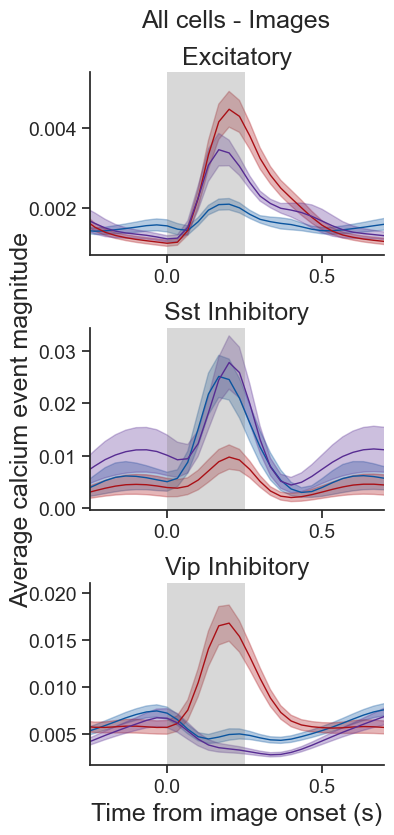

In [8]:
# Cell-matched population averages for images
xlim_seconds = [-0.25, 0.7]

suffix = '_images_all'
axes_column = 'cell_type'
hue_column = 'experience_level'

ax = ppf.plot_population_averages_for_conditions(
    image_mdf, data_type, 'all', axes_column, hue_column,
    horizontal=False, xlabel='Time from image onset (s)',
    ylabel='Average calcium event magnitude', legend=False,
    xlim_seconds=xlim_seconds, interval_sec=0.5,
    palette=palette, ax=None, title=None, suptitle='All cells - Images',
    save_dir=save_dir, folder='population_activity', suffix=suffix)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\ncells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\ncells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\ncells'>,
       <Axes: xlabel='Time from image onset (s)'>, <Axes: >], dtype=object)

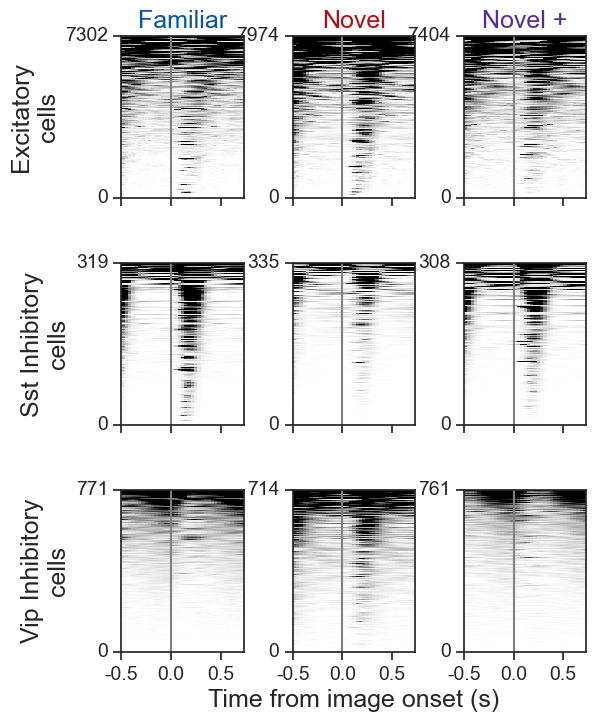

In [9]:

timestamps = image_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(
    image_mdf, timestamps, data_type, 'all', row_condition, col_condition, 
    col_to_sort_by='mean_baseline', suptitle='All cells - Images', exp_to_match='Familiar',
    xlabel='Time from image onset (s)', matched_cells_table=None,
    xlim_seconds=[-0.5, 0.75], match_cells=False, cbar=False, plot_epochs=False,
    save_dir=save_dir, folder='population_activity', suffix='_all_cells_images', ax=None)

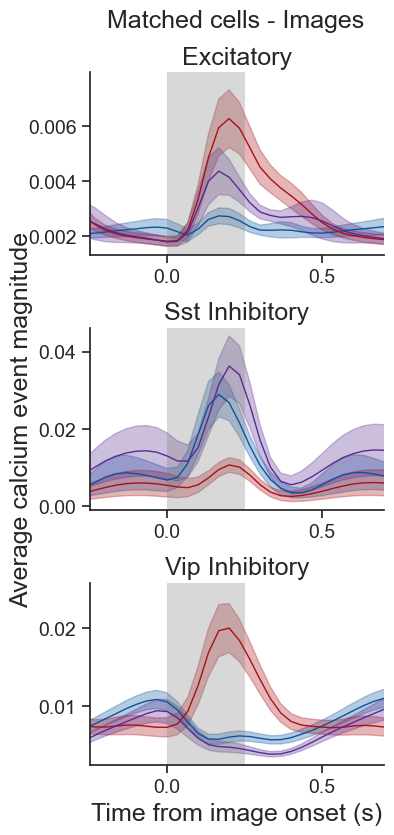

In [10]:
# Cell-matched population averages for images
matched = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(image_mdf)
xlim_seconds = [-0.25, 0.7]

suffix = '_images_matched'
axes_column = 'cell_type'
hue_column = 'experience_level'

ax = ppf.plot_population_averages_for_conditions(
    matched, data_type, 'all', axes_column, hue_column,
    horizontal=False, xlabel='Time from image onset (s)',
    ylabel='Average calcium event magnitude', legend=False,
    xlim_seconds=xlim_seconds, interval_sec=0.5,
    palette=palette, ax=None, title=None, suptitle='Matched cells - Images',
    save_dir=save_dir, folder='population_activity', suffix=suffix)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image onset (s)'>, <Axes: >], dtype=object)

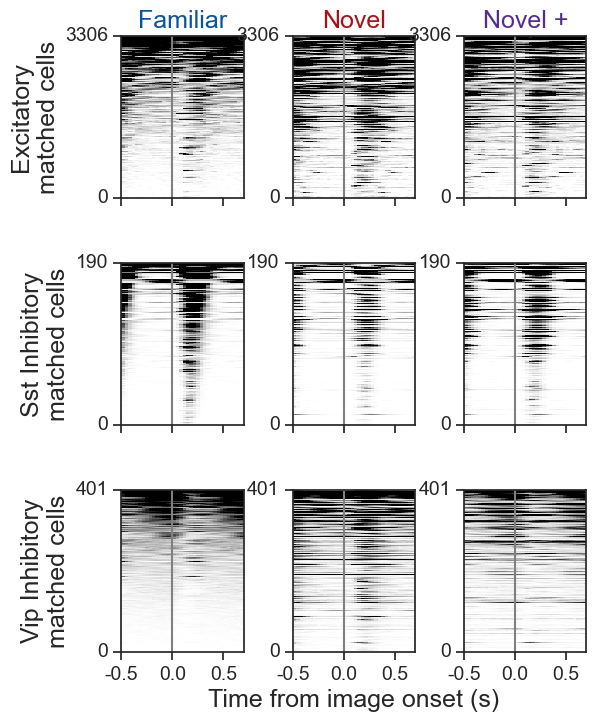

In [11]:
# Cell-matched population averages for images
matched = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(image_mdf)
matched = utilities.limit_to_last_familiar_second_novel_active(matched)

xlim_seconds = [-0.5, 0.7]

timestamps = image_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(
    matched, timestamps, data_type, 'all', row_condition, col_condition, 
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Images', exp_to_match='Familiar',
    xlabel='Time from image onset (s)', matched_cells_table=matched_cells_table,
    xlim_seconds=xlim_seconds, match_cells=True, cbar=False, plot_epochs=False,
    save_dir=save_dir, folder='population_activity', suffix='_matched_cells_images', ax=None)

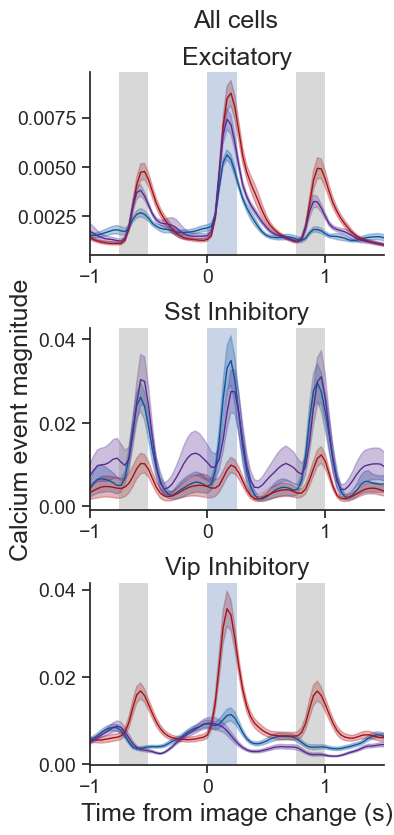

In [12]:
# population averages for changes
xlim_seconds = [-1., 1.5]

suffix = '_changes_all_cells'

ax = ppf.plot_population_averages_for_conditions(
    change_mdf, data_type, 'changes', axes_column, hue_column,
    ylabel='Calcium event magnitude', sharey=False,
    horizontal=False, xlabel='Time from image change (s)',
    xlim_seconds=xlim_seconds, interval_sec=1, legend=False,
    palette=palette, ax=None, title=None, suptitle='All cells',
    save_dir=save_dir, folder='population_activity', suffix=suffix)

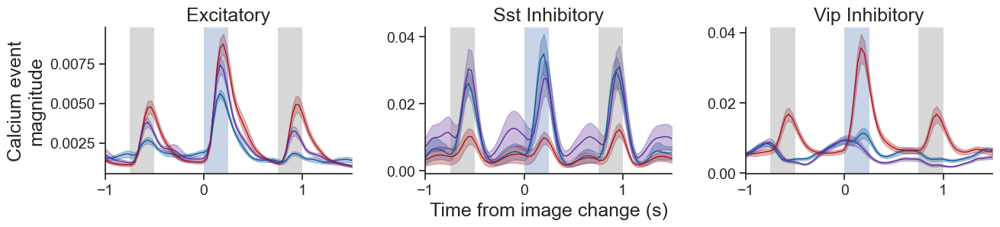

In [13]:
# population averages for changes
xlim_seconds = [-1., 1.5]

suffix = '_changes_all_cells'

ax = ppf.plot_population_averages_for_conditions(
    change_mdf, data_type, 'changes', axes_column, hue_column,
    ylabel='Calcium event\nmagnitude', sharey=False,
    horizontal=True, xlabel='Time from image change (s)',
    xlim_seconds=xlim_seconds, interval_sec=1, legend=False,
    palette=palette, ax=None, title=None, suptitle='',
    save_dir=save_dir, folder='population_activity', suffix=suffix)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\ncells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\ncells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\ncells'>,
       <Axes: xlabel='Time from image change (s)'>, <Axes: >],
      dtype=object)

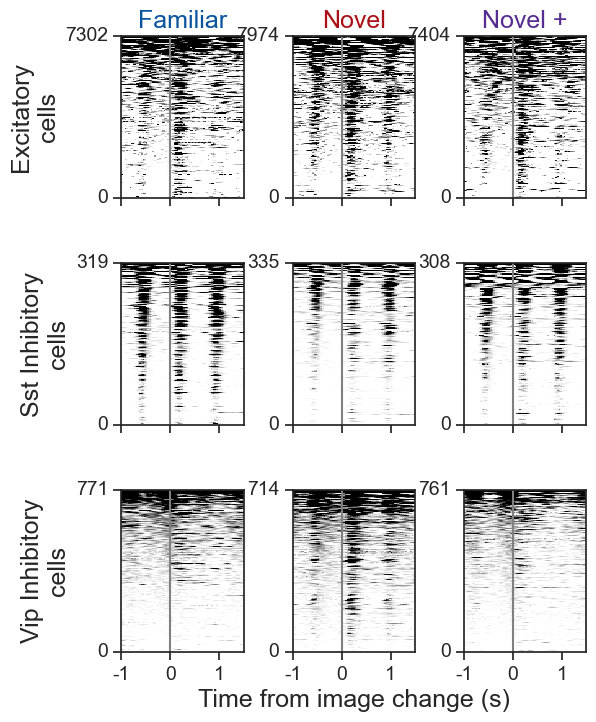

In [14]:

timestamps = change_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(
    change_mdf, timestamps, data_type, 'all', row_condition, col_condition, 
    col_to_sort_by='mean_baseline', suptitle='All cells', exp_to_match='Familiar',
    xlabel='Time from image change (s)', matched_cells_table=None,
    xlim_seconds=[-1, 1.5], match_cells=False, cbar=False, plot_epochs=False,
    save_dir=save_dir, folder='population_activity', suffix='_all', ax=None)

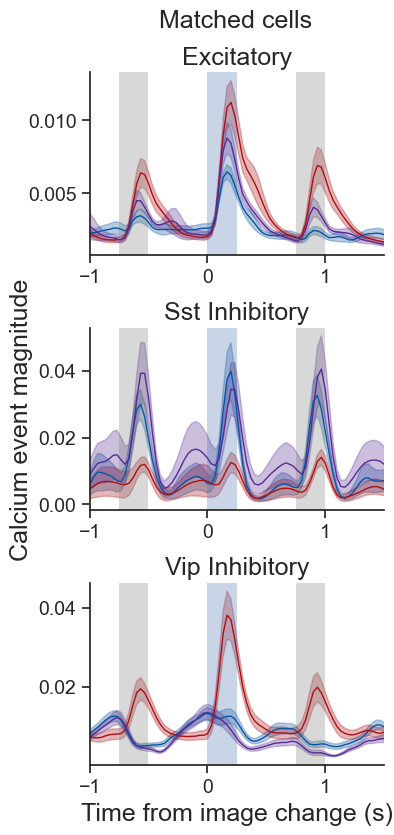

In [15]:
# Cell-matched population averages for changes
matched_changes = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(change_mdf)
xlim_seconds = [-1., 1.5]

suffix = '_changes_matched'

ax = ppf.plot_population_averages_for_conditions(
    matched_changes, data_type, 'changes', axes_column, hue_column,
    ylabel='Calcium event magnitude', sharey=False,
    horizontal=False, xlabel='Time from image change (s)',
    xlim_seconds=xlim_seconds, interval_sec=1, legend=False,
    palette=palette, ax=None, title=None, suptitle='Matched cells',
    save_dir=save_dir, folder='population_activity', suffix=suffix)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image change (s)'>, <Axes: >],
      dtype=object)

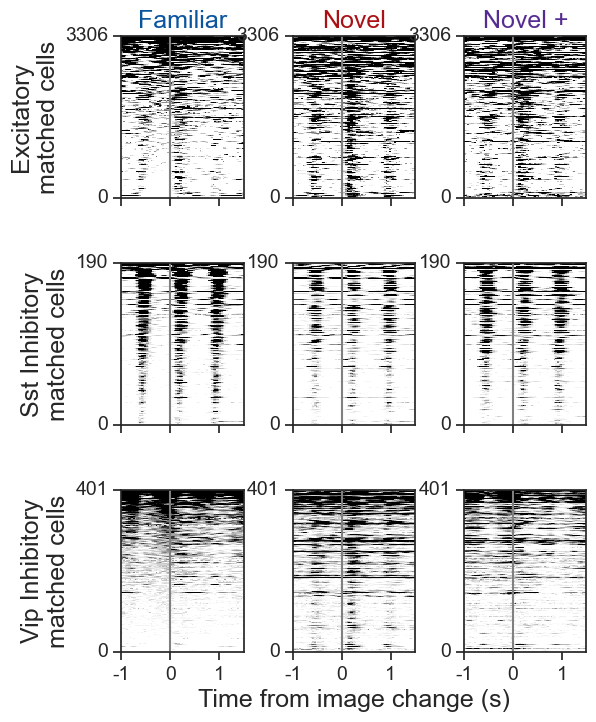

In [16]:
# Cell-matched response heatmaps for images
matched = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(change_mdf)
matched = utilities.limit_to_last_familiar_second_novel_active(matched)

timestamps = change_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(
    matched, timestamps, data_type, 'all', row_condition, col_condition, 
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Images', exp_to_match='Familiar',
    xlabel='Time from image change (s)', matched_cells_table=matched_cells_table,
    xlim_seconds=[-1, 1.5], match_cells=True, cbar=False, plot_epochs=False,
    save_dir=save_dir, folder='population_activity', suffix='_matched', ax=None)

#### Fraction responsive cells

Percentage of cells with significant responses to non-change images, image changes,
and image omissions, across experience levels for each cell type. Responsiveness is
defined as having significantly larger activity during stimulus events compared to
a shuffled distribution from the pre-session gray screen period, for at least 10%
of all events. Also includes fraction responsive split by imaging depth and
cohort. Corresponds to PPT Figure S6 panels E-F and S8 panel K.

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

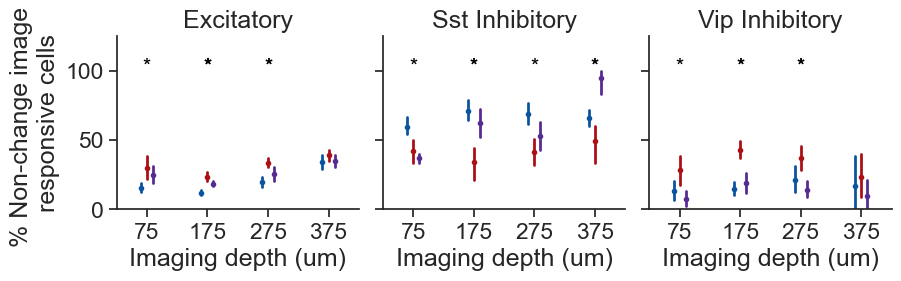

In [17]:
df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)]
fraction_responsive = ppf.get_fraction_responsive_cells(df, conditions=['cell_type', 'experience_level', 'ophys_container_id', 'ophys_experiment_id'],
                                                        responsiveness_threshold=0.1)
fraction_responsive = fraction_responsive.reset_index()
fraction_responsive = fraction_responsive.merge(platform_experiments[['ophys_container_id', 'binned_depth', 'imaging_depth']], on='ophys_container_id')
fraction_responsive = fraction_responsive.drop_duplicates(subset=['ophys_container_id', 'ophys_experiment_id'])
fraction_responsive['percent_responsive'] = fraction_responsive['fraction_responsive']*100

depths = np.sort(fraction_responsive.binned_depth.unique())

cell_types = utils.get_cell_types()
figsize = (10, 2.25)
fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
ax = ax.ravel()
for i, cell_type in enumerate(cell_types): 
    data = fraction_responsive[fraction_responsive.cell_type==cell_type]
    ax[i] = sns.pointplot(data=data,
                    x='binned_depth', y='percent_responsive', hue='experience_level', linestyle='none', order=depths,
                    markers='.', markersize=4, err_kws={'linewidth': 2}, palette=experience_level_colors, dodge=0.2, ax=ax[i])
    ax[i].set_title(cell_type)
    # ax[i].legend(fontsize='xx-small')
    ax[i].get_legend().remove()
    ax[i].set_xlabel('Imaging depth (um)')
    ax[i].set_ylabel('% Non-change image \nresponsive cells')
    ax[i].set_ylim(0, 100)

    ax[i], stats_table = ppf.add_stats_to_plot_for_hues(data, 'percent_responsive', ax[i],
                                                            xorder=depths, x='binned_depth', hue='experience_level')
plt.subplots_adjust(wspace=0.1)

filename = 'percent_nonchange_pref_image_responsive_cells_by_depth'
utils.save_figure(fig, figsize, save_dir, folder, filename)

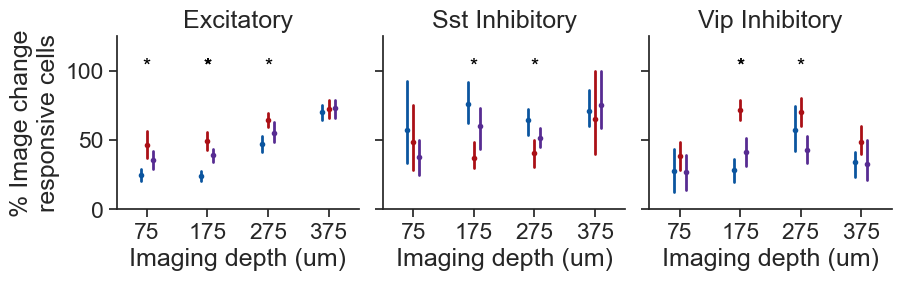

In [18]:
df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==True)]
fraction_responsive = ppf.get_fraction_responsive_cells(df, conditions=['cell_type', 'experience_level', 'ophys_container_id', 'ophys_experiment_id'],
                                                        responsiveness_threshold=0.1)
fraction_responsive = fraction_responsive.reset_index()
fraction_responsive = fraction_responsive.merge(platform_experiments[['ophys_container_id', 'binned_depth', 'imaging_depth']], on='ophys_container_id')
fraction_responsive = fraction_responsive.drop_duplicates(subset=['ophys_container_id', 'ophys_experiment_id'])
fraction_responsive['percent_responsive'] = fraction_responsive['fraction_responsive']*100

depths = np.sort(fraction_responsive.binned_depth.unique())

cell_types = utils.get_cell_types()
figsize = (10, 2.25)
fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
ax = ax.ravel()
for i, cell_type in enumerate(cell_types): 
    data = fraction_responsive[fraction_responsive.cell_type==cell_type]
    ax[i] = sns.pointplot(data=data,
                    x='binned_depth', y='percent_responsive', hue='experience_level', linestyle='none', order=depths,
                    markers='.', markersize=4, err_kws={'linewidth': 2}, palette=experience_level_colors, dodge=0.2, ax=ax[i])
    ax[i].set_title(cell_type)
    # ax[i].legend(fontsize='xx-small')
    ax[i].get_legend().remove()
    ax[i].set_xlabel('Imaging depth (um)')
    ax[i].set_ylabel('% Image change\nresponsive cells')
    ax[i].set_ylim(0, 100)

    ax[i], tukey_table = ppf.add_stats_to_plot_for_hues(data, 'percent_responsive', ax[i],
                                                            xorder=depths, x='binned_depth', hue='experience_level')
plt.subplots_adjust(wspace=0.1)

filename = 'percent_pref_image_change_responsive_cells_by_depth'
utils.save_figure(fig, figsize, save_dir, folder, filename)

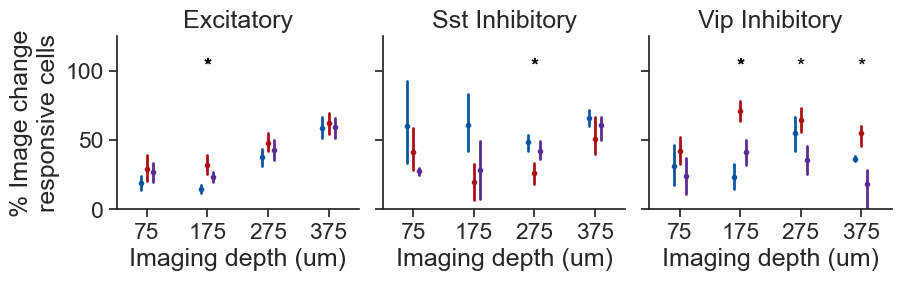

In [19]:
df = change_mdf.copy()

# Also get fraction of responsive cells
fraction_responsive = ppf.get_fraction_responsive_cells(
    df, conditions=['cell_type', 'experience_level', 'ophys_container_id', 'ophys_experiment_id'],
    responsiveness_threshold=0.05)
fraction_responsive = fraction_responsive.reset_index()
fraction_responsive = fraction_responsive.merge(
    platform_experiments[['ophys_container_id', 'binned_depth', 'imaging_depth']],
    on='ophys_container_id')
fraction_responsive = fraction_responsive.drop_duplicates(subset=['ophys_container_id', 'ophys_experiment_id'])
fraction_responsive['percent_responsive'] = fraction_responsive['fraction_responsive'] * 100


# Plot by depth and cell type with statistical annotations
depths = np.sort(fraction_responsive.binned_depth.unique())
figsize = (10, 2.25)
fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
ax = ax.ravel()

for i, cell_type in enumerate(cell_types):
    data = fraction_responsive[fraction_responsive.cell_type == cell_type]
    ax[i] = sns.pointplot(
        data=data, x='binned_depth', y='percent_responsive',
        hue='experience_level', linestyle='none', order=depths,
        markers='.', markersize=4, err_kws={'linewidth': 2},
        palette=experience_level_colors, dodge=0.2, ax=ax[i])
    ax[i].set_title(cell_type)
    ax[i].get_legend().remove()
    ax[i].set_xlabel('Imaging depth (um)')
    ax[i].set_ylabel('% Image change\nresponsive cells')
    ax[i].set_ylim(0, 100)

    # Add statistical annotations to the plot
    ax[i], tukey_table = ppf.add_stats_to_plot_for_hues(
        data, 'percent_responsive', ax[i],
        xorder=depths, x='binned_depth', hue='experience_level')

plt.subplots_adjust(wspace=0.1)
filename = 'percent_change_responsive_cells_by_depth_stats'
utils.save_figure(fig, figsize, save_dir, folder, filename)

#### Change response magnitude

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean image change response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

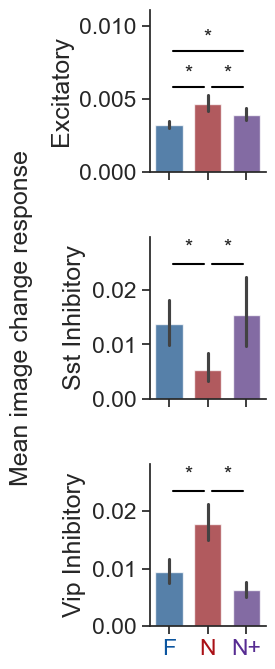

In [20]:
metric = 'mean_response_changes'
ylabel = 'Mean image change response'

event_type = 'changes'

ylims = None #(-0.001, 0.025)

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=ylims, save_dir=save_dir, ax=None)



/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

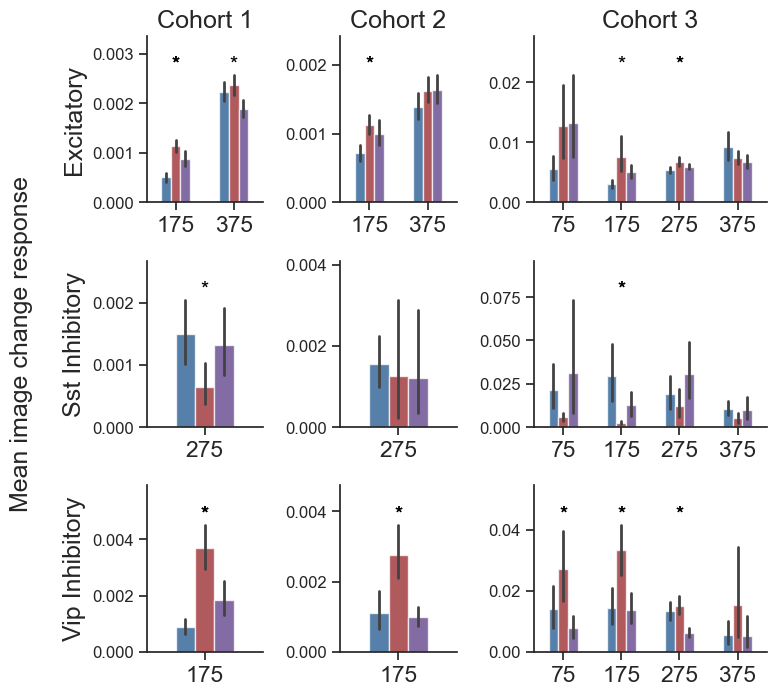

In [21]:
metric = 'mean_response_changes'
ylabel = 'Mean image change response'
x_val = 'binned_depth'
event_type = 'changes'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)


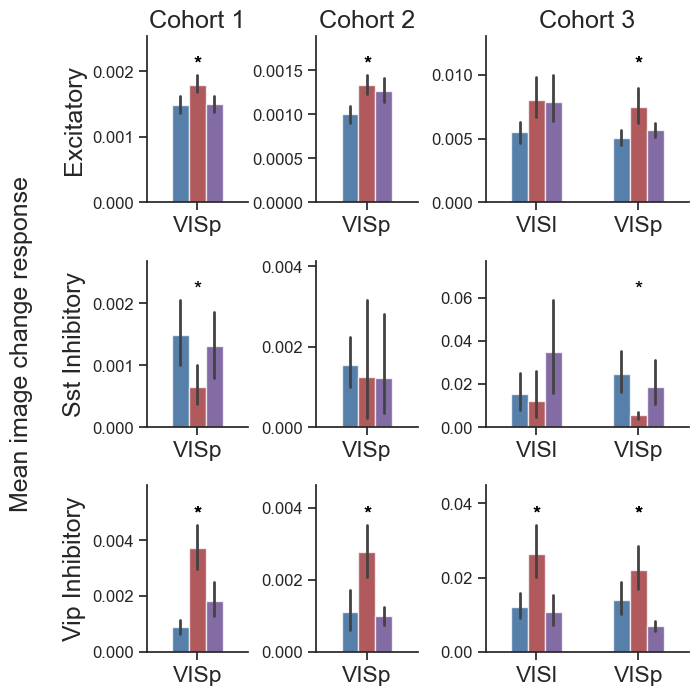

In [22]:
metric = 'mean_response_changes'
ylabel = 'Mean image change response'
x_val = 'targeted_structure'
event_type = 'changes'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean non-change image response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

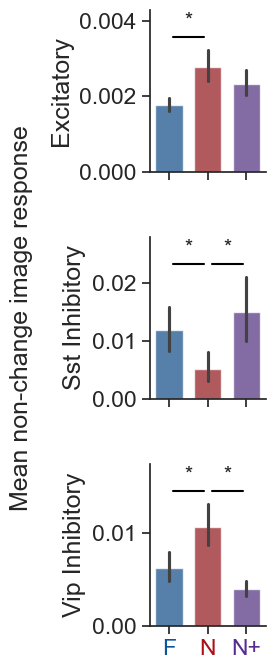

In [23]:
metric = 'mean_response_all_images'
ylabel = 'Mean non-change image response'
event_type = 'images'
ylims = None 

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=ylims, save_dir=save_dir, ax=None)



/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

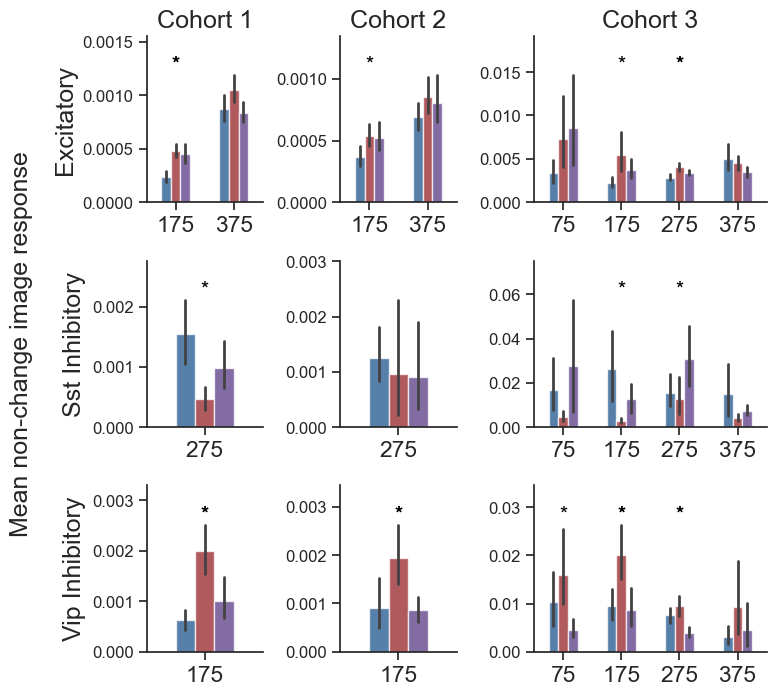

In [24]:
metric = 'mean_response_all_images'
ylabel = 'Mean non-change image response'
event_type = 'images'
x_val = 'binned_depth'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)


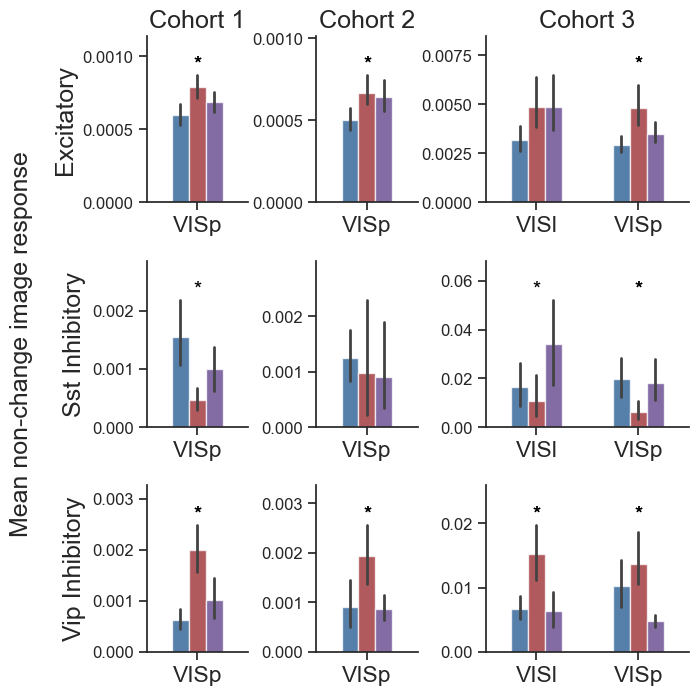

In [25]:
metric = 'mean_response_all_images'
ylabel = 'Mean non-change image response'
event_type = 'images'
x_val = 'targeted_structure'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

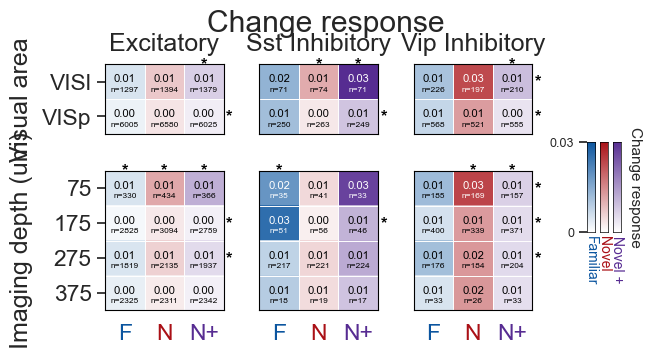

In [26]:
if not skip_slow_plots:
    ax, stats = ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='mean_response_changes', metric_label='Change response',
        save_dir=save_dir, event_type='changes')

In [27]:
metrics_table

,cell_specimen_id,experience_level,ophys_experiment_id,mean_response_pref_image,reliability_pref_image,fraction_significant_p_value_gray_screen_pref_image,fano_factor_pref_image,running_modulation_pref_image,mean_response_all_images,lifetime_sparseness_images,...,layer,area_layer,date,first_novel,n_relative_to_first_novel,last_familiar,last_familiar_active,second_novel,second_novel_active,experience_exposure
0,1086490480,Familiar,795073741,0.000131,0.122168,0.011364,0.011834,1.000000,0.000066,0.348866,...,upper,VISp_upper,20181213,False,-1.0,True,True,False,False,Familiar 3
1,1086490397,Familiar,795073741,0.000961,0.452276,0.000000,0.019686,1.000000,0.000396,0.424478,...,upper,VISp_upper,20181213,False,-1.0,True,True,False,False,Familiar 3
2,1086490510,Familiar,795073741,0.004260,0.183585,0.160149,0.043784,1.000000,0.001107,0.574101,...,upper,VISp_upper,20181213,False,-1.0,True,True,False,False,Familiar 3
3,1086490565,Familiar,795073741,0.000229,0.738372,0.002410,0.013540,1.000000,0.000092,0.374332,...,upper,VISp_upper,20181213,False,-1.0,True,True,False,False,Familiar 3
4,1086490680,Familiar,795073741,0.003442,0.336522,0.072289,0.082742,1.000000,0.001172,0.441491,...,upper,VISp_upper,20181213,False,-1.0,True,True,False,False,Familiar 3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25930,1120120487,Novel +,1087825608,0.043367,0.182861,0.212406,0.338255,0.020770,0.007448,0.860475,...,lower,VISl_lower,20210303,False,2.0,False,False,False,True,Novel 3
25931,1120123643,Novel +,1087825608,0.028697,0.348907,0.276316,0.097014,0.430815,0.016435,0.233390,...,lower,VISl_lower,20210303,False,2.0,False,False,False,True,Novel 3
25932,1120124039,Novel +,1087825608,0.016337,0.223612,0.150376,0.124369,0.140823,0.003944,0.655078,...,lower,VISl_lower,20210303,False,2.0,False,False,False,True,Novel 3
25933,1120126115,Novel +,1087825608,0.001297,0.369498,0.003759,0.102116,0.508134,0.000429,0.470667,...,lower,VISl_lower,20210303,False,2.0,False,False,False,True,Novel 3


#### Change modulation index

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

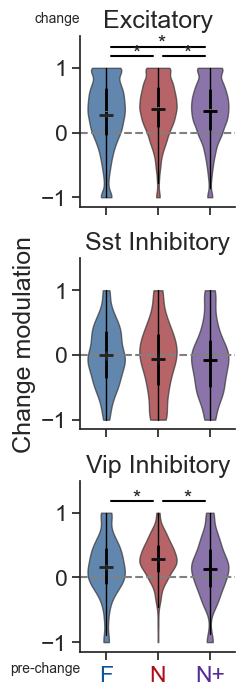

In [28]:
metric = 'change_modulation_index'
xlabel = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, label=xlabel, plot_type='violinplot',
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, suffix='', event_type='changes')


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3671: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, x=x, y=y, orient=orient,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Use

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

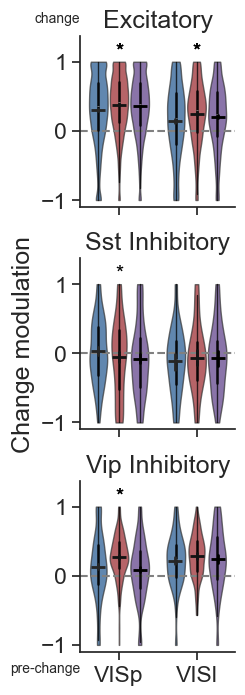

In [29]:
metric = 'change_modulation_index'
label = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
lims = (-1.1, 1.1)

ppf.plot_modulation_index_distribution(metrics_table, metric, x_axis_col='targeted_structure', plot_type='violinplot',
                                       label=label, lims=lims, horiz=False, annot=annot, fill=True,
                                        abbreviate_exp=True, suptitle=None, save_dir=save_dir, suffix='', event_type='changes')

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3671: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, x=x, y=y, orient=orient,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Use

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

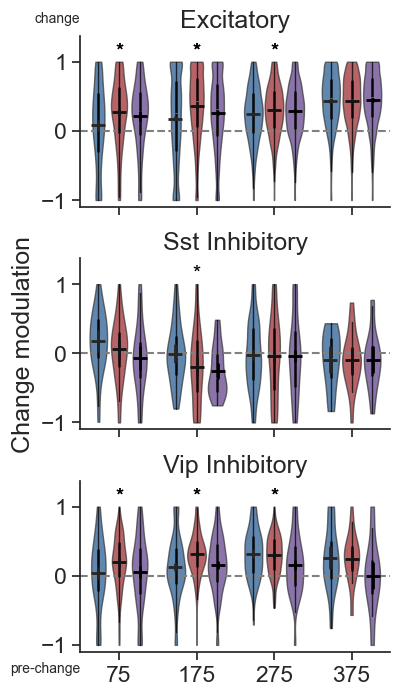

In [30]:
metric = 'change_modulation_index'
label = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
lims = (-1.1, 1.1)

ppf.plot_modulation_index_distribution(metrics_table, metric, x_axis_col='binned_depth', plot_type='violinplot',
                                       label=label, lims=lims, horiz=False, annot=annot, fill=True,
                                    metric_on_y=True, abbreviate_exp=True, suptitle=None, save_dir=save_dir, suffix='', event_type='changes')

#### Area and depth heatmaps

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

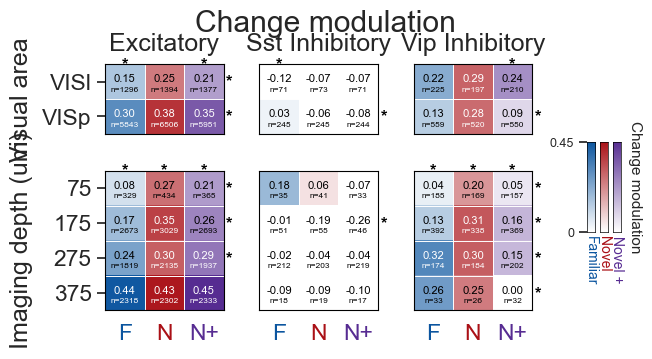

In [31]:
if not skip_slow_plots:
    ax, stats = ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='change_modulation_index', metric_label='Change modulation',
        event_type='changes', save_dir=save_dir)

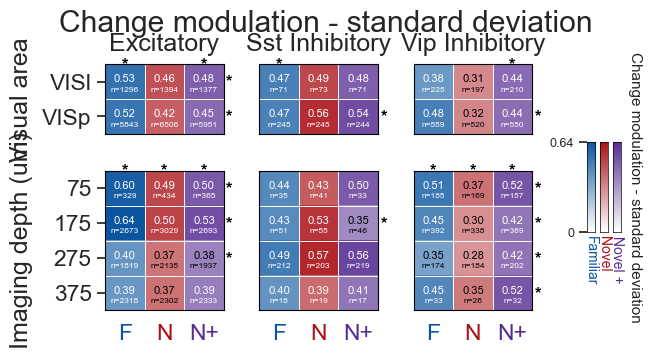

In [32]:
if not skip_slow_plots:
    ax, stats = ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='change_modulation_index', metric_label='Change modulation - standard deviation',
        aggregate='std', save_dir=save_dir, event_type='changes')

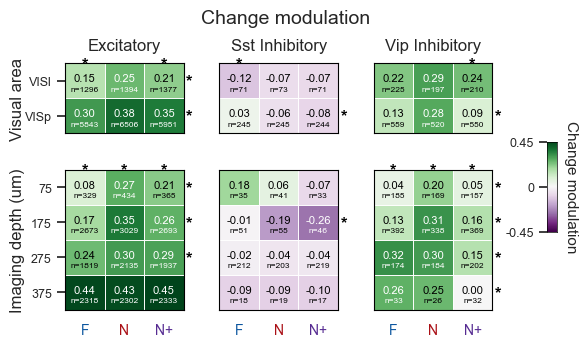

In [33]:
if not skip_slow_plots:
    ax, stats = ppf.plot_bidirectional_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='change_modulation_index', metric_label='Change modulation',
        cmap='PRGn', save_dir=save_dir, event_type='changes'
    )

#### Experience modulation

Quantification of how neural responses change across experience levels. Includes
experience modulation index (computed as the difference in mean response between
two experience levels divided by the sum) for each cell, shown as distributions
per cell type. Also shows mean image change response magnitude across cohorts,
depths, and cortical areas, and the change modulation index (response to image
changes minus response to non-change images, over the sum) split by area and
depth. Corresponds to PPT Figure S6 panels I-N.

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Experience modulation'>],
      dtype=object)

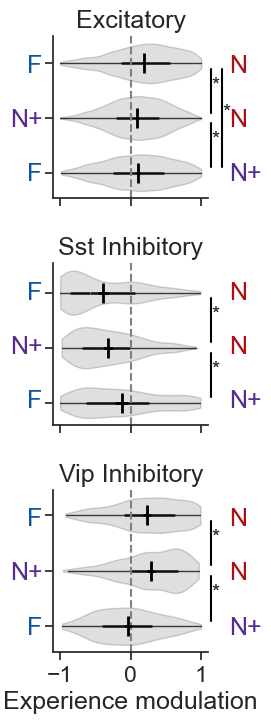

In [34]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated_by_cell_type(image_mdf, event_type, metric, platform_cells_table,
                                                            xlims=(-1.1, 1.1), xlabel=xlabel,
                                                            all_comparisons=True, horiz=False,
                                                            suptitle=None, suffix='', save_dir=None, ax=None)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])


array([<Axes: title={'center': 'Novel vs. Familiar'}>,
       <Axes: title={'center': 'Novel vs. Novel +'}>,
       <Axes: title={'center': 'Novel + vs. Familiar'}, xlabel='Experience modulation'>],
      dtype=object)

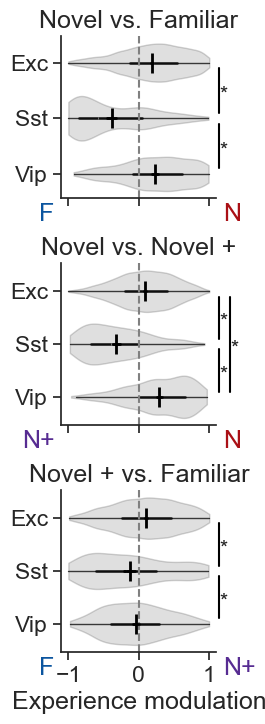

In [35]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated(
    image_mdf, event_type, metric, platform_cells_table,
    horiz=False, xlims=(-1.1, 1.1), xlabel='Experience modulation',
    suffix='_images_modulation', save_dir=save_dir,)

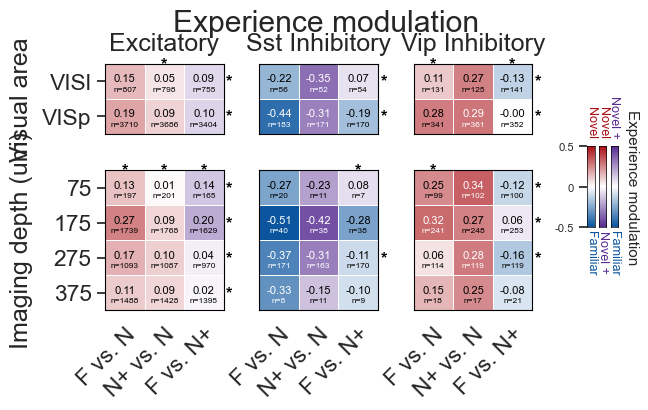

In [36]:
if not skip_slow_plots:
    metric = 'mean_response'
    event_type = 'images'
    xlabel = 'Experience modulation'

    ax, stats = ppf.plot_experience_modulation_heatmap_area_and_depth_by_cell_type(
        image_mdf, event_type=event_type, metric=metric,
        cells_table=platform_cells_table,
        save_dir=save_dir, folder='metric_distributions',
    )

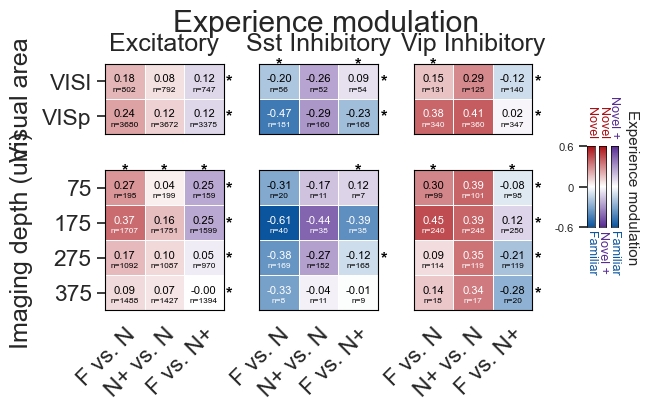

In [37]:
if not skip_slow_plots:
    metric = 'mean_response'
    event_type = 'changes'
    xlabel = 'Experience modulation'

    ax, stats = ppf.plot_experience_modulation_heatmap_area_and_depth_by_cell_type(
        change_mdf, event_type=event_type, metric=metric,
        cells_table=platform_cells_table,
        save_dir=save_dir, folder='metric_distributions',
    )

In [38]:
# ax3, stats_table = ppf.plot_experience_modulation_index_depth_heatmap_by_cell_type(
#     image_mdf, event_type, metric, platform_cells_table,
#     groupby_col='binned_depth', ylabel='Imaging depth (um)')

# ax3, stats_table = ppf.plot_experience_modulation_index_depth_heatmap_by_cell_type(
#     image_mdf, event_type, metric, platform_cells_table,
#     groupby_col='targeted_structure', ylabel='Visual area')


##### Experience vs change modulation 

In [39]:
import visual_behavior.ophys.response_analysis.cell_metrics as cm

metric = 'mean_response'
exp_mod = cm.compute_experience_modulation_index_new(image_mdf, metric, platform_cells_table)
exp_mod = exp_mod.drop_duplicates(subset='cell_specimen_id')

value_vars = ['F N', 'N+ N', 'F N+']
data = exp_mod.melt(id_vars=['cell_specimen_id', 'cell_type'], var_name='comparison', value_vars=value_vars)
titles = ['Novel vs. Familiar', 'Novel vs. Novel +', 'Novel + vs. Familiar']

data.head()

,cell_specimen_id,cell_type,comparison,value
0,1086489847,Vip Inhibitory,F N,0.537837
1,1086489860,Vip Inhibitory,F N,0.480181
2,1086489869,Vip Inhibitory,F N,NaN
3,1086489882,Vip Inhibitory,F N,NaN
4,1086489891,Vip Inhibitory,F N,0.473063


In [40]:

# def plot_modulation_index_correlation(data, x_col, y_col, xlabel, ylabel,
#                             ax=None, save_dir=None, folder=None, filename=None):
#     """
#     Plots the correlation between two modulation indices (e.g., experience modulation index and change modulation index)
#     for each cell type, including a linear best-fit line and Pearson correlation coefficient.

#     Parameters:
#     - data: DataFrame containing the modulation indices and cell types.
#     - x_col: Column name for the x-axis modulation index.
#     - y_col: Column name for the y-axis modulation index.
#     - ax: Matplotlib axis to plot on (optional).
#     - save_dir: Directory to save the figure (optional).
#     - folder: Subfolder within save_dir to save the figure (optional).
#     - filename: Name of the file to save the figure (optional).
#     """

#     import numpy as np
#     from scipy.stats import pearsonr

#     if ax is None: 
#         figsize = (2, 8)
#         fig, ax = plt.subplots(3, 1, figsize=figsize, sharex=True, sharey=True)

#     for i, cell_type in enumerate(cell_types):
#         cell_type_data = df[df.cell_type == cell_type]
#         plot_data = cell_type_data[[x_col, y_col]].dropna()

#         ax[i] = sns.kdeplot(data=plot_data, x=x_col, y=y_col, ax=ax[i])

#         # Add linear best-fit line and Pearson correlation for the plotted x/y values.
#         if len(plot_data) >= 2:
#             x = plot_data[x_col].to_numpy()
#             y = plot_data[y_col].to_numpy()

#             if np.std(x) > 0 and np.std(y) > 0:
#                 r, p = pearsonr(x, y)
#                 slope, intercept = np.polyfit(x, y, 1)
#                 x_fit = np.array([x.min(), x.max()])
#                 y_fit = slope * x_fit + intercept
#                 p_str = f"{p:.2e}" if p < 1e-3 else f"{p:.3f}"
#                 ax[i].plot(x_fit, y_fit, color='black', linestyle='--', linewidth=1.5)
#                 ax[i].set_title(f"{cell_type}\n(r={r:.2f}, p={p_str})")
#             else:
#                 ax[i].set_title(f"{cell_type}\n(r=nan, p=nan)")
#         else:
#             ax[i].set_title(f"{cell_type}\n(r=nan, p=nan)")

#         ax[i].set_ylabel('')

#     ax[2].set_xlabel(xlabel)
#     ax[1].set_ylabel(ylabel)

#     plt.subplots_adjust(hspace=0.4)
#     if save_dir and folder:
#         filename = filename or f"{y_col}_vs_{x_col}_correlation"
#         utils.save_figure(fig, figsize, save_dir, folder, filename)



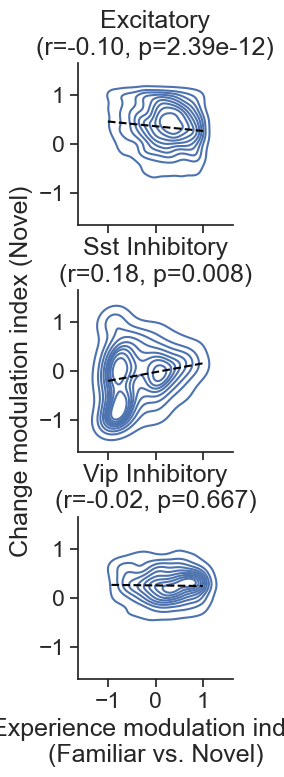

In [41]:

exp_mod_f_n = data[data.comparison=='F N']
change_mod_n = metrics_table[metrics_table.experience_level=='Novel'][['cell_specimen_id', 'change_modulation_index']].merge(exp_mod_f_n)
df = change_mod_n.merge(exp_mod_f_n)
df = df.rename(columns={'value': 'experience_modulation_index'})

x_col = 'experience_modulation_index'
y_col = 'change_modulation_index'

xlabel = 'Experience modulation index \n(Familiar vs. Novel)'
ylabel = 'Change modulation index (Novel)'


ppf.plot_modulation_index_correlation(df, x_col, y_col, xlabel, ylabel,
                            ax=None, save_dir=None, folder=None, filename=None)

                            

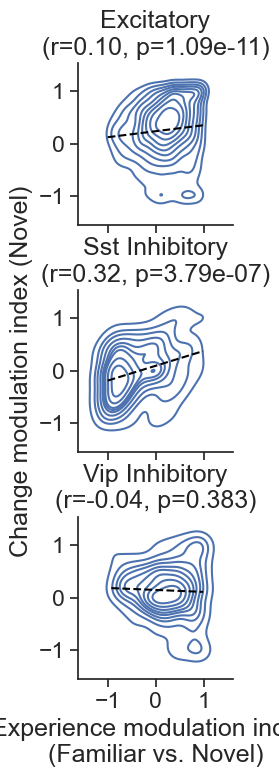

In [42]:

exp_mod_f_n = data[data.comparison=='F N']
change_mod_n = metrics_table[metrics_table.experience_level=='Familiar'][['cell_specimen_id', 'change_modulation_index']].merge(exp_mod_f_n)
df = change_mod_n.merge(exp_mod_f_n)
df = df.rename(columns={'value': 'experience_modulation_index'})

x_col = 'experience_modulation_index'
y_col = 'change_modulation_index'

ppf.plot_modulation_index_correlation(df, x_col, y_col, xlabel, ylabel,
                            ax=None, save_dir=None, folder=None, filename=None)

                            

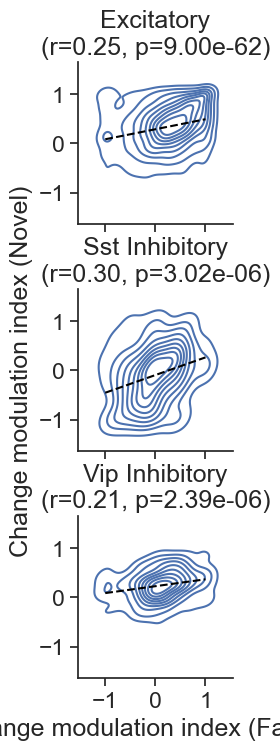

In [43]:
change_mod_f = metrics_table[metrics_table.experience_level=='Familiar'][['cell_specimen_id', 'change_modulation_index', 'cell_type']].rename(columns={'change_modulation_index': 'change_modulation_index_familiar'})
change_mod_n = metrics_table[metrics_table.experience_level=='Novel'][['cell_specimen_id', 'change_modulation_index', 'cell_type']].rename(columns={'change_modulation_index': 'change_modulation_index_novel'})
df = change_mod_n.merge(change_mod_f, on=['cell_specimen_id', 'cell_type'])

x_col = 'change_modulation_index_familiar'
y_col = 'change_modulation_index_novel'
xlabel='Change modulation index (Familiar)'
ylabel='Change modulation index (Novel)'

ppf.plot_modulation_index_correlation(df, x_col, y_col, xlabel, ylabel,
                            ax=None, save_dir=None, folder=None, filename=None)

                            

## SVM decoding (for S6 panel I & S7 panel G)
Loads the aggregated all_sess SVM decoding data and builds the across-project-code aggregated standalone plots. The labeled df / time axis / window metrics are stashed in `svm_agg` and reused by the S6 and S7 composite cells below.

[ok] decode_changes_from_nochanges / VisualBehavior: all_sess_events_svm_decode_changes_from_nochanges_equalTrs_frames-15to22_VisualBehavior_20220113_202511.h5
[ok] decode_changes_from_nochanges / VisualBehaviorTask1B: all_sess_events_svm_decode_changes_from_nochanges_equalTrs_frames-15to22_VisualBehaviorTask1B_20220113_202313.h5
[ok] decode_changes_from_nochanges / VisualBehaviorMultiscope: all_sess_events_svm_decode_changes_from_nochanges_equalTrs_frames-5to7_VisualBehaviorMultiscope_20220114_110349.h5
[ok] decode_baseline_from_nobaseline / VisualBehavior: all_sess_events_svm_decode_baseline_from_nobaseline_equalTrs_frames-15to22_VisualBehavior_20220113_202737.h5
[ok] decode_baseline_from_nobaseline / VisualBehaviorTask1B: all_sess_events_svm_decode_baseline_from_nobaseline_equalTrs_frames-15to22_VisualBehaviorTask1B_20220113_203011.h5
[ok] decode_baseline_from_nobaseline / VisualBehaviorMultiscope: all_sess_events_svm_decode_baseline_from_nobaseline_equalTrs_frames-5to7_VisualBehavi

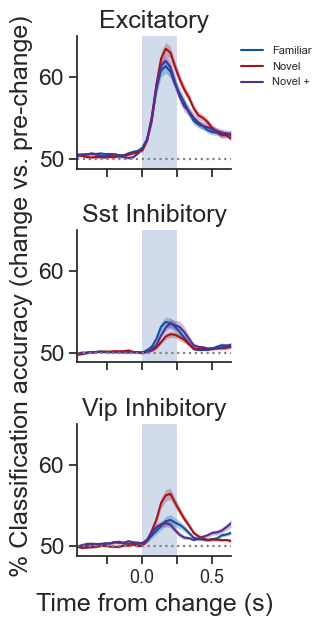

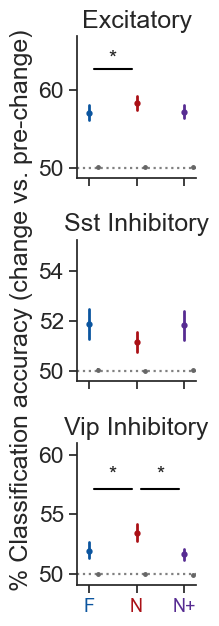

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:11157: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Mp, 0)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:11157: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Mp, 0)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:11157: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Mp, 0)
/opt/miniconda3/e

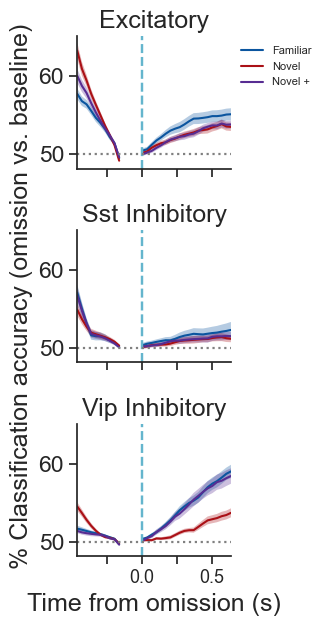

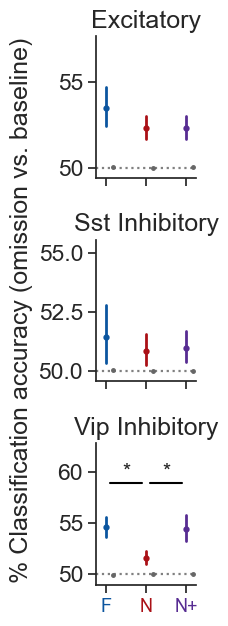

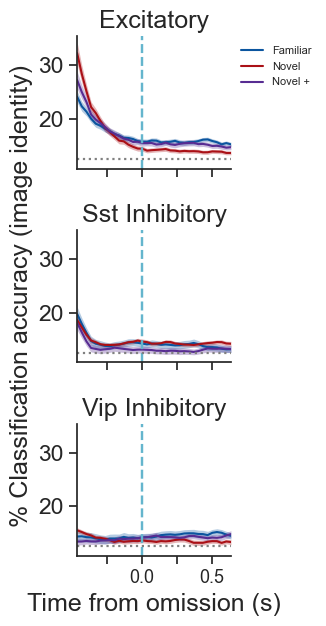

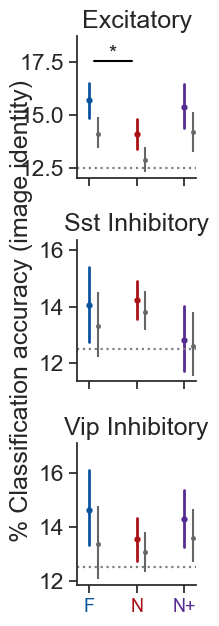

In [44]:
# ============================================================================
# SVM decoding (aggregated across project codes)
# Loads the all_sess SVM decoding aggregates and builds the across-project-code
# aggregated standalone plots for:
#   decode_changes_from_nochanges   -> Figure S6 panel I (change vs. no-change)
#   decode_baseline_from_nobaseline -> Figure S7 panel G (omission vs. gray)
#   decode_next_image_from_omissions -> Figure S8 panel F (image identity)
# The labeled df / common time axis / window metrics are stashed in `svm_agg`
# and reused by the S6 and S7 composite cells below.
# Mirrors load_svm_decoding_results.ipynb.
# ============================================================================
import re
import glob
import importlib
import matplotlib.pyplot as plt
importlib.reload(ppf)   # pick up the decoding functions added to platform_paper_figures.py

svm_project_codes = ['VisualBehavior', 'VisualBehaviorTask1B', 'VisualBehaviorMultiscope']
_svm_dir = os.path.join(loading.get_platform_analysis_cache_dir(), 'visual_behavior_ophys_decoding')
svm_metrics_dir = os.path.join(_svm_dir, 'window_metrics')

_SVM_PC_RE = re.compile(r'_(VisualBehaviorMultiscope|VisualBehaviorTask1B|VisualBehavior)_\d{8}_\d{6}\.h5$')
_SVM_TS_RE = re.compile(r'_(\d{8})_(\d{6})\.h5$')


def _svm_project_code(b):
    m = _SVM_PC_RE.search(b)
    return m.group(1) if m else None


def _svm_timestamp(b):
    m = _SVM_TS_RE.search(b)
    return (m.group(1) + m.group(2)) if m else ''


def find_svm_events_file(decoding_type, project_code):
    """Latest standard all_sess events aggregate for a (decoding_type, project_code)."""
    keep = []
    for f in glob.glob(os.path.join(_svm_dir, 'all_sess_events_svm_%s_*.h5' % decoding_type)):
        b = os.path.basename(f)
        if 'matched_cells' in b or 'sameNumNeurons' in b:
            continue
        if _svm_project_code(b) != project_code:
            continue
        keep.append(f)
    keep.sort(key=lambda f: _svm_timestamp(os.path.basename(f)))
    return keep[-1] if keep else None


svm_decoding_types = ['decode_changes_from_nochanges', 'decode_baseline_from_nobaseline',
                      'decode_next_image_from_omissions']  # last = S8 panel F (image identity)
svm_results, svm_input_vars = {}, {}
for _dt in svm_decoding_types:
    svm_results[_dt], svm_input_vars[_dt] = {}, {}
    for _pc in svm_project_codes:
        _fp = find_svm_events_file(_dt, _pc)
        if _fp is None:
            print('[missing] %s / %s' % (_dt, _pc))
            continue
        svm_results[_dt][_pc] = pd.read_hdf(_fp, key='all_sess')
        try:
            svm_input_vars[_dt][_pc] = pd.read_hdf(_fp, key='input_vars')
        except KeyError:
            svm_input_vars[_dt][_pc] = None
        print('[ok] %s / %s: %s' % (_dt, _pc, os.path.basename(_fp)))

# aggregate across project codes; build standalone figures; stash for the composites
svm_agg = {}
for _dt in svm_decoding_types:
    _combined, _t = ppf.resample_decoding_across_projects(
        svm_results, svm_input_vars, _dt, svm_project_codes)
    _labeled = ppf.add_decoding_labels(_combined, platform_experiments)
    _wm = ppf.get_decoding_window_metrics(
        _labeled, _dt, _t, metrics_dir=svm_metrics_dir, tag='aggregated', recompute=False)
    svm_agg[_dt] = dict(labeled=_labeled, t=_t, wm=_wm)
    ppf.plot_decoding_figures(_combined, _dt, platform_experiments, time_axis=_t,
                              metrics_dir=svm_metrics_dir, recompute_metrics=False)
    plt.show()


## Figure S6 composite — Extended analysis of image change-related activity
Extended analysis of image change related activity.

In [45]:
stats_capture_start()  # reset collector + (re)install hooks for this composite

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

OVERLAP: axes of panel "J" intrudes into panel "K" (left gutter)


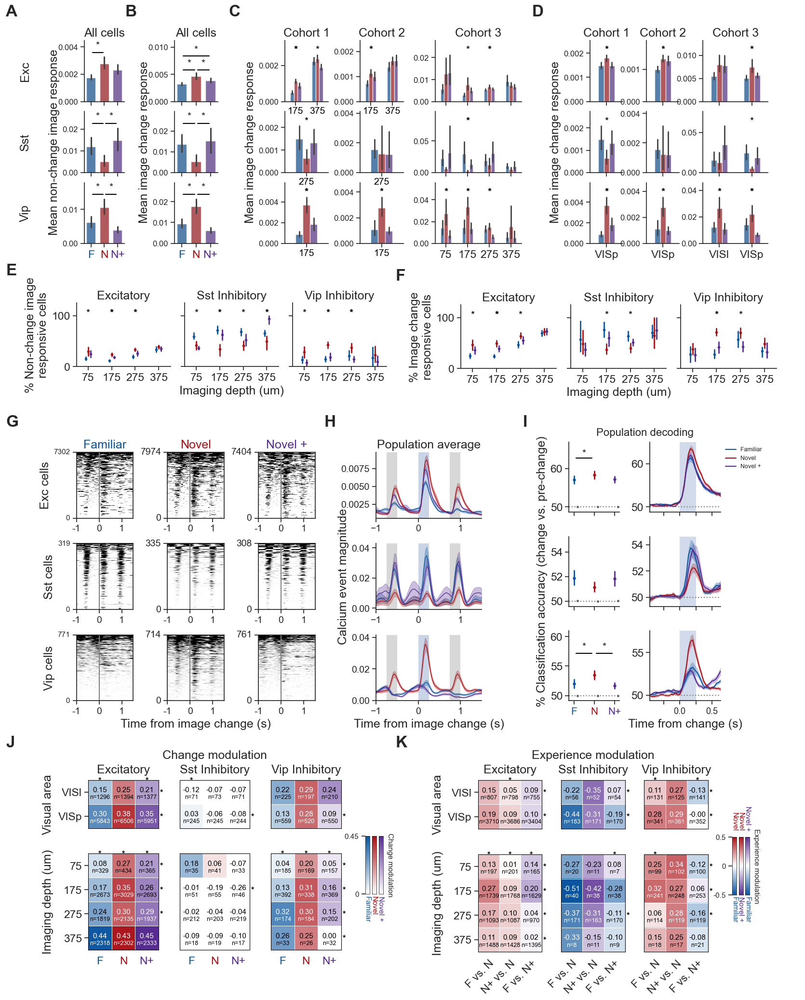

In [46]:
import os
# ==========================================================================
# Figure S6 composite  (Extended analysis of image change related activity)
# v10: A narrower, B wider, E/F taller, J/K down+wider. (v9: reverted figure height; J/K plots WIDER via main_width_ratios (not taller);
# A wider, B narrower; E/F down; G/H taller. (was v8: figure taller (23.08") with all extra height given to J/K (rows 1-3 keep
# absolute heights). A narrower; A first/third y-labels get a trailing newline;
# B wider. E/F taller + letters up. G/H letters down; G left spine aligned with
# A/E (decoration 82). J/K much larger.
# NOTE: restart kernel / re-run imports so the suptitle-offset change loads.
# ==========================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, show_label_gutters, check_label_overlap,
    auto_fit_bottom, snug_left_to_gutter, snug_top_to_gutter)

sns.set_context('notebook', font_scale=1.5)

FIGSIZE = (16.5, 19.58)
REGIONS = {
    'A': [0.0, 0.15, 0.0, 0.268], 'B': [0.15, 0.273, 0.0, 0.268],
    'C': [0.283, 0.651, 0.0, 0.268], 'D': [0.667, 0.963, 0.0, 0.268],
    'E': [0.0, 0.485, 0.278, 0.413], 'F': [0.49, 0.97, 0.28, 0.415],
    'G': [0.0, 0.39, 0.436, 0.766], 'H': [0.4, 0.6036, 0.436, 0.766],
    'I': [0.65, 0.90, 0.437, 0.766],
    'J': [0.0, 0.55, 0.778, 0.998], 'K': [0.49, 1.4, 0.778, 1.0],
}
CT = utils.get_cell_types()
WSPACE_CD, WSPACE_EF, WSPACE_G = 0.55, 0.15, 0.6
LEFT_MARGIN_DEC = 82   # shared left decoration (pt) for E/G left spines
A_LEFT_DEC = 90        # A starts further right (thinner; more gap to its text annotations)


def _hide_inner_xticklabels(grid):
    rows = grid if isinstance(grid[0], (list, tuple, np.ndarray)) else [[a] for a in grid]
    for r, row in enumerate(rows):
        if r < len(rows) - 1:
            for a in row:
                a.tick_params(labelbottom=False)


def _single_metric_ylabel(grid, metric_label):
    rows = grid if isinstance(grid[0], (list, tuple, np.ndarray)) else [[a] for a in grid]
    for row in rows:
        for a in row:
            a.set_ylabel('')
    rows[len(rows) // 2][0].set_ylabel(metric_label)


def _cohort_width_ratios(x_val):
    e = metrics_table[metrics_table.cell_type == 'Excitatory']
    return [len(np.sort(e[e.project_code == pc][x_val].dropna().unique()))
            for pc in metrics_table.project_code.unique()]

def _annotate_cohort_xvals(grid, x_val, rows=(0, 1, 2), cols=(0, 1), fontsize=14, color='k', dy=-8):
    # Cohorts 1 & 2 use different depths per cell type, so each subplot's x-tick labels are
    # blanked (un-hiding them would force inter-row whitespace) and the depth is printed in the
    # x-tick-label position (just below the axis) instead -- consistent across all three rows.
    # Categories come from the data (tick-label text reads back blank before the first draw).
    cts = utils.get_cell_types()
    pcs = list(metrics_table.project_code.unique())   # column order matches plot_metric_across_cohorts
    for _r in rows:
        for _c in cols:
            _ax = grid[_r][_c]
            _ax.set_zorder(5 - _r)               # raise upper rows so their labels draw over the axis below
            _ax.tick_params(labelbottom=False)   # blank x-tick labels; the annotation replaces them
            _data = metrics_table[(metrics_table.cell_type == cts[_r]) &
                                  (metrics_table.project_code == pcs[_c])]
            for _xpos, _cat in enumerate(np.sort(_data[x_val].unique())):   # seaborn category positions = 0,1,2,...
                if isinstance(_cat, float) and np.isnan(_cat):
                    continue
                try:
                    _lab = str(int(round(float(_cat))))     # depth -> integer um
                except (ValueError, TypeError):
                    _lab = str(_cat)                        # area -> name
                _an = _ax.annotate(_lab, xy=(_xpos, 0), xycoords=('data', 'axes fraction'),
                                   xytext=(0, dy), textcoords='offset points',
                                   ha='center', va='top', fontsize=fontsize, color=color, zorder=10)
                _an.set_clip_on(False)


ts_change = change_mdf.trace_timestamps.values[0]
fig = plt.figure(figsize=FIGSIZE)
fig_setup(fig)
stats_dir = os.path.join(save_dir, 'composite', 'figure_S6_stats') if save_dir else None

# ---- A: mean non-change image response (3x1; cell type each row, metric on MIDDLE) ----
axA = panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', has_title=True, dim=(3, 1),
            decoration_pt=(A_LEFT_DEC, 0))
ppf.plot_metric_distribution_by_experience(
    metrics_table, 'mean_response_all_images', event_type='images', data_type=data_type,
    plot_type='barplot', horiz=False, add_zero_line=False, ylabel='Mean non-change image response',
    ylims=None, save_dir=None, ax=axA, stats_dir=stats_dir)
for a in axA:
    a.set_ylabel('')
axA[1].set_ylabel('Mean non-change image response')
axA[0].set_title('All cells')
_hide_inner_xticklabels(axA)
for a in axA:
    a.tick_params(axis='y', labelsize=12)

# ---- B: mean image change response (3x1; single metric ylabel) ----
axB = panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', has_title=True, dim=(3, 1))
ppf.plot_metric_distribution_by_experience(
    metrics_table, 'mean_response_changes', event_type='changes', data_type=data_type,
    plot_type='barplot', horiz=False, add_zero_line=False, ylabel='Mean image change response',
    ylims=None, save_dir=None, ax=axB, stats_dir=stats_dir)
_single_metric_ylabel(axB, 'Mean image change response')
axB[0].set_title('All cells')
_hide_inner_xticklabels(axB)
for a in axB:
    a.tick_params(axis='y', labelsize=12)

# ---- C: change response by cohort x imaging depth (3x3; x shared down columns) ----
axC = panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C', has_title=True, dim=(3, 3),
            sharex='col', sharey=False, wspace=WSPACE_CD, width_ratios=_cohort_width_ratios('binned_depth'))
ppf.plot_metric_across_cohorts(
    metrics_table, 'mean_response_changes', 'Mean image change response',
    x_val='binned_depth', plot_type='barplot', event_type='changes', save_dir=None,
    ax=list(np.array(axC).ravel()), stats_dir=stats_dir)
_single_metric_ylabel(axC, 'Mean image change response')
_hide_inner_xticklabels(axC)
_annotate_cohort_xvals(axC, 'binned_depth')  # depth labels for Exc/Sst, cohorts 1-2

# ---- D: change response by cohort x visual area (3x3) ----
axD = panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D', has_title=True, dim=(3, 3),
            sharey=False, wspace=WSPACE_CD, width_ratios=_cohort_width_ratios('targeted_structure'))
ppf.plot_metric_across_cohorts(
    metrics_table, 'mean_response_changes', 'Mean image change response',
    x_val='targeted_structure', plot_type='barplot', event_type='changes', save_dir=None,
    ax=list(np.array(axD).ravel()), stats_dir=stats_dir)
_single_metric_ylabel(axD, 'Mean image change response')
_hide_inner_xticklabels(axD)

# ---- E / F: % responsive cells by depth (1x3; shared y; taller) ----
axE = panel(fig, REGIONS['E'][:2], REGIONS['E'][2:], 'E', has_title=True, dim=(1, 3),
            sharey=True, wspace=WSPACE_EF, decoration_pt=(LEFT_MARGIN_DEC, 0))
ppf.plot_percent_responsive_cells_by_depth(each_image_mdf, 'images', platform_experiments, ylabel='% Non-change image\nresponsive cells', save_dir=None, ax=list(np.array(axE).ravel()), stats_dir=stats_dir)
for a in (axE[1], axE[2]):
    a.set_ylabel('')
for a in (axE[0], axE[2]):
    a.set_xlabel('')
axE[1].set_xlabel('Imaging depth (um)')

axF = panel(fig, REGIONS['F'][:2], REGIONS['F'][2:], 'F', has_title=True, dim=(1, 3),
            sharey=True, wspace=WSPACE_EF)
ppf.plot_percent_responsive_cells_by_depth(each_image_mdf, 'changes', platform_experiments, ylabel='% Image change\nresponsive cells', save_dir=None, ax=list(np.array(axF).ravel()), stats_dir=stats_dir)
for a in (axF[1], axF[2]):
    a.set_ylabel('')
for a in (axF[0], axF[2]):
    a.set_xlabel('')
axF[1].set_xlabel('Imaging depth (um)')

# ---- G: ALL-cells change-response heatmaps (3x3; left spine aligned w/ A,E) ----
axG = panel(fig, REGIONS['G'][:2], REGIONS['G'][2:], 'G', has_title=True, dim=(3, 3),
            wspace=WSPACE_G, decoration_pt=(LEFT_MARGIN_DEC, 0))
ppf.plot_response_heatmaps_for_conditions(
    change_mdf, ts_change, data_type, 'all', 'cell_type', 'experience_level',
    col_to_sort_by='mean_baseline', suptitle=None, exp_to_match='Familiar',
    xlabel='Time from image change (s)', matched_cells_table=None,
    xlim_seconds=[-1, 1.5], match_cells=False, cbar=False, plot_epochs=False,
    save_dir=None, folder='population_activity', suffix='_all',
    ax=list(np.array(axG).ravel()))
for r in range(3):                       # smaller count ticks so G's left spine can align with A/E
    axG[r][0].tick_params(axis='y', labelsize=11)
    axG[r][0].set_ylabel(CT[r][:3] + ' cells')   # abbreviated, single line

# ---- H: all-cells change population averages (3x1) ----
axH = panel(fig, REGIONS['H'][:2], REGIONS['H'][2:], 'H', has_title=True, dim=(3, 1))
ppf.plot_population_averages_for_conditions(
    change_mdf, data_type, 'changes', 'cell_type', 'experience_level',
    ylabel='Calcium event magnitude', sharey=False, horizontal=False,
    xlabel='Time from image change (s)', xlim_seconds=[-1., 1.5], interval_sec=1,
    legend=False, palette=palette, ax=axH, title=None, suptitle=None, save_dir=None)
for a in axH:
    a.set_title('')
axH[0].set_title('Population average')
axH[1].set_ylabel('Calcium event magnitude')
for a in (axH[0], axH[2]):
    a.set_ylabel('')
axH[-1].set_xlabel('Time from image change (s)')

# ---- I: change vs no-change decoding (aggregated across project codes): window summary + timecourse ----
_dtI = 'decode_changes_from_nochanges'
_agI = svm_agg[_dtI]
axI = panel(fig, REGIONS['I'][:2], REGIONS['I'][2:], 'I', dim=(3, 2),
            width_ratios=[1, 1.4], wspace=0.5, hspace=0.0)
_I0 = [axI[r][0] for r in range(3)]   # window-summary point-plots
_I1 = [axI[r][1] for r in range(3)]   # time-resolved traces
ppf.plot_decoding_window_summary(_agI['wm'], _dtI, axes=_I0)
ppf.plot_decoding_timecourse(_agI['labeled'], _dtI, _agI['t'], axes=_I1)
for _a in _I0 + _I1:                       # no titles (header or cell-type)
    _a.set_title('')
for _a in (_I0[0], _I0[1], _I1[0], _I1[1]):   # x labels on the bottom row only
    _a.tick_params(labelbottom=False)
_I0[1].set_ylabel('% Classification accuracy (change vs. pre-change)')
_I1[1].set_ylabel('')
_I0[2].tick_params(axis='x', labelsize=15)   # +2 pt on F/N/N+
_legI = _I1[0].get_legend()
if _legI is not None:
    for _t in _legI.get_texts():
        _t.set_fontsize(9)

# ---- J: change-modulation heatmaps (area + depth x cell type), embedded ----
LEFT_INSET, TOP_INSET = 0.105, 0.040
panel(fig, REGIONS['J'][:2], REGIONS['J'][2:], 'J', dim=(1, 1)).axis('off')
ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
    metrics_table, metric='change_modulation_index', metric_label='Change modulation',
    event_type='changes', save_dir=None, main_width_ratios=(3.0, 0.5),
    heatmap_cbar_gap_in=0.5, cbar_width_in=0.09, cbar_height_in=1.2, cbar_fontsize=11, annot_fontsize=11,
    fig=fig, panel_bbox=(REGIONS['J'][0] + LEFT_INSET, REGIONS['J'][2] + TOP_INSET,
                         REGIONS['J'][1], REGIONS['J'][3]), stats_dir=stats_dir)

# ---- K: experience-modulation heatmaps (image response), embedded ----
panel(fig, REGIONS['K'][:2], REGIONS['K'][2:], 'K', dim=(1, 1)).axis('off')
ppf.plot_experience_modulation_heatmap_area_and_depth_by_cell_type(
    image_mdf, event_type='images', metric='mean_response', cells_table=platform_cells_table,
    save_dir=None, main_width_ratios=(3.0, 0.5),
    heatmap_cbar_gap_in=0.5, cbar_width_in=0.09, cbar_height_in=1.2, cbar_fontsize=11, annot_fontsize=11,
    fig=fig, panel_bbox=(REGIONS['K'][0] + LEFT_INSET, REGIONS['K'][2] + TOP_INSET,
                         REGIONS['K'][1], REGIONS['K'][3]), stats_dir=stats_dir)

# ---- fit + snug + audit ----
auto_fit_bottom(fig, REGIONS, pad_pt=2)
snug_left_to_gutter(fig, REGIONS, only=['B', 'C', 'D', 'F', 'H', 'I'])
snug_top_to_gutter(fig, REGIONS, only=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'])
# A: cell-type + metric labels as fixed-x annotations so they align across rows
# (per-row y-tick widths differ, which would misalign set_ylabel positions)
fig.canvas.draw()
_gx = 20 / 72 / FIGSIZE[0]
_x_ct = REGIONS['A'][0] + _gx + 0.009     # cell type (outer)
_fs = plt.rcParams['axes.labelsize']
for _a, _ct in zip(axA, CT):
    _p = _a.get_position()
    fig.text(_x_ct, (_p.y0 + _p.y1) / 2, _ct[:3], rotation=90, ha='center', va='center', fontsize=_fs)

# "Population decoding" suptitle, centered between I's two columns, in the title row
fig.canvas.draw()
_ip0 = _I0[0].get_position(); _ip1 = _I1[0].get_position()
fig.text((_ip0.x0 + _ip1.x1) / 2, max(_ip0.y1, _ip1.y1) + 0.005, 'Population decoding',
         ha='center', va='bottom', fontsize=16)

check_label_overlap(fig, REGIONS)

# Rasterize only heavy data artists (many-point traces/scatters) so the PDF exports fast;
# axis text, ticks and light artists stay vector (editable in Illustrator).
for _ax in fig.axes:
    for _art in list(_ax.lines) + list(_ax.collections):
        _n = (len(_art.get_xydata()) if hasattr(_art, 'get_xydata')
              else max(len(_art.get_offsets()), sum(len(p.vertices) for p in _art.get_paths())))
        if _n > 2000:
            _art.set_rasterized(True)
utils.save_figure(fig, FIGSIZE, save_dir, 'composite', 'figure_S6_composite', formats=['.png', '.pdf'])
plt.show()


In [47]:
stats_capture_save(save_dir, 'composite', 'figure_S6_composite_stats')

stats capture: wrote 627 rows from 171 panel stat-tables -> /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/figure_3_supplemental/composite/figure_S6_composite_stats.csv


,_metric,_cell_type,_column_to_compare,_source_fn,metric,event_type,cell_type,column_to_compare,groups,group1,...,ci1_high_mouse,ci2_high_mouse,n1_mouse,n2_mouse,one_way_anova_p_val,data_subset,grouping,direction,held_fixed_col,held_fixed_value
0,mean_response_all_images,Excitatory,None,compute_stats,mean_response_all_images,images,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.001532,0.002370,34,34,9.424656e-05,NaN,NaN,NaN,NaN,NaN
1,mean_response_all_images,Excitatory,None,compute_stats,mean_response_all_images,images,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.001532,0.002067,34,34,6.297310e-02,NaN,NaN,NaN,NaN,NaN
2,mean_response_all_images,Excitatory,None,compute_stats,mean_response_all_images,images,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Novel,...,0.002370,0.002067,34,34,6.297310e-02,NaN,NaN,NaN,NaN,NaN
3,mean_response_all_images,Sst Inhibitory,None,compute_stats,mean_response_all_images,images,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.014739,0.004387,15,15,2.987380e-02,NaN,NaN,NaN,NaN,NaN
4,mean_response_all_images,Sst Inhibitory,None,compute_stats,mean_response_all_images,images,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.014739,0.018310,15,15,3.452909e-01,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622,value,None,comparison,compute_stats,value,images,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,0.345636,0.418442,6,6,9.355030e-06,NaN,NaN,NaN,NaN,NaN
623,value,None,comparison,compute_stats,value,images,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N+,...,0.153522,0.418442,6,6,2.887767e-19,NaN,NaN,NaN,NaN,NaN
624,value,None,comparison,compute_stats,value,images,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,0.284200,0.579128,3,3,2.643420e-01,NaN,NaN,NaN,NaN,NaN
625,value,None,comparison,compute_stats,value,images,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,0.284200,0.887097,3,3,5.578773e-01,NaN,NaN,NaN,NaN,NaN


# Figure S7 — Extended analysis of omission-related activity

## Omission response characterization

Population average responses and single-cell heatmaps aligned to image omissions
across experience levels, for matched and unmatched cells. Includes omission
response magnitude by cohort, area, and depth, omission modulation index
distributions, and fraction of cells with significant omission responses. Also
includes population decoding of omission vs. pre-omission gray screen activity
and time-resolved decoding accuracy. Corresponds to PPT Figure S8 panels A-M.

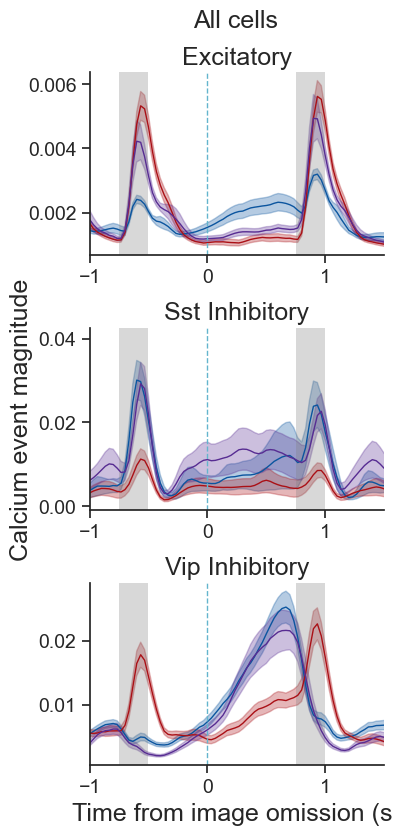

In [48]:
# population averages for omisisons
xlim_seconds = [-1., 1.5]

axes_column = 'cell_type'
hue_column = 'experience_level'

ax = ppf.plot_population_averages_for_conditions(
    omission_mdf, data_type, 'omissions', axes_column, hue_column,
    ylabel='Calcium event magnitude', sharey=False,
    horizontal=False, xlabel='Time from image omission (s)',
    xlim_seconds=xlim_seconds, interval_sec=1, legend=False,
    palette=palette, ax=None, title=None, suptitle='All cells',
    save_dir=save_dir, suffix='_omissions_all_cells')

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\ncells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\ncells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\ncells'>,
       <Axes: xlabel='Time from omission (s)'>, <Axes: >], dtype=object)

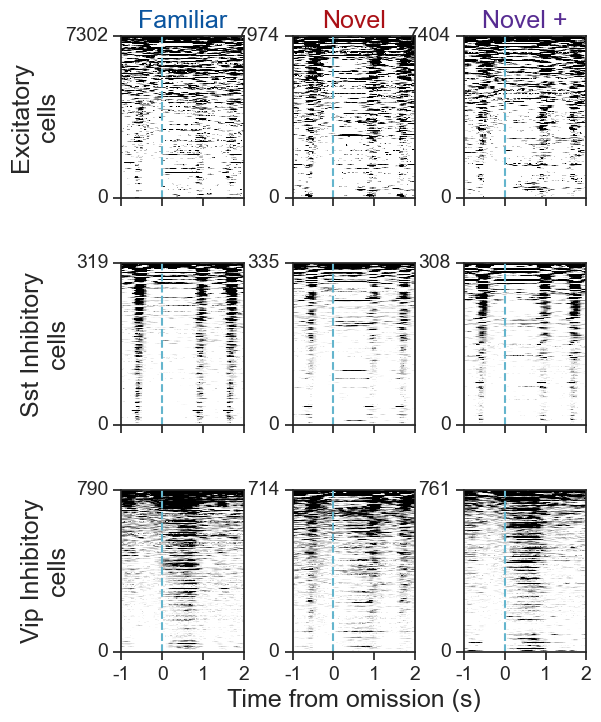

In [49]:
# Population averages for omissions - heatmaps
timestamps = omission_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(
    omission_mdf, timestamps, data_type, 'omissions', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Omission responses',
    xlabel='Time from omission (s)', exp_to_match='Familiar', matched_cells_table=None,
    microscope=None, xlim_seconds=[-1, 2], match_cells=False, cbar=False,
    save_dir=save_dir, suffix='_omissions', ax=None)

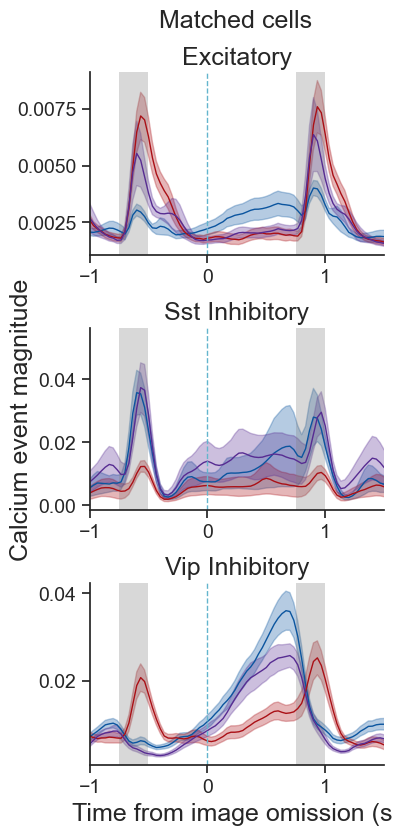

In [50]:
# population averages for omisisons
xlim_seconds = [-1., 1.5]

axes_column = 'cell_type'
hue_column = 'experience_level'

df = omission_mdf[omission_mdf.cell_specimen_id.isin(matched_cells_table.cell_specimen_id)]

ax = ppf.plot_population_averages_for_conditions(
    df, data_type, 'omissions', axes_column, hue_column,
    ylabel='Calcium event magnitude', sharey=False, 
    horizontal=False, xlabel='Time from image omission (s)',
    xlim_seconds=xlim_seconds, interval_sec=1, legend=False,
    palette=palette, ax=None, title=None, suptitle='Matched cells',
    save_dir=save_dir, suffix='_omissions_matched_cells')

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from omission (s)'>, <Axes: >], dtype=object)

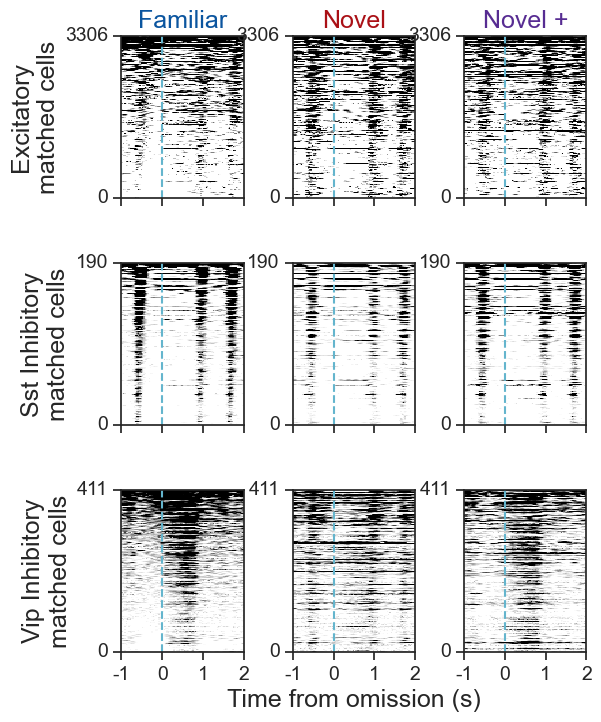

In [51]:
# Cell-matched omission heatmaps
matched_omissions = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(omission_mdf)
matched_omissions = utilities.limit_to_last_familiar_second_novel_active(matched_omissions)

ppf.plot_response_heatmaps_for_conditions(
    matched_omissions, timestamps, data_type, 'omissions', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Omissions',
    xlabel='Time from omission (s)', exp_to_match='Familiar', matched_cells_table=matched_cells_table,
    microscope=None, xlim_seconds=[-1, 2], match_cells=True, cbar=False,
    save_dir=save_dir, suffix='_matched_omissions', ax=None)

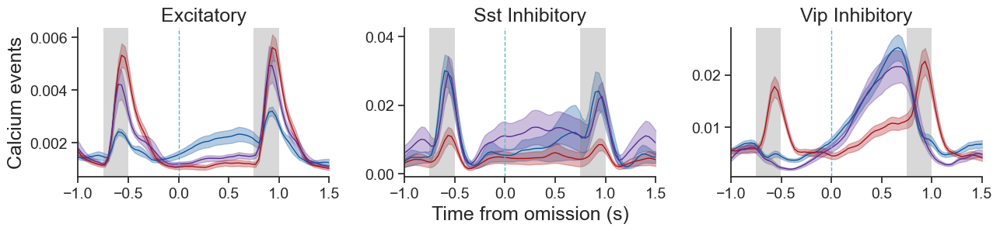

In [52]:
# Population averages for omissions across conditions
axes_column = 'cell_type'
hue_column = 'experience_level'
xlim_seconds = [-1., 1.5]

ax = ppf.plot_population_averages_for_conditions(
    omission_mdf, data_type, 'omissions', axes_column, hue_column,
    horizontal=True, xlabel='Time from omission (s)',
    ylabel='Calcium events', legend=False,
    xlim_seconds=xlim_seconds, interval_sec=0.5,
    palette=palette, ax=None, title=None, suptitle=None,
    save_dir=save_dir, suffix='_omissions')

#### Fraction responsive cells 

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

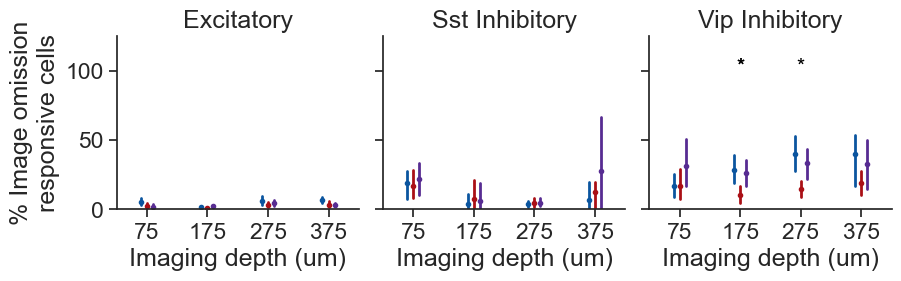

In [53]:
df = omission_mdf.copy()
fraction_responsive = ppf.get_fraction_responsive_cells(df, conditions=['cell_type', 'experience_level', 'ophys_container_id', 'ophys_experiment_id'],
                                                        responsiveness_threshold=0.1)
fraction_responsive = fraction_responsive.reset_index()
fraction_responsive = fraction_responsive.merge(platform_experiments[['ophys_container_id', 'binned_depth', 'imaging_depth']], on='ophys_container_id')
fraction_responsive = fraction_responsive.drop_duplicates(subset=['ophys_container_id', 'ophys_experiment_id'])
fraction_responsive['percent_responsive'] = fraction_responsive['fraction_responsive']*100

depths = np.sort(fraction_responsive.binned_depth.unique())

cell_types = utils.get_cell_types()
figsize = (10, 2.25)
fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
ax = ax.ravel()
for i, cell_type in enumerate(cell_types): 
    data = fraction_responsive[fraction_responsive.cell_type==cell_type]
    ax[i] = sns.pointplot(data=data,
                    x='binned_depth', y='percent_responsive', hue='experience_level', linestyle='none', order=depths,
                    markers='.', markersize=4, err_kws={'linewidth': 2}, palette=experience_level_colors, dodge=0.2, ax=ax[i])
    ax[i].set_title(cell_type)
    # ax[i].legend(fontsize='xx-small')
    ax[i].get_legend().remove()
    ax[i].set_xlabel('Imaging depth (um)')
    ax[i].set_ylabel('% Image omission\nresponsive cells')
    ax[i].set_ylim(0, 100)

    ax[i], tukey_table = ppf.add_stats_to_plot_for_hues(data, 'percent_responsive', ax[i],
                                                            xorder=depths, x='binned_depth', hue='experience_level')
plt.subplots_adjust(wspace=0.1)

filename = 'percent_omission_responsive_cells_by_depth'
utils.save_figure(fig, figsize, save_dir, folder, filename)

#### Omission response magnitude

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean omission response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

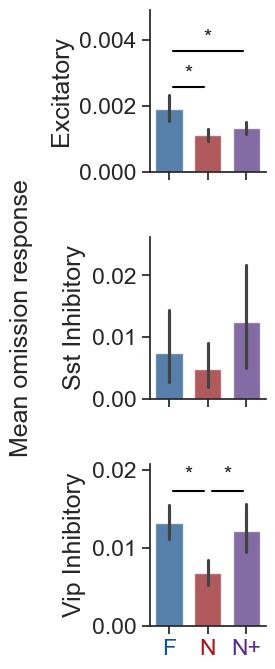

In [54]:
metric = 'mean_response_omissions'
ylabel = 'Mean omission response'

event_type = 'omissions'

ylims = None #(-0.001, 0.025)

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=ylims, save_dir=save_dir, ax=None)



/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

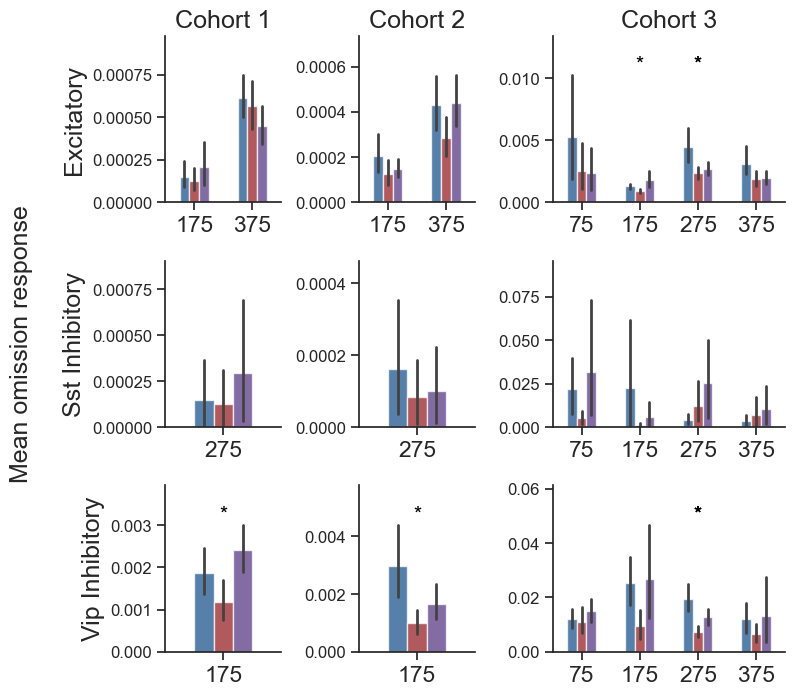

In [55]:
metric = 'mean_response_omissions'
ylabel = 'Mean omission response'
event_type = 'omissions'
x_val = 'binned_depth'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)


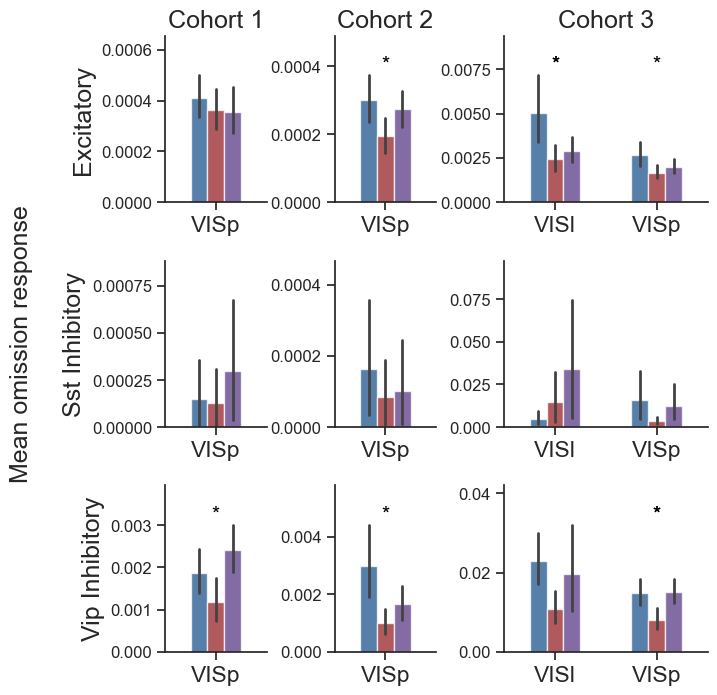

In [56]:
metric = 'mean_response_omissions'
ylabel = 'Mean omission response'
event_type = 'omissions'
x_val = 'targeted_structure'

ppf.plot_metric_across_cohorts(metrics_table, metric,  ylabel, x_val=x_val, plot_type='barplot', 
                               event_type=event_type, save_dir=save_dir, ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

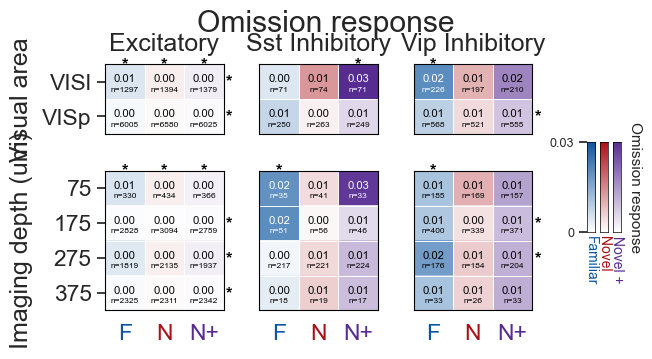

In [57]:
if not skip_slow_plots:
    ax, stats = ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='mean_response_omissions', metric_label='Omission response',
        save_dir=save_dir, event_type='omissions')

#### Omission modulation index

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Omission modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

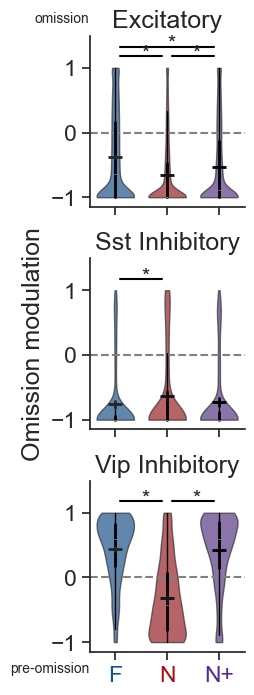

In [58]:
metric = 'omission_modulation_index'
xlabel = 'Omission modulation'
event_type = 'omissions'
annot = ('pre-omission', 'omission')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, label=xlabel, plot_type='violinplot',
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, suffix='', event_type='omissions')


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3671: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, x=x, y=y, orient=orient,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Use

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Omission modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

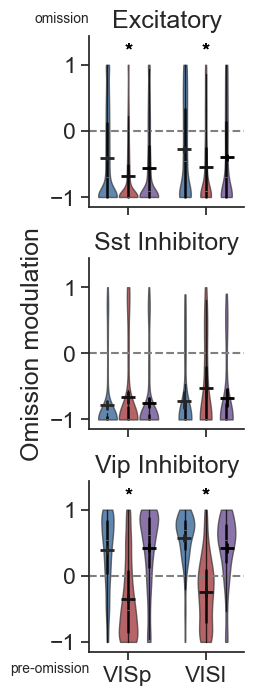

In [59]:
metric = 'omission_modulation_index'
label = 'Omission modulation'
event_type = 'omissions'
annot = ('pre-omission', 'omission')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, x_axis_col='targeted_structure', plot_type='violinplot',
                                       label=label, lims=xlims, horiz=False, annot=annot, fill=True,
                                        abbreviate_exp=True, suptitle=None, save_dir=save_dir, suffix='', event_type='omissions')

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3671: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, x=x, y=y, orient=orient,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Use

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Omission modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

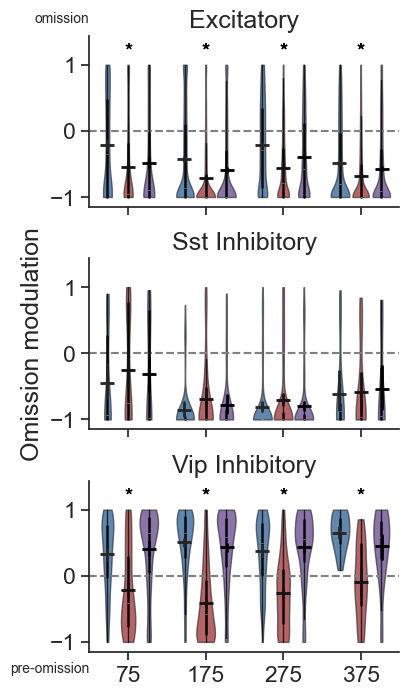

In [60]:
metric = 'omission_modulation_index'
label = 'Omission modulation'
event_type = 'omissions'
annot = ('pre-omission', 'omission')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, x_axis_col='binned_depth', plot_type='violinplot',
                                       label=label, lims=xlims, horiz=False, annot=annot, fill=True,
                                    metric_on_y=True, abbreviate_exp=True, suptitle=None, save_dir=save_dir, suffix='', event_type='omissions')

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Experience modulation'>],
      dtype=object)

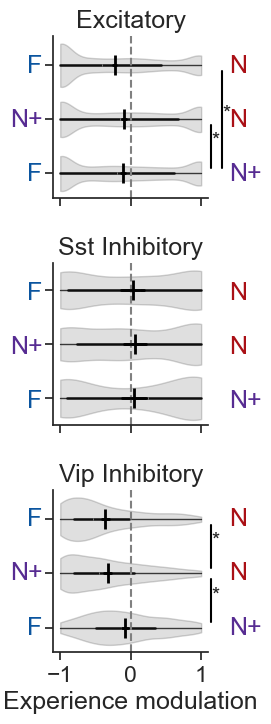

In [61]:
metric = 'mean_response'
event_type = 'omissions'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated_by_cell_type(omission_mdf, event_type, metric, platform_cells_table,
                                                            xlims=(-1.1, 1.1), xlabel=xlabel,
                                                            all_comparisons=True, horiz=False,
                                                            suptitle=None, suffix='', save_dir=None, ax=None)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])


array([<Axes: title={'center': 'Novel vs. Familiar'}>,
       <Axes: title={'center': 'Novel vs. Novel +'}>,
       <Axes: title={'center': 'Novel + vs. Familiar'}, xlabel='Experience modulation'>],
      dtype=object)

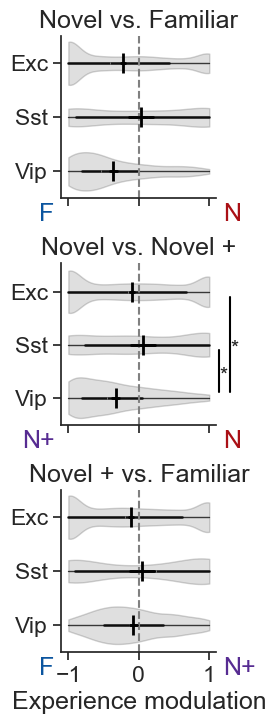

In [62]:
metric = 'mean_response'
event_type = 'omissions'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated(
    omission_mdf, event_type, metric, platform_cells_table,
    xlabel=xlabel, xlims=(-1.1, 1.1), horiz=False,
    suptitle=None, suffix='', save_dir=save_dir, ax=None)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

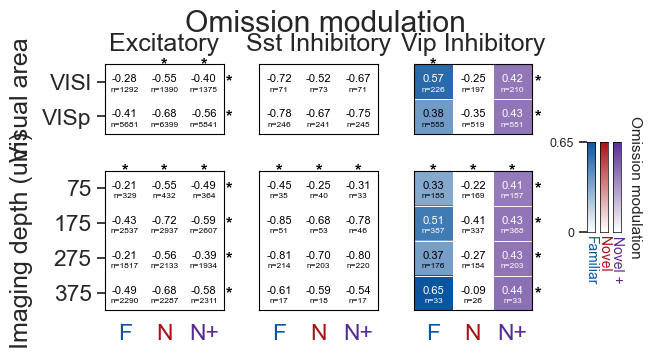

In [63]:
if not skip_slow_plots:
    ax, stats = ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='omission_modulation_index', metric_label='Omission modulation',
        save_dir=save_dir, event_type='omissions')

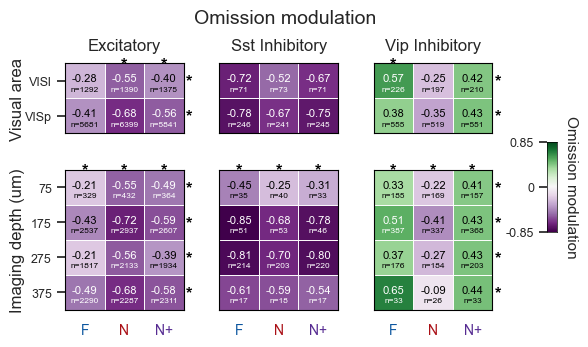

In [64]:
if not skip_slow_plots:

    ax, stats = ppf.plot_bidirectional_metric_heatmap_area_and_depth_by_cell_type(
        metrics_table, metric='omission_modulation_index', metric_label='Omission modulation',
        cmap='PRGn', save_dir=save_dir, event_type='omissions'
    )

#### Omission experience modulation by area and depth

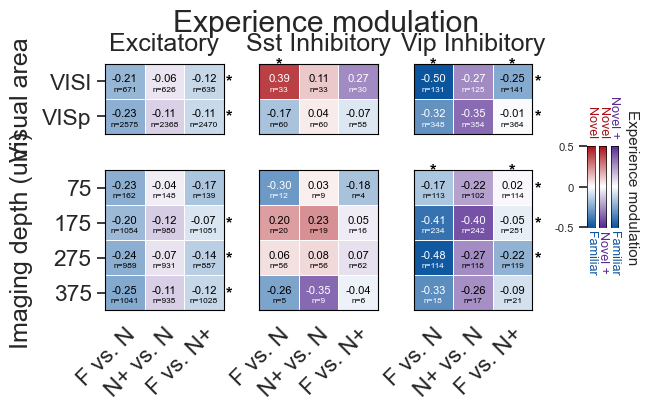

In [65]:
if not skip_slow_plots:
    metric = 'mean_response'
    event_type = 'omissions'
    xlabel = 'Experience modulation'

    ax, stats = ppf.plot_experience_modulation_heatmap_area_and_depth_by_cell_type(
        omission_mdf, event_type=event_type, metric=metric,
        cells_table=platform_cells_table,
        save_dir=save_dir, folder='metric_distributions',
    )

In [66]:
# metric = 'mean_response'
# event_type = 'omissions'
# xlabel = 'Experience modulation'

# ax3, stats_table = ppf.plot_experience_modulation_index_depth_heatmap_by_cell_type(
#     omission_mdf, event_type, metric, platform_cells_table,
#     groupby_col='binned_depth', ylabel='Imaging depth (um)', save_dir=save_dir)

# ax3, stats_table = ppf.plot_experience_modulation_index_depth_heatmap_by_cell_type(
#     omission_mdf, event_type, metric, platform_cells_table,
#     groupby_col='targeted_structure', ylabel='Visual area', save_dir=save_dir)



## Figure S7 composite — Extended analysis of omission-related activity
Extended analysis of omission related activity.

In [67]:
stats_capture_start()  # reset collector + (re)install hooks for this composite

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

OVERLAP: axes of panel "J" intrudes into panel "K" (left gutter)
OVERLAP: axes of panel "J" intrudes into panel "K" (left gutter)


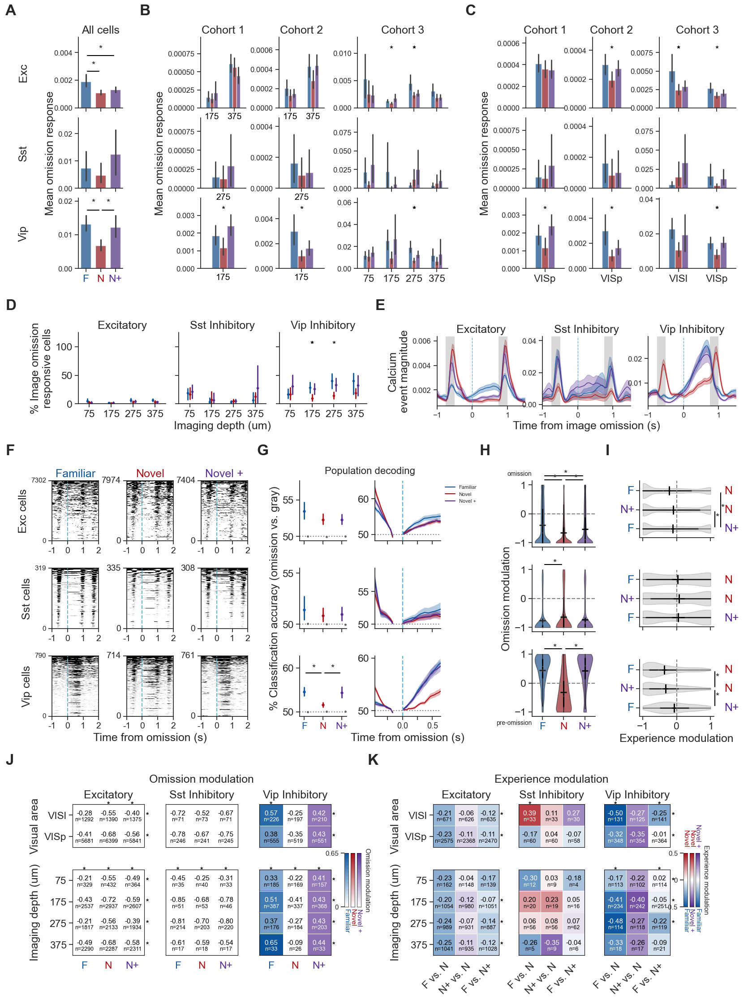

In [68]:
import os
# ==========================================================================
# Figure S7 composite  (Extended analysis of omission related activity)
# Mirrors the S6 composite cell above: same panel_grid scaffolding + helpers,
# omission versions of each panel. REGIONS derived from the measured figure geometry
# (crop aspect 0.762 -> portrait figure).
#   A omission response | B cohort x depth | C cohort x area | D % omission responsive
#   E omission population averages | F omission heatmaps | G decoding placeholder (other notebook)
#   H omission modulation | I experience modulation | J/K modulation heatmaps (embedded)
# NOTE: restart kernel / re-run imports so the platform_paper_figures E/H/I
# side-effect guards load before rendering.
# ==========================================================================
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, show_label_gutters, check_label_overlap,
    auto_fit_bottom, snug_left_to_gutter, snug_top_to_gutter)

sns.set_context('notebook', font_scale=1.5)

FIGSIZE = (16.5, 21.6)
REGIONS = {
    'A': [0.0,   0.161, 0.0,   0.287], 'B': [0.185, 0.601, 0.0,   0.287],
    'C': [0.625, 0.992, 0.0,   0.287],
    'D': [0.0,   0.49, 0.305, 0.440], 'E': [0.5, 0.992, 0.309, 0.440],
    'F': [0.0,   0.335, 0.458, 0.762], 'G': [0.340, 0.59, 0.458, 0.762],
    'H': [0.647, 0.801, 0.458, 0.762], 'I': [0.814, 0.960, 0.458, 0.762],
    'J': [0.002, 0.55, 0.774, 0.98],   'K': [0.49, 1.45, 0.774, 0.98],
}
CT = utils.get_cell_types()
WSPACE_BC, WSPACE_F = 0.55, 0.6
LEFT_MARGIN_DEC = 90   # shared left decoration (pt); aligns A/D/F left spines
A_LEFT_DEC = 90        # A starts further right (thin column; gap to its row labels)


def _hide_inner_xticklabels(grid):
    rows = grid if isinstance(grid[0], (list, tuple, np.ndarray)) else [[a] for a in grid]
    for r, row in enumerate(rows):
        if r < len(rows) - 1:
            for a in row:
                a.tick_params(labelbottom=False)


def _single_metric_ylabel(grid, metric_label):
    rows = grid if isinstance(grid[0], (list, tuple, np.ndarray)) else [[a] for a in grid]
    for row in rows:
        for a in row:
            a.set_ylabel('')
    rows[len(rows) // 2][0].set_ylabel(metric_label)


def _cohort_width_ratios(x_val):
    e = metrics_table[metrics_table.cell_type == 'Excitatory']
    return [len(np.sort(e[e.project_code == pc][x_val].dropna().unique()))
            for pc in metrics_table.project_code.unique()]

def _annotate_cohort_xvals(grid, x_val, rows=(0, 1, 2), cols=(0, 1), fontsize=14, color='k', dy=-8):
    # Cohorts 1 & 2 use different depths per cell type, so each subplot's x-tick labels are
    # blanked (un-hiding them would force inter-row whitespace) and the depth is printed in the
    # x-tick-label position (just below the axis) instead -- consistent across all three rows.
    # Categories come from the data (tick-label text reads back blank before the first draw).
    cts = utils.get_cell_types()
    pcs = list(metrics_table.project_code.unique())   # column order matches plot_metric_across_cohorts
    for _r in rows:
        for _c in cols:
            _ax = grid[_r][_c]
            _ax.set_zorder(5 - _r)               # raise upper rows so their labels draw over the axis below
            _ax.tick_params(labelbottom=False)   # blank x-tick labels; the annotation replaces them
            _data = metrics_table[(metrics_table.cell_type == cts[_r]) &
                                  (metrics_table.project_code == pcs[_c])]
            for _xpos, _cat in enumerate(np.sort(_data[x_val].unique())):   # seaborn category positions = 0,1,2,...
                if isinstance(_cat, float) and np.isnan(_cat):
                    continue
                try:
                    _lab = str(int(round(float(_cat))))     # depth -> integer um
                except (ValueError, TypeError):
                    _lab = str(_cat)                        # area -> name
                _an = _ax.annotate(_lab, xy=(_xpos, 0), xycoords=('data', 'axes fraction'),
                                   xytext=(0, dy), textcoords='offset points',
                                   ha='center', va='top', fontsize=fontsize, color=color, zorder=10)
                _an.set_clip_on(False)

ts_omission = omission_mdf.trace_timestamps.values[0]
fig = plt.figure(figsize=FIGSIZE)
fig_setup(fig)
stats_dir = os.path.join(save_dir, 'composite', 'figure_S7_stats') if save_dir else None

# ---- A: mean omission response (3x1; cell type each row, metric on MIDDLE) ----
axA = panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', has_title=True, dim=(3, 1),
            decoration_pt=(A_LEFT_DEC, 0))
ppf.plot_metric_distribution_by_experience(
    metrics_table, 'mean_response_omissions', event_type='omissions', data_type=data_type,
    plot_type='barplot', horiz=False, add_zero_line=False, ylabel='Mean omission response',
    ylims=None, save_dir=None, ax=axA, stats_dir=stats_dir)
for a in axA:
    a.set_ylabel('')
axA[1].set_ylabel('Mean omission response')
axA[0].set_title('All cells')
_hide_inner_xticklabels(axA)
for a in axA:
    a.tick_params(axis='y', labelsize=12)

# ---- B: omission response by cohort x imaging depth (3x3; x shared down columns) ----
axB = panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', has_title=True, dim=(3, 3),
            sharex='col', sharey=False, wspace=WSPACE_BC, width_ratios=_cohort_width_ratios('binned_depth'))
ppf.plot_metric_across_cohorts(
    metrics_table, 'mean_response_omissions', 'Mean omission response',
    x_val='binned_depth', plot_type='barplot', event_type='omissions', save_dir=None,
    ax=list(np.array(axB).ravel()), stats_dir=stats_dir)
_single_metric_ylabel(axB, 'Mean omission response')
_hide_inner_xticklabels(axB)
_annotate_cohort_xvals(axB, 'binned_depth')  # depth labels for Exc/Sst/Vip, cohorts 1-2

# ---- C: omission response by cohort x visual area (3x3) ----
axC = panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C', has_title=True, dim=(3, 3),
            sharey=False, wspace=WSPACE_BC, width_ratios=_cohort_width_ratios('targeted_structure'))
ppf.plot_metric_across_cohorts(
    metrics_table, 'mean_response_omissions', 'Mean omission response',
    x_val='targeted_structure', plot_type='barplot', event_type='omissions', save_dir=None,
    ax=list(np.array(axC).ravel()), stats_dir=stats_dir)
_single_metric_ylabel(axC, 'Mean omission response')
_hide_inner_xticklabels(axC)

# ---- D: % omission responsive cells by depth (1x3; shared y) ----
axD = panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D', has_title=True, dim=(1, 3),
            sharey=True, wspace=0.15, decoration_pt=(LEFT_MARGIN_DEC, 0))
ppf.plot_percent_responsive_cells_by_depth(omission_mdf, 'omissions', platform_experiments, ylabel='% Image omission\nresponsive cells', save_dir=None, ax=list(np.array(axD).ravel()), stats_dir=stats_dir)
for j, a in enumerate(np.array(axD).ravel()):
    a.set_xlabel('Imaging depth (um)' if j == 1 else '')

# ---- E: omission population averages by cell type x experience level (1x3) ----
axE = panel(fig, REGIONS['E'][:2], REGIONS['E'][2:], 'E', has_title=True, dim=(1, 3), wspace=0.2)
ppf.plot_population_averages_for_conditions(
    omission_mdf, data_type, 'omissions', 'cell_type', 'experience_level',
    ylabel='Calcium event\nmagnitude', sharey=False, horizontal=True,
    xlabel='Time from image omission (s)', xlim_seconds=[-1., 1.5], interval_sec=1,
    legend=False, palette=utils.get_experience_level_colors(), title=None, suptitle=None,
    save_dir=None, suffix='_omissions_all_cells', ax=list(np.array(axE).ravel()))
# ax provided -> format_fig off, so restore axis labels: ylabel on first subplot, x-label on middle
for j, a in enumerate(np.array(axE).ravel()):
    a.set_ylabel('Calcium\nevent magnitude' if j == 0 else '')
    a.set_xlabel('Time from image omission (s)' if j == 1 else '')
    a.tick_params(axis='both', labelsize=12)

# ---- F: ALL-cells omission-response heatmaps (3x3; left spine aligned w/ A) ----
axF = panel(fig, REGIONS['F'][:2], REGIONS['F'][2:], 'F', has_title=True, dim=(3, 3),
            wspace=WSPACE_F, decoration_pt=(LEFT_MARGIN_DEC, 0))
ppf.plot_response_heatmaps_for_conditions(
    omission_mdf, ts_omission, data_type, 'omissions', 'cell_type', 'experience_level',
    col_to_sort_by='mean_baseline', suptitle=None, exp_to_match='Familiar',
    xlabel='Time from omission (s)', matched_cells_table=None,
    xlim_seconds=[-1, 2], match_cells=False, cbar=False, plot_epochs=False,
    save_dir=None, folder='population_activity', suffix='_omissions',
    ax=list(np.array(axF).ravel()))
for r in range(3):
    axF[r][0].tick_params(axis='y', labelsize=11)
    axF[r][0].set_ylabel(CT[r][:3] + ' cells')

# ---- G: omission vs gray (baseline) decoding (aggregated across project codes): window summary + timecourse ----
_dtG = 'decode_baseline_from_nobaseline'
_agG = svm_agg[_dtG]
axG = panel(fig, REGIONS['G'][:2], REGIONS['G'][2:], 'G', has_title=True, dim=(3, 2),
            width_ratios=[1, 1.4], wspace=0.5, hspace=0.0)
_G0 = [axG[r][0] for r in range(3)]
_G1 = [axG[r][1] for r in range(3)]
ppf.plot_decoding_window_summary(_agG['wm'], _dtG, axes=_G0)
ppf.plot_decoding_timecourse(_agG['labeled'], _dtG, _agG['t'], axes=_G1)
for _a in _G0 + _G1:                       # no titles (header or cell-type)
    _a.set_title('')
for _a in (_G0[0], _G0[1], _G1[0], _G1[1]):   # x labels on the bottom row only
    _a.tick_params(labelbottom=False)
_G0[1].set_ylabel('% Classification accuracy (omission vs. gray)')
_G1[1].set_ylabel('')
_G0[2].tick_params(axis='x', labelsize=15)   # +2 pt on the F/N/N+ labels

# ---- H: omission modulation index distribution (violins, 3x1) ----
axH = panel(fig, REGIONS['H'][:2], REGIONS['H'][2:], 'H', has_title=True, dim=(3, 1), hspace=0.05)
ppf.plot_modulation_index_distribution(
    metrics_table, 'omission_modulation_index', label='Omission modulation',
    plot_type='violinplot', lims=(-1.15, 1.15), horiz=False, annot=('pre-omission', 'omission'),
    metric_on_y=True, abbreviate_exp=True, suptitle=None, fill=True,
    event_type='omissions', save_dir=None, ax=list(np.array(axH).ravel()), stats_dir=stats_dir)
for k, a in enumerate(np.array(axH).ravel()):     # drop titles; clamp y (remove stat-expansion gap); bottom-row x only
    a.set_title('')
    a.set_ylim(-1.15, 1.15)
    if k < 2:
        a.tick_params(labelbottom=False)

# ---- I: experience modulation of omission response (violins, 3x1) ----
axI = panel(fig, REGIONS['I'][:2], REGIONS['I'][2:], 'I', has_title=True, dim=(3, 1), hspace=0.05)
ppf.plot_experience_modulation_index_annotated_by_cell_type(
    omission_mdf, 'omissions', 'mean_response', platform_cells_table,
    xlims=(-1.1, 1.1), xlabel='Experience modulation', all_comparisons=True, horiz=False,
    suptitle=None, suffix='', save_dir=None, ax=list(np.array(axI).ravel()), stats_dir=stats_dir)
for k, a in enumerate(np.array(axI).ravel()):     # drop per-row titles; show x-ticks on bottom row only
    a.set_title('')
    if k < 2:
        a.tick_params(labelbottom=False)

# ---- J: omission-modulation heatmaps (area + depth x cell type), embedded ----
LEFT_INSET, TOP_INSET = 0.09, 0.05
panel(fig, REGIONS['J'][:2], REGIONS['J'][2:], 'J', dim=(1, 1)).axis('off')
ppf.plot_metric_heatmap_area_and_depth_by_cell_type(
    metrics_table, metric='omission_modulation_index', metric_label='Omission modulation',
    event_type='omissions', save_dir=None, main_width_ratios=(5.5, 0.5),
    heatmap_cbar_gap_in=0.3, cbar_width_in=0.09, cbar_height_in=1.2, cbar_fontsize=11, annot_fontsize=11,
    fig=fig, panel_bbox=(REGIONS['J'][0] + LEFT_INSET, REGIONS['J'][2] + TOP_INSET,
                         REGIONS['J'][1], REGIONS['J'][3]), stats_dir=stats_dir)

# ---- K: experience-modulation heatmaps (omission response), embedded ----
panel(fig, REGIONS['K'][:2], REGIONS['K'][2:], 'K', dim=(1, 1)).axis('off')
ppf.plot_experience_modulation_heatmap_area_and_depth_by_cell_type(
    omission_mdf, event_type='omissions', metric='mean_response', cells_table=platform_cells_table,
    save_dir=None, main_width_ratios=(5.5, 0.5),
    heatmap_cbar_gap_in=0.3, cbar_width_in=0.09, cbar_height_in=1.2, cbar_fontsize=11, annot_fontsize=11,
    fig=fig, panel_bbox=(REGIONS['K'][0] + LEFT_INSET, REGIONS['K'][2] + TOP_INSET,
                         REGIONS['K'][1], REGIONS['K'][3]), stats_dir=stats_dir)

# ---- fit + snug + audit ----
auto_fit_bottom(fig, REGIONS, pad_pt=2)
snug_left_to_gutter(fig, REGIONS, only=['B', 'C', 'E', 'F', 'G', 'H', 'I'])   # F extends to its gutter; A,D,J excluded
snug_top_to_gutter(fig, REGIONS, only=['A', 'B', 'C', 'D', 'E', 'F', 'H', 'I'])
# A: cell-type labels as fixed-x annotations so they align across rows
fig.canvas.draw()
_gx = 20 / 72 / FIGSIZE[0]
_x_ct = REGIONS['A'][0] + _gx + 0.009
_fs = plt.rcParams['axes.labelsize']
for _a, _ct in zip(axA, CT):
    _p = _a.get_position()
    fig.text(_x_ct, (_p.y0 + _p.y1) / 2, _ct[:3], rotation=90, ha='center', va='center', fontsize=_fs)

# align row-3 panel spines (G, H, I) vertically to F so all tops/bottoms line up exactly
fig.canvas.draw()
def _align_row_spines(panel_axes_lists, y_top, y_bottom):
    for _axl in panel_axes_lists:
        _ps = [a.get_position() for a in _axl]
        _ct = max(p.y1 for p in _ps); _cb = min(p.y0 for p in _ps)
        if _ct - _cb <= 1e-6:
            continue
        _sc = (y_top - y_bottom) / (_ct - _cb)
        for a, p in zip(_axl, _ps):
            a.set_position([p.x0, y_bottom + (p.y0 - _cb) * _sc, p.width, p.height * _sc])
_Fax = list(np.array(axF).ravel())
_align_row_spines([list(np.array(axG).ravel()), list(np.array(axH).ravel()), list(np.array(axI).ravel())],
                  max(a.get_position().y1 for a in _Fax), min(a.get_position().y0 for a in _Fax))

# "Population decoding" suptitle, centered between G's two columns, in the title row
fig.canvas.draw()
_gp0 = _G0[0].get_position(); _gp1 = _G1[0].get_position()
fig.text((_gp0.x0 + _gp1.x1) / 2, max(_gp0.y1, _gp1.y1) + 0.005, 'Population decoding',
         ha='center', va='bottom', fontsize=16)

check_label_overlap(fig, REGIONS)

# Rasterize only heavy data artists (many-point traces/scatters) so the PDF exports fast;
# axis text, ticks and light artists stay vector (editable in Illustrator).
for _ax in fig.axes:
    for _art in list(_ax.lines) + list(_ax.collections):
        _n = (len(_art.get_xydata()) if hasattr(_art, 'get_xydata')
              else max(len(_art.get_offsets()), sum(len(p.vertices) for p in _art.get_paths())))
        if _n > 2000:
            _art.set_rasterized(True)
utils.save_figure(fig, FIGSIZE, save_dir, 'composite', 'figure_S7_composite', formats=['.png', '.pdf'])
plt.show()


In [69]:
stats_capture_save(save_dir, 'composite', 'figure_S7_composite_stats')

stats capture: wrote 564 rows from 159 panel stat-tables -> /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/figure_3_supplemental/composite/figure_S7_composite_stats.csv


,_metric,_cell_type,_column_to_compare,_source_fn,metric,event_type,cell_type,column_to_compare,groups,group1,...,ci1_high_mouse,ci2_high_mouse,n1_mouse,n2_mouse,one_way_anova_p_val,data_subset,grouping,direction,held_fixed_col,held_fixed_value
0,mean_response_omissions,Excitatory,None,compute_stats,mean_response_omissions,omissions,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.001796,0.001016,34,34,0.000055,NaN,NaN,NaN,NaN,NaN
1,mean_response_omissions,Excitatory,None,compute_stats,mean_response_omissions,omissions,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.001796,0.001222,34,34,0.002807,NaN,NaN,NaN,NaN,NaN
2,mean_response_omissions,Excitatory,None,compute_stats,mean_response_omissions,omissions,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Novel,...,0.001016,0.001222,34,34,0.300259,NaN,NaN,NaN,NaN,NaN
3,mean_response_omissions,Sst Inhibitory,None,compute_stats,mean_response_omissions,omissions,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.011876,0.004286,15,15,0.517003,NaN,NaN,NaN,NaN,NaN
4,mean_response_omissions,Sst Inhibitory,None,compute_stats,mean_response_omissions,omissions,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.011876,0.011344,15,15,0.517003,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,value,None,comparison,compute_stats,value,omissions,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,-0.308217,-0.074895,6,6,0.000897,NaN,NaN,NaN,NaN,NaN
560,value,None,comparison,compute_stats,value,omissions,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N+,...,0.029104,-0.074895,6,6,0.337072,NaN,NaN,NaN,NaN,NaN
561,value,None,comparison,compute_stats,value,omissions,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,0.113453,0.356473,3,3,0.345109,NaN,NaN,NaN,NaN,NaN
562,value,None,comparison,compute_stats,value,omissions,Vip Inhibitory,comparison,"(F N, F N+, N+ N)",F N,...,0.113453,0.082212,3,3,0.642009,NaN,NaN,NaN,NaN,NaN


In [70]:
# --- free memory before S8 ---
# Drops every DataFrame/Series and figure left by S6/S7 (not just the base mdfs: copies like
# `df = omission_mdf.copy()` and composite figures otherwise stay in RAM), plus the S6/S7 SVM data.
EXTRA = {'svm_agg', 'svm_results', 'svm_input_vars', 'exp_mod', 'fraction_responsive'}
import gc
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes

# Setup tables that later sections still need
_keep = {'experiments_table', 'platform_experiments', 'platform_cells_table', 'behavior_sessions',
         'matched_cells_table', 'metrics_table', 'filtered_events_metrics_table'}

def _is_fig_obj(o):
    if isinstance(o, (Figure, Axes)):
        return True
    try:
        return hasattr(o, '__iter__') and not isinstance(o, (str, dict, pd.DataFrame, pd.Series)) \
            and len(o) > 0 and all(isinstance(a, Axes) for a in np.ravel(o))
    except Exception:
        return False

plt.close('all')
_dropped = []
for _v, _o in list(globals().items()):
    if _v in _keep or _v in ('_STATS_CAPTURE', 'In', 'Out') or _v.startswith('__') or _v.startswith('_i') or _v in ('_', '_oh', '_dh', '_ih'):
        continue
    if isinstance(_o, (pd.DataFrame, pd.Series)) or _is_fig_obj(_o) or _v in EXTRA:
        globals().pop(_v, None)
        _dropped.append(_v)
try:
    get_ipython().run_line_magic('reset', '-f out')   # output cache can hold references to displayed frames
except Exception:
    pass
gc.collect()
print('freed:', sorted(_dropped))


Flushing output cache (23 entries)
freed: ['_11', '_14', '_16', '_20', '_23', '_27', '_28', '_29', '_30', '_34', '_35', '_39', '_47', '_49', '_51', '_54', '_58', '_59', '_60', '_61', '_62', '_69', '_9', '_Fax', '_G0', '_G1', '_I0', '_I1', '_a', '_ax', '_combined', '_labeled', '_wm', 'a', 'ax', 'axA', 'axB', 'axC', 'axD', 'axE', 'axF', 'axG', 'axH', 'axI', 'change_mdf', 'change_mod_f', 'change_mod_n', 'data', 'df', 'each_image_mdf', 'exp_mod', 'exp_mod_f_n', 'fig', 'fraction_responsive', 'image_mdf', 'is_change_mdf', 'matched', 'matched_changes', 'matched_omissions', 'omission_mdf', 'stats', 'stats_table', 'svm_agg', 'svm_input_vars', 'svm_results', 'tukey_table']


# Figure S8 — Rate of familiarization & modulation by task engagement

Merged back from `figure_3_supplemental_S8.ipynb`. Runs after the S6/S7 dataframes are freed (cell above). Loads its own image-identity SVM and its large dataframes here, then the composite; its dataframes are freed before S9.

In [71]:
# Data scalars for the S8 loaders (re-set here so S8 doesn't depend on values left by S6/S7 cells)
data_type = 'events'
interpolate = True
output_sampling_rate = 30
inclusion_criteria = 'platform_experiment_table'


## SVM decoding (image identity from omissions — S8 panel F)
Loads the aggregated all_sess SVM decoding data for `decode_next_image_from_omissions` and builds the across-project-code aggregate. The labeled df / time axis / window metrics are stashed in `svm_agg` for the S8 composite below.

In [72]:
# ============================================================================
# SVM decoding (aggregated across project codes) -- S8 panel F only
# Loads the all_sess SVM decoding aggregate for image-identity decoding
# (decode_next_image_from_omissions) and stashes the labeled df / common time
# axis / window metrics in `svm_agg` for the S8 composite below.
# Mirrors load_svm_decoding_results.ipynb (other decode types trimmed -- not in S8).
# ============================================================================
import re
import glob
import importlib
importlib.reload(ppf)   # pick up the decoding functions added to platform_paper_figures.py

svm_project_codes = ['VisualBehavior', 'VisualBehaviorTask1B', 'VisualBehaviorMultiscope']
_svm_dir = os.path.join(loading.get_platform_analysis_cache_dir(), 'visual_behavior_ophys_decoding')
svm_metrics_dir = os.path.join(_svm_dir, 'window_metrics')

_SVM_PC_RE = re.compile(r'_(VisualBehaviorMultiscope|VisualBehaviorTask1B|VisualBehavior)_\d{8}_\d{6}\.h5$')
_SVM_TS_RE = re.compile(r'_(\d{8})_(\d{6})\.h5$')


def _svm_project_code(b):
    m = _SVM_PC_RE.search(b)
    return m.group(1) if m else None


def _svm_timestamp(b):
    m = _SVM_TS_RE.search(b)
    return (m.group(1) + m.group(2)) if m else ''


def find_svm_events_file(decoding_type, project_code):
    """Latest standard all_sess events aggregate for a (decoding_type, project_code)."""
    keep = []
    for f in glob.glob(os.path.join(_svm_dir, 'all_sess_events_svm_%s_*.h5' % decoding_type)):
        b = os.path.basename(f)
        if 'matched_cells' in b or 'sameNumNeurons' in b:
            continue
        if _svm_project_code(b) != project_code:
            continue
        keep.append(f)
    keep.sort(key=lambda f: _svm_timestamp(os.path.basename(f)))
    return keep[-1] if keep else None


svm_decoding_types = ['decode_next_image_from_omissions']  # S8 panel F (image identity)
svm_results, svm_input_vars = {}, {}
for _dt in svm_decoding_types:
    svm_results[_dt], svm_input_vars[_dt] = {}, {}
    for _pc in svm_project_codes:
        _fp = find_svm_events_file(_dt, _pc)
        if _fp is None:
            print('[missing] %s / %s' % (_dt, _pc))
            continue
        svm_results[_dt][_pc] = pd.read_hdf(_fp, key='all_sess')
        try:
            svm_input_vars[_dt][_pc] = pd.read_hdf(_fp, key='input_vars')
        except KeyError:
            svm_input_vars[_dt][_pc] = None
        print('[ok] %s / %s: %s' % (_dt, _pc, os.path.basename(_fp)))

# aggregate across project codes; stash for the composite
svm_agg = {}
for _dt in svm_decoding_types:
    _combined, _t = ppf.resample_decoding_across_projects(
        svm_results, svm_input_vars, _dt, svm_project_codes)
    _labeled = ppf.add_decoding_labels(_combined, platform_experiments)
    _wm = ppf.get_decoding_window_metrics(
        _labeled, _dt, _t, metrics_dir=svm_metrics_dir, tag='aggregated', recompute=False)
    svm_agg[_dt] = dict(labeled=_labeled, t=_t, wm=_wm)

[ok] decode_next_image_from_omissions / VisualBehavior: all_sess_events_svm_decode_next_image_from_omissions_frames-15to22_VisualBehavior_20220113_203717.h5
[ok] decode_next_image_from_omissions / VisualBehaviorTask1B: all_sess_events_svm_decode_next_image_from_omissions_frames-15to22_VisualBehaviorTask1B_20220113_203449.h5
[ok] decode_next_image_from_omissions / VisualBehaviorMultiscope: all_sess_events_svm_decode_next_image_from_omissions_frames-5to7_VisualBehaviorMultiscope_20220114_105103.h5


## S8 data loading

In [73]:
# ==========================================================================
# S8 data loading
# Builds ONLY the base mdfs the S8 composite needs. Each large multi-session df
# is released from memory (del) as soon as the needed subset is
# taken, so peak RAM stays well under the machine limit. (The full
# multi_session_df pickles are 5-13 GB each; without this cleanup the kernel
# is OOM-killed.)
# Prereqs from earlier cells: data_type, inclusion_criteria, interpolate,
# output_sampling_rate, platform_experiments.
# ==========================================================================

# --- control_change_mdf (all sessions, image changes) -> panels A & B ---
control_mdf = loading.get_multi_session_df_for_conditions(
    data_type, 'all', ['cell_specimen_id', 'is_change'], inclusion_criteria='all',
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)
control_change_mdf = control_mdf[control_mdf.is_change == True].copy()
del control_mdf
print(f'{len(control_change_mdf.ophys_experiment_id.unique())} experiments, '
      f'{len(control_change_mdf.cell_specimen_id.unique())} cells')

# --- active_passive_experiment_table -> panels D, E, H, I ---
active_passive_experiment_table = loading.get_active_passive_sessions_for_platform_dataset()

# --- passive_change_mdf (active/passive change responses) -> panels D & E ---
passive_change_mdf = loading.get_multi_session_df_for_conditions(
    data_type, 'all', ['cell_specimen_id', 'is_change'], 'platform_active_passive',
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)
passive_change_mdf = passive_change_mdf[passive_change_mdf.is_change == True].copy()

# --- change_mdf_epochs (within-session change response, 5-min epochs) -> panel C ---
epoch_duration_mins = 5
img_change_mdf_epochs = loading.get_multi_session_df_for_conditions(
    data_type, 'all', ['cell_specimen_id', 'is_change', 'epoch'], inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=epoch_duration_mins)
change_mdf_epochs = img_change_mdf_epochs[img_change_mdf_epochs.is_change == True].copy()
# Limit to multi-plane imaging to enable depth comparisons
change_mdf_epochs = change_mdf_epochs[change_mdf_epochs.project_code.isin(['VisualBehaviorMultiscope'])]
del img_change_mdf_epochs

# --- passive_omission_mdf (active/passive omission responses) -> panels H & I ---
passive_omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type, 'all', ['cell_specimen_id', 'omitted'], 'platform_active_passive',
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)
passive_omission_mdf = passive_omission_mdf[passive_omission_mdf.omitted == True].copy()
print(f'{len(passive_omission_mdf.mouse_id.unique())} mice, '
      f'{len(passive_omission_mdf.ophys_experiment_id.unique())} experiments, '
      f'{len(passive_omission_mdf.cell_specimen_id.unique())} cells')

# --- omission_mdf_epochs (within-session omission response, 5-min epochs) -> panel G ---
omission_mdf_epochs = loading.get_multi_session_df_for_conditions(
    data_type, 'all', ['cell_specimen_id', 'omitted', 'epoch'], inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=epoch_duration_mins)
omission_mdf_epochs = omission_mdf_epochs[omission_mdf_epochs.omitted == True].copy()
omission_mdf_epochs = omission_mdf_epochs[omission_mdf_epochs.project_code.isin(['VisualBehaviorMultiscope'])]
omission_mdf_epochs['epoch'] = omission_mdf_epochs['epoch'] + 1

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_all.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_all.feather
there are 1881 experiments in the full multi_session_df


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments
there are 1874 experiments after filtering for inclusion criteria -  all
1874 experiments, 39995 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments
1243 total experiments
402 platform experiments
134 platform containers
854 experiments in platform dataset
134 containers in platform dataset
3 experience levels in platform dataset
233 passive expts closest to first novel day


... (14 outputs left out)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/loading.py:406: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_platform_experiments['experience_level'] = [utils.convert_experience_level(experience_level) for
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/utilities.py:1784: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = df['date_of_acquisition'].apply(dateformat)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual

268 active expts closest to first novel day
501 merged passive and active expts
134 containers in active passive set
there are 500 experiments in the multi_session_df after limiting to active-passive experiments from platform paper containers
there are 500 experiments after filtering for inclusion criteria -  platform_active_passive
66 mice, 500 experiments, 15878 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_epoch_epoch_dur_5_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_epoch_epoch_dur_5_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


## Figure S8 composite — Rate of familiarization, modulation by task engagement, and decoding of next-image identity from omission responses

*Rate of familiarization, modulation by task engagement.* Two schematic strips (image change / image omission) left blank. Requires the earlier slow-load mdfs and the SVM cell (with the image-identity decode type) to have run.

In [74]:
stats_capture_start()  # reset collector + (re)install hooks (the S8 SVM cell reloads ppf, which drops them)

OVERLAP: axes of panel "E" intrudes into panel "E" (left gutter)


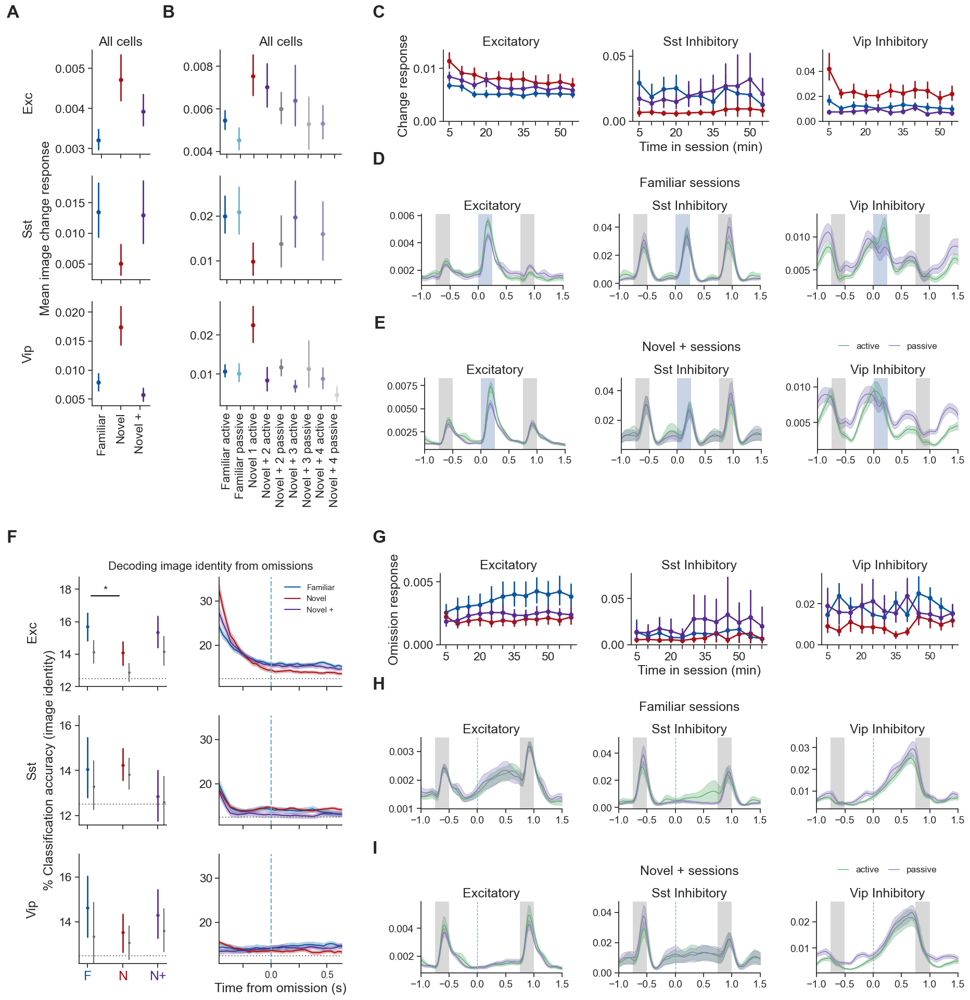

In [75]:
# ==========================================================================
# Figure S8 composite  (Rate of familiarization, modulation by task engagement)
# Two schematic strips ("Image change" above A/C, "Image omission" between E and F)
# are intentionally left BLANK (no panel) per the design.
#
# Each panel rebuilds its data from the STABLE base mdfs loaded in the cell above.
# Panel B reconstructs its own df/levels/colors here from `control_change_mdf`.
#
# Requires (all built by the "S8 data loading" cell above):
#   control_change_mdf, change_mdf_epochs, omission_mdf_epochs,
#   passive_change_mdf, passive_omission_mdf, active_passive_experiment_table,
#   platform_experiments, and svm_agg['decode_next_image_from_omissions'].
# Run order: imports -> config -> metadata -> SVM cell -> S8 data loading -> this.
# ==========================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, show_label_gutters, check_label_overlap,
    auto_fit_bottom, snug_left_to_gutter, snug_top_to_gutter)

sns.set_context('notebook', font_scale=1.5)
CT = utils.get_cell_types()

FIGSIZE = (18.5, 21.0)
REGIONS = {
    'A': [0.0,    0.1555, 0.0713, 0.5064], 'B': [0.1685, 0.3523, 0.0713, 0.5064],
    'C': [0.3848, 0.9959, 0.0713, 0.2024],
    'D': [0.3827, 0.9959, 0.2064, 0.3364],
    'E': [0.3858, 0.9959, 0.3404, 0.4851],
    'F': [0.0041, 0.3523, 0.55,   0.9734],
    'G': [0.3817, 0.9949, 0.5617, 0.7109],
    'H': [0.3817, 0.9949, 0.7149, 0.8407],
    'I': [0.3817, 0.9949, 0.8447, 0.9872],
}

# Even vertical grid for the right-column response rows (C/D/E top, G/H/I bottom).
# Every plot gets the same spine height (_RC_H) and the same spine-top pitch (_RC_P)
# within a triplet. The top triplet starts at C's top; the bottom triplet starts at
# F's top so the G panel letter lines up with F. D/E/H/I carry one extra header line
# (the active/passive row title), so their region tops sit one title line higher,
# which keeps the PLOTS evenly spaced even though the headers differ.
_pt = 1.0 / 72 / FIGSIZE[1]
_RC_H = 0.065                       # plot spine height (identical for all six rows)
_RC_P = 0.150                       # spine-top-to-spine-top pitch within a triplet
_RC_GUT = 28 * _pt                  # label-gutter height (matches DEFAULT_LABEL_GUTTER_PT)
_RC_LINE = 28 * _pt                 # one title line (matches DEFAULT_TITLE_ROOM_PT)
_rc_spine = {'C': REGIONS['C'][2] + _RC_GUT + _RC_LINE,
             'G': REGIONS['F'][2] + _RC_GUT + _RC_LINE}
_rc_spine['D'] = _rc_spine['C'] + _RC_P
_rc_spine['E'] = _rc_spine['C'] + 2 * _RC_P
_rc_spine['H'] = _rc_spine['G'] + _RC_P
_rc_spine['I'] = _rc_spine['G'] + 2 * _RC_P
_rc_lines = {'C': 1, 'D': 2, 'E': 2, 'G': 1, 'H': 2, 'I': 2}
for _lbl, _st in _rc_spine.items():
    _x0, _x1 = REGIONS[_lbl][0], REGIONS[_lbl][1]
    REGIONS[_lbl] = [_x0, _x1, _st - _RC_GUT - _RC_LINE * _rc_lines[_lbl], _st + _RC_H + 0.028]

A_LEFT_DEC = 98          # A leftmost: long rotated metric label + cell-type outer text
F_LEFT_DEC = 90          # F leftmost decoding ylabel; also right-stack left decoration
WSPACE_ROW = 0.4         # within-row spacing for 1x3 panels (C/D/E/G/H/I)
ap_palette = [sns.color_palette()[2], sns.color_palette()[4]]   # active (green) / passive (purple)
_AP_LEG_Y = 1.28   # height (axes fraction) of the active/passive legend above the Vip axis; nudge if it clips


def _row_header(axlist, region, text):
    """Centered text just above the cell-type titles, close to the plot axes."""
    ps = [a.get_position() for a in axlist]
    x = (min(p.x0 for p in ps) + max(p.x1 for p in ps)) / 2
    y = max(p.y1 for p in ps) + (34 / 72 / FIGSIZE[1])
    fig.text(x, y, text, ha='center', va='bottom', fontsize=18)


fig = plt.figure(figsize=FIGSIZE)
fig_setup(fig)

# ---------------- Image change section (A-E) ----------------

# ---- A: mean image change response, All cells by experience (F/N/N+) ----
tmpA = control_change_mdf.copy()
tmpA = tmpA[tmpA.project_code != 'VisualBehaviorMultiscope4areasx2d']
tmpA = utilities.limit_to_containers_with_all_experience_levels(tmpA)
tmpA = tmpA[tmpA.ophys_experiment_id.isin(platform_experiments.index.values)]
axA = panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', has_title=True, dim=(3, 1),
            decoration_pt=(A_LEFT_DEC, 0))
ppf.plot_metric_across_exposures(
    tmpA, 'mean_response', 'Mean image change response', plot_type='pointplot',
    x_val='experience_level', x_vals=utils.get_experience_levels(),
    palette=utils.get_experience_level_colors(), save_dir=None, folder=None, ax=axA)
for a in axA:
    a.set_ylabel(''); a.set_title('')
axA[1].set_ylabel('Mean image change response')
axA[0].set_title('All cells')
for a in axA[:-1]:
    a.tick_params(labelbottom=False)

# ---- B: mean image change response across exposures, active/passive ----
# reconstruct df/levels/colors from the stable base mdf (cells "Exposure level analysis")
_dfB = control_change_mdf.copy()
_dfB = _dfB[_dfB.project_code == 'VisualBehaviorMultiscope']
_dfB = utilities.limit_to_containers_with_all_experience_levels(_dfB)
_nps = _dfB[_dfB.prior_exposures_to_image_set <= 3].ophys_session_id.unique()
_fss = _dfB[(_dfB.experience_level == 'Familiar') & (_dfB.n_relative_to_first_novel <= 3)].ophys_session_id.unique()
_dfB = _dfB[_dfB.ophys_session_id.isin(np.hstack([_nps, _fss]))]
_dfB['prior_exposures_to_image_set'] = [int(x) for x in _dfB.prior_exposures_to_image_set.values]
def _passive_str(p):
    return 'passive' if p else 'active'
_dfB['experience_level'] = [
    _dfB.iloc[i].experience_level + ' ' + str(_dfB.iloc[i].prior_exposures_to_image_set + 1) + ' ' + _passive_str(_dfB.iloc[i].passive)
    if 'Familiar' not in _dfB.iloc[i].experience_level
    else _dfB.iloc[i].experience_level + ' ' + _passive_str(_dfB.iloc[i].passive)
    for i in range(len(_dfB))]
_levels = np.sort(_dfB.experience_level.unique())
_levels = list(_levels[:2]) + [_levels[-1]] + list(_levels[2:-1])
_ec = utils.get_experience_level_colors()
_active_colors = sns.color_palette('Purples_r', 6)[:3]
_passive_colors = sns.color_palette('Greys_r', 6)[2:6]
_colors = [_ec[0], sns.color_palette()[9], _ec[1],
           _active_colors[0], _passive_colors[0],
           _active_colors[1], _passive_colors[1],
           _active_colors[2], _passive_colors[2]]
axB = panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', has_title=True, dim=(3, 1))
ppf.plot_metric_across_exposures(
    _dfB, 'mean_response', 'Mean image change response', plot_type='pointplot',
    x_val='experience_level', x_vals=_levels, palette=_colors, save_dir=None, folder=None, ax=axB)
for a in axB:
    a.set_ylabel(''); a.set_title('')
axB[0].set_title('All cells')
for a in axB[:-1]:
    a.tick_params(labelbottom=False)

# ---- C: within-session change response across mins (1x3) ----
axC = panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C', has_title=True, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_mean_response_by_epoch(
    change_mdf_epochs, metric='mean_response', horizontal=True, ymin=0,
    ylabel='Change response', estimator=np.mean, epoch_dur_mins=5,
    markersize=5, linewidth=2.0, err_linewidth=2.0,
    save_dir=None, folder=None, max_epoch=11, suptitle=None, suffix='',
    ax=list(np.array(axC).ravel()))
for a in (axC[1], axC[2]):
    a.set_ylabel('')
# label only every 3rd x-tick (keep all tick marks)
for a in axC:
    _labs = [t.get_text() for t in a.get_xticklabels()]
    a.set_xticklabels([s if i % 3 == 0 else '' for i, s in enumerate(_labs)])
for a in axC:
    a.set_xlabel('')
axC[1].set_xlabel('Time in session (min)')

# ---- D: active vs passive change pop avg, Familiar (1x3) ----
_dfD = passive_change_mdf.copy()
_dfD = _dfD[_dfD.ophys_experiment_id.isin(active_passive_experiment_table.index.values)]
_dfD = _dfD[_dfD.experience_level == 'Familiar']
axD = panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D', has_title=True, title_lines=2, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_population_averages_for_conditions(
    _dfD, data_type, 'changes', 'cell_type', 'passive', horizontal=True,
    ylabel='Calcium event\nmagnitude', xlabel='Time from image change (s)',
    xlim_seconds=[-1., 1.5], interval_sec=0.5, palette=ap_palette, legend=False,
    suptitle=None, save_dir=None, ax=list(np.array(axD).ravel()))
for a in (axD[1], axD[2]):
    a.set_ylabel('')


# ---- E: active vs passive change pop avg, Novel + (1x3) ----
_dfE = passive_change_mdf.copy()
_dfE = _dfE[_dfE.ophys_experiment_id.isin(active_passive_experiment_table.index.values)]
_dfE = _dfE[_dfE.experience_level == 'Novel +']
axE = panel(fig, REGIONS['E'][:2], REGIONS['E'][2:], 'E', has_title=True, title_lines=2, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_population_averages_for_conditions(
    _dfE, data_type, 'changes', 'cell_type', 'passive', horizontal=True,
    ylabel='Calcium event\nmagnitude', xlabel='Time from image change (s)',
    xlim_seconds=[-1., 1.5], interval_sec=0.5, palette=ap_palette, legend=False,
    suptitle=None, save_dir=None, ax=list(np.array(axE).ravel()))
for a in (axE[1], axE[2]):
    a.set_ylabel('')

# active/passive legend above the rightmost (Vip) axis, above its title
_lh = [l for l in axE[2].get_lines() if not l.get_label().startswith('_')][:2]
axE[2].legend(_lh, ['active', 'passive'], loc='lower center', bbox_to_anchor=(0.5, _AP_LEG_Y),
              frameon=False, fontsize='x-small', ncol=2, handlelength=1.2, columnspacing=1.0)

# ---------------- Image omission section (F-I) ----------------

# ---- F: image-identity decoding (window summary + timecourse), 3x2 ----
_dtF = 'decode_next_image_from_omissions'
_agF = svm_agg[_dtF]
axF = panel(fig, REGIONS['F'][:2], REGIONS['F'][2:], 'F', dim=(3, 2),
            width_ratios=[1, 1.4], wspace=0.5, hspace=0.0, decoration_pt=(F_LEFT_DEC, 28))
_F0 = [axF[r][0] for r in range(3)]   # window-summary point-plots
_F1 = [axF[r][1] for r in range(3)]   # time-resolved traces
ppf.plot_decoding_window_summary(_agF['wm'], _dtF, axes=_F0)
ppf.plot_decoding_timecourse(_agF['labeled'], _dtF, _agF['t'], axes=_F1)
for _a in _F0 + _F1:
    _a.set_title('')
for _a in (_F0[0], _F0[1], _F1[0], _F1[1]):
    _a.tick_params(labelbottom=False)
_F0[1].set_ylabel('% Classification accuracy (image identity)')
_F1[1].set_ylabel('')
_F0[2].tick_params(axis='x', labelsize=18)
_legF = _F1[0].get_legend()
if _legF is not None:
    _hF = _legF.legend_handles
    _lF = [_t.get_text() for _t in _legF.get_texts()]
    _F1[0].legend(_hF, _lF, loc='upper right', frameon=False, fontsize=11)
# share y-range across the right (timecourse) column
_yl_F1 = (min(a.get_ylim()[0] for a in _F1), max(a.get_ylim()[1] for a in _F1))
for _a in _F1:
    _a.set_ylim(_yl_F1)

# ---- G: within-session omission response across mins (1x3) ----
axG = panel(fig, REGIONS['G'][:2], REGIONS['G'][2:], 'G', has_title=True, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_mean_response_by_epoch(
    omission_mdf_epochs, metric='mean_response', horizontal=True, ymin=0,
    ylabel='Omission response', estimator=np.mean, epoch_dur_mins=5,
    markersize=5, linewidth=2.0, err_linewidth=2.0,
    save_dir=None, folder=None, max_epoch=12, suptitle=None, suffix='',
    ax=list(np.array(axG).ravel()))
for a in (axG[1], axG[2]):
    a.set_ylabel('')
# label only every 3rd x-tick (keep all tick marks)
for a in axG:
    _labs = [t.get_text() for t in a.get_xticklabels()]
    a.set_xticklabels([s if i % 3 == 0 else '' for i, s in enumerate(_labs)])
for a in axG:
    a.set_xlabel('')
axG[1].set_xlabel('Time in session (min)')

# ---- H: active vs passive omission pop avg, Familiar (1x3) ----
_dfH = passive_omission_mdf.copy()
_dfH = _dfH[_dfH.ophys_experiment_id.isin(active_passive_experiment_table.index.values)]
_dfH = _dfH[_dfH.experience_level == 'Familiar']
axH = panel(fig, REGIONS['H'][:2], REGIONS['H'][2:], 'H', has_title=True, title_lines=2, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_population_averages_for_conditions(
    _dfH, data_type, 'omissions', 'cell_type', 'passive', horizontal=True,
    ylabel='Calcium event\nmagnitude', xlabel='Time from image omission (s)',
    xlim_seconds=[-1., 1.5], interval_sec=0.5, palette=ap_palette, legend=False,
    suptitle=None, save_dir=None, ax=list(np.array(axH).ravel()))
for a in (axH[1], axH[2]):
    a.set_ylabel('')

# ---- I: active vs passive omission pop avg, Novel + (1x3) ----
_dfI = passive_omission_mdf.copy()
_dfI = _dfI[_dfI.ophys_experiment_id.isin(active_passive_experiment_table.index.values)]
_dfI = _dfI[_dfI.experience_level == 'Novel +']
axI = panel(fig, REGIONS['I'][:2], REGIONS['I'][2:], 'I', has_title=True, title_lines=2, dim=(1, 3),
            wspace=WSPACE_ROW, decoration_pt=(F_LEFT_DEC, 0))
ppf.plot_population_averages_for_conditions(
    _dfI, data_type, 'omissions', 'cell_type', 'passive', horizontal=True,
    ylabel='Calcium event\nmagnitude', xlabel='Time from image omission (s)',
    xlim_seconds=[-1., 1.5], interval_sec=0.5, palette=ap_palette, legend=False,
    suptitle=None, save_dir=None, ax=list(np.array(axI).ravel()))
for a in (axI[1], axI[2]):
    a.set_ylabel('')

# active/passive legend above the rightmost (Vip) axis, above its title
_lh = [l for l in axI[2].get_lines() if not l.get_label().startswith('_')][:2]
axI[2].legend(_lh, ['active', 'passive'], loc='lower center', bbox_to_anchor=(0.5, _AP_LEG_Y),
              frameon=False, fontsize='x-small', ncol=2, handlelength=1.2, columnspacing=1.0)


# ---------------- fit + snug + headers + audit ----------------
# Only F is auto bottom-fit; A/B and the six right-column rows go on explicit grids
# below. auto_fit_bottom opens spurious gaps in multi-row panels -- it shifts every
# row up by the bottom-label overflow (~0.06 here) -- so those panels are excluded.
auto_fit_bottom(fig, {k: v for k, v in REGIONS.items() if k == 'F'}, pad_pt=2)
snug_left_to_gutter(fig, REGIONS, only=['B', 'C', 'D', 'E', 'G', 'H', 'I'])
# F: reserve an extra band left of the y-axis decoration for per-row cell-type
# labels (this also narrows F's plots, pulling them right of the label gutter).
_F_LABEL_BAND_PT = 26
snug_left_to_gutter(fig, REGIONS, only=['F'], gutter_pt=(20 + _F_LABEL_BAND_PT, 28))

# A & B: stack the three rows on one shared tight grid (equal heights, small gap) so
# their y-axis spines align top-and-bottom and the inter-row whitespace is minimal.
# B's long rotated x-tick labels overflow downward into the empty band below row 2.
_ab_top = REGIONS['A'][2] + _RC_GUT + _RC_LINE      # row-0 spine top, just under the title gutter
_ab_h = 0.095                                        # row spine height (shared by A & B)
_ab_gap = 0.02                                       # inter-row gap
fig.canvas.draw()
for _axcol in (axA, axB):
    for _r, _a in enumerate(_axcol):
        _top_td = _ab_top + _r * (_ab_h + _ab_gap)
        _p = _a.get_position()
        _a.set_position([_p.x0, 1 - (_top_td + _ab_h), _p.width, _ab_h])

# Lock the six right-column rows to the exact equal-height even grid (snug_left set
# their x; here we set y), so every response plot shares one height and pitch and the
# titles/headers sit right under each top gutter.
fig.canvas.draw()
for _lbl, _axes in {'C': axC, 'D': axD, 'E': axE, 'G': axG, 'H': axH, 'I': axI}.items():
    _bot_bu = 1 - (_rc_spine[_lbl] + _RC_H)
    for _a in _axes:
        _p = _a.get_position()
        _a.set_position([_p.x0, _bot_bu, _p.width, _RC_H])

# A: cell-type outer labels as fixed-x annotations (align across rows)
fig.canvas.draw()
_gx = 20 / 72 / FIGSIZE[0]
_x_ct = REGIONS['A'][0] + _gx + 0.009
_fs = plt.rcParams['axes.labelsize']
for _a, _ct in zip(axA, CT):
    _p = _a.get_position()
    fig.text(_x_ct, (_p.y0 + _p.y1) / 2, _ct[:3], rotation=90, ha='center', va='center', fontsize=_fs)

# row headers (the active/passive condition) above D/E/H/I
fig.canvas.draw()
_row_header(axD, REGIONS['D'], 'Familiar sessions')
_row_header(axE, REGIONS['E'], 'Novel + sessions')
_row_header(axH, REGIONS['H'], 'Familiar sessions')
_row_header(axI, REGIONS['I'], 'Novel + sessions')

# "Population decoding" suptitle over F's two columns
fig.canvas.draw()
_fp0 = _F0[0].get_position(); _fp1 = _F1[0].get_position()
fig.text((_fp0.x0 + _fp1.x1) / 2, max(_fp0.y1, _fp1.y1) + 0.005, 'Decoding image identity from omissions',
         ha='center', va='bottom', fontsize=16)

# F: cell-type outer labels (one per row), mirroring panel A's cell-type column
fig.canvas.draw()
_x_ct_F = REGIONS['F'][0] + _gx + 0.009
for _a, _ct in zip(_F0, CT):
    _p = _a.get_position()
    fig.text(_x_ct_F, (_p.y0 + _p.y1) / 2, _ct[:3], rotation=90, ha='center', va='center', fontsize=_fs)

check_label_overlap(fig, REGIONS)
utils.save_figure(fig, FIGSIZE, save_dir, 'composite', 'figure_S8_composite', formats=['.png', '.pdf'])
plt.show()


In [76]:
stats_capture_save(save_dir, 'composite', 'figure_S8_composite_stats')

stats capture: wrote 9 rows from 3 panel stat-tables -> /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/figure_3_supplemental/composite/figure_S8_composite_stats.csv


,_metric,_cell_type,_column_to_compare,_source_fn,metric,event_type,cell_type,column_to_compare,groups,group1,...,sem2_mouse,std1_mouse,std2_mouse,ci1_low_mouse,ci2_low_mouse,ci1_high_mouse,ci2_high_mouse,n1_mouse,n2_mouse,one_way_anova_p_val
0,decoding_accuracy,Excitatory,None,compute_stats,decoding_accuracy,omission,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.529799,2.728422,3.089233,14.216125,12.997880,16.120108,15.153648,34,34,0.017337
1,decoding_accuracy,Excitatory,None,compute_stats,decoding_accuracy,omission,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.728157,2.728422,4.245850,14.216125,14.224498,16.120108,17.187391,34,34,0.565934
2,decoding_accuracy,Excitatory,None,compute_stats,decoding_accuracy,omission,Excitatory,experience_level,"(Familiar, Novel, Novel +)",Novel,...,0.728157,3.089233,4.245850,12.997880,14.224498,15.153648,17.187391,34,34,0.057629
3,decoding_accuracy,Sst Inhibitory,None,compute_stats,decoding_accuracy,omission,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.688990,3.851665,2.668448,12.215871,12.797516,16.481832,15.752990,15,15,0.802749
4,decoding_accuracy,Sst Inhibitory,None,compute_stats,decoding_accuracy,omission,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.899566,3.851665,3.365868,12.215871,10.619856,16.481832,14.506645,15,14,0.265238
5,decoding_accuracy,Sst Inhibitory,None,compute_stats,decoding_accuracy,omission,Sst Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Novel,...,0.899566,2.668448,3.365868,12.797516,10.619856,15.752990,14.506645,15,14,0.226850
6,decoding_accuracy,Vip Inhibitory,None,compute_stats,decoding_accuracy,omission,Vip Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.702211,4.499530,2.808843,12.583978,12.071656,17.379239,15.065109,16,16,0.241043
7,decoding_accuracy,Vip Inhibitory,None,compute_stats,decoding_accuracy,omission,Vip Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Familiar,...,0.720474,4.499530,2.881895,12.583978,12.471434,17.379239,15.542741,16,16,0.600289
8,decoding_accuracy,Vip Inhibitory,None,compute_stats,decoding_accuracy,omission,Vip Inhibitory,experience_level,"(Familiar, Novel, Novel +)",Novel,...,0.720474,2.808843,2.881895,12.071656,12.471434,15.065109,15.542741,16,16,0.441385


In [77]:
# --- free memory before S9: drop the S8 dataframes, figures and SVM data ---
EXTRA = {'svm_agg', 'svm_results', 'svm_input_vars', 'active_passive_experiment_table'}
import gc
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes

# Setup tables that later sections still need
_keep = {'experiments_table', 'platform_experiments', 'platform_cells_table', 'behavior_sessions',
         'matched_cells_table', 'metrics_table', 'filtered_events_metrics_table'}

def _is_fig_obj(o):
    if isinstance(o, (Figure, Axes)):
        return True
    try:
        return hasattr(o, '__iter__') and not isinstance(o, (str, dict, pd.DataFrame, pd.Series)) \
            and len(o) > 0 and all(isinstance(a, Axes) for a in np.ravel(o))
    except Exception:
        return False

plt.close('all')
_dropped = []
for _v, _o in list(globals().items()):
    if _v in _keep or _v in ('_STATS_CAPTURE', 'In', 'Out') or _v.startswith('__') or _v.startswith('_i') or _v in ('_', '_oh', '_dh', '_ih'):
        continue
    if isinstance(_o, (pd.DataFrame, pd.Series)) or _is_fig_obj(_o) or _v in EXTRA:
        globals().pop(_v, None)
        _dropped.append(_v)
try:
    get_ipython().run_line_magic('reset', '-f out')   # output cache can hold references to displayed frames
except Exception:
    pass
gc.collect()
print('freed:', sorted(_dropped))


Flushing output cache (1 entries)
freed: ['_76', '_F0', '_F1', '_a', '_axcol', '_axes', '_combined', '_dfB', '_dfD', '_dfE', '_dfH', '_dfI', '_labeled', '_wm', 'a', 'active_passive_experiment_table', 'axA', 'axB', 'axC', 'axD', 'axE', 'axF', 'axG', 'axH', 'axI', 'change_mdf_epochs', 'control_change_mdf', 'fig', 'omission_mdf_epochs', 'passive_change_mdf', 'passive_omission_mdf', 'svm_agg', 'svm_input_vars', 'svm_results', 'tmpA']


# Figure S9 — Control: correlation of single-cell activity with running

Uses the shared imports and metadata from the setup section. Its heavier, section-specific data preparation (steady-state filtering and the per-cell running-metric computation, with joblib parallelism and on-disk caching) runs at the start of this section rather than in the top setup block. The composite saves as `figure_S9` under the shared `figure_3_supplemental/composite/` location.

In [78]:
# Cache directory for per-cell metrics (so we don't re-loop the cache every run)
metrics_cache_dir = os.path.join(loading.get_cell_metrics_dir(), 'running_metrics')
per_exp_cache_dir = os.path.join(metrics_cache_dir, 'per_experiment')
for d in (metrics_cache_dir, per_exp_cache_dir):
    if not os.path.exists(d):
        os.makedirs(d)

experience_levels = utils.get_new_experience_levels()
cell_types = utils.get_cell_types()
exp_palette = utils.get_experience_level_colors()

## Steady-state stimulus presentation filter

Restrict correlation/RMI computation to repeated-image flashes at steady state. Exclude:
- omissions and the flash immediately after an omission (`post_omitted`)
- image changes
- the 4 flashes following each change (covers the change response + reward-consumption window)

Implemented with `time_from_last_change > 4 * FLASH_PERIOD` (flash period = 0.75 s in VBO). Applied in both the per-cell metric computation and the single-cell example loaders so the population stats and the example plots use the same trial set.


In [79]:
# Steady-state stimulus presentation filter (moved to pse)
from visual_behavior.visualization.ophys.platform_single_cell_examples import filter_steady_state_presentations


## Per-cell metric computation

Given a stimulus_response_df for one experiment, compute for each cell:
- `activity_running_corr`, `activity_running_pval` — Pearson correlation of `mean_response` with `mean_running_speed` across stimulus presentations.
- `running_modulation_index` — `(mean_run - mean_stationary) / (mean_run + mean_stationary)`, bounded [-1, 1].
- `n_run_trials`, `n_stationary_trials` — sample sizes for the two running conditions.

Uses `event_type='all'` (all stimulus presentations) per the spec.


In [80]:
RUN_THRESH = 2.0  # cm/s
MIN_TRIALS_PER_CONDITION = 5  # require at least this many stim presentations per run/stationary for RMI


def compute_running_metrics_for_experiment(sdf, run_thresh=RUN_THRESH, min_trials=MIN_TRIALS_PER_CONDITION):
    """Per-cell correlation of mean_response with mean_running_speed and running modulation index.
    Operates on the steady-state subset of stimulus presentations (see filter_steady_state_presentations)."""
    sdf = filter_steady_state_presentations(sdf)
    rows = []
    for csid, cell_df in sdf.groupby('cell_specimen_id'):
        # drop rows missing either metric
        d = cell_df[['mean_response', 'mean_running_speed']].dropna()
        if len(d) < 10:
            continue
        r, p = stats.pearsonr(d['mean_response'].values, d['mean_running_speed'].values)

        run_mask = d['mean_running_speed'] > run_thresh
        stationary_mask = d['mean_running_speed'] < run_thresh
        n_run = int(run_mask.sum())
        n_stationary = int(stationary_mask.sum())
        mean_run = d.loc[run_mask, 'mean_response'].mean() if n_run >= min_trials else np.nan
        mean_stationary = d.loc[stationary_mask, 'mean_response'].mean() if n_stationary >= min_trials else np.nan
        # normalized modulation index, bounded [-1, 1]
        denom = mean_run + mean_stationary
        with np.errstate(divide='ignore', invalid='ignore'):
            rmi = (mean_run - mean_stationary) / denom if (denom not in (0, np.nan)) else np.nan

        rows.append({
            'cell_specimen_id': csid,
            'activity_running_corr': r,
            'activity_running_pval': p,
            'running_modulation_index': rmi,
            'mean_response_run': mean_run,
            'mean_response_stationary': mean_stationary,
            'n_run_trials': n_run,
            'n_stationary_trials': n_stationary,
            'n_trials_total': len(d),
        })
    return pd.DataFrame(rows)

## Get data for all experiments

Loads pre-saved running_metrics_table.csv containing the running_modulation_index and trial by trial correlation of neural activity with running for each cell. Computed by notebook `generate_running_correlation_metrics.ipynb`


In [81]:
metrics_dir = loading.get_cell_metrics_dir()
running_metrics_filepath = os.path.join(metrics_dir, 'running_metrics_table.csv')
if os.path.exists(running_metrics_filepath):
    running_metrics_table = pd.read_csv(running_metrics_filepath, index_col=0)
    print('loaded running metrics table from', running_metrics_filepath)
else:
    print('running metrics table not found at', running_metrics_filepath)
    print('please run visual_behavior.notebooks.platform_paper_figures.compute_running_metrics_table to compute and save the table')

loaded running metrics table from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_analysis_files/cell_metrics/running_metrics_table.csv


In [82]:
# Merge cre_line + experience_level from the platform_experiments table; derive cell_type from cre_line
metrics_table = running_metrics_table.merge(
    platform_experiments[['cell_type', 'experience_level', 'mouse_id', 'ophys_container_id', 'behavior_session_id']].reset_index(),
    on='ophys_experiment_id',
    how='left',)

print(metrics_table[['cell_type', 'experience_level']].value_counts())

# Per-experiment run/stationary balance, derived from the already-cached per-cell counts.
# Running speed is a session-level property, so n_run_trials / n_stationary_trials are
# ~constant across cells within an experiment -> take the median per oeid (no data loading).
expt_balance = (
    metrics_table
    .groupby('ophys_experiment_id')[['n_run_trials', 'n_stationary_trials']]
    .median()
)
expt_balance['run_fraction'] = (
    expt_balance['n_run_trials']
    / (expt_balance['n_run_trials'] + expt_balance['n_stationary_trials'])
)
metrics_table = metrics_table.merge(
    expt_balance[['run_fraction']], on='ophys_experiment_id', how='left'
)

cell_type       experience_level
Excitatory      Novel               7974
                Novel +             7404
                Familiar            7302
Vip Inhibitory  Familiar             794
                Novel +              765
                Novel                718
Sst Inhibitory  Novel                337
                Familiar             321
                Novel +              320
dtype: int64


#### Distribution of correlation values

In [83]:
metrics_table.columns

Index(['cell_specimen_id', 'activity_running_corr', 'activity_running_pval',
       'running_modulation_index', 'mean_response_run',
       'mean_response_stationary', 'n_run_trials', 'n_stationary_trials',
       'n_trials_total', 'ophys_experiment_id', 'cell_type',
       'experience_level', 'mouse_id', 'ophys_container_id',
       'behavior_session_id', 'run_fraction'],
      dtype='object')

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)


<Axes: ylabel='Running\nmodulation'>

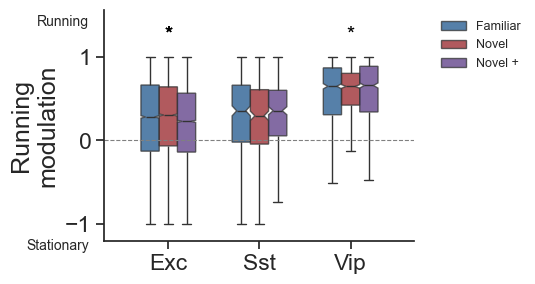

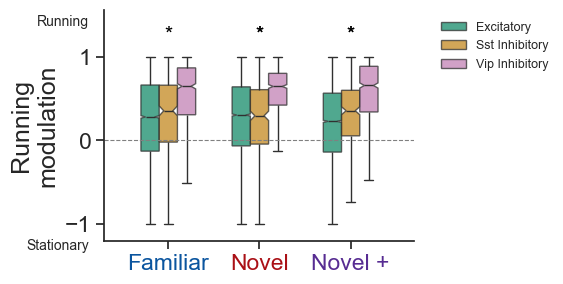

In [84]:
# Single-axis view: cell type on x, experience level as hue
ppf.plot_rmi_distribution_single_axis(metrics_table, metric='running_modulation_index',
    x_col='cell_type', hue_col='experience_level', save_dir=save_dir,
)

# Same data, axes swapped: experience level on x, cell type as hue
ppf.plot_rmi_distribution_single_axis(metrics_table, metric='running_modulation_index',
                                      x_col='experience_level', hue_col='cell_type', save_dir=save_dir,
)


<Axes: ylabel='Activity vs.running\ncorrelation (pearson r)'>

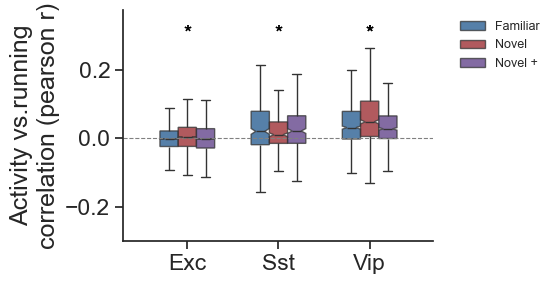

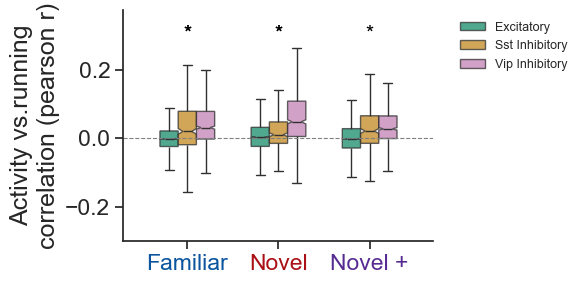

In [85]:
ylims = (-0.3, 0.3)

ppf.plot_correlation_distribution_single_axis(
    metrics_table, x_col='cell_type', hue_col='experience_level', ylims=ylims,
    save_dir=save_dir, save_name='activity_running_corr_celltype_and_experience_hue',
)
ppf.plot_correlation_distribution_single_axis(
    metrics_table, x_col='experience_level', hue_col='cell_type', ylims=ylims,
    save_dir=save_dir, save_name='activity_running_corr_experience_and_celltype_hue',
)

### Top 6 high RMI + bottom 3 low RMI Vip cells from one session (from metrics_table)

Pick a primary Vip example with high RMI from `metrics_table`, load its experiment's sdf once, then preview 9 candidate cells (6 high RMI, 3 low RMI) from the same session so we can choose a good single-cell example without re-loading sdfs.

Uses `plot_running_example_cell` defined in the pre-saved-RMI section above — run that cell first.


In [86]:
# Pick primary Vip example from metrics_table (highest RMI, with trial-count and boundary filters)
MT_MIN_TRIALS = 30
MT_RMI_BOUNDARY = 0.97
# Require a real response in at least one running state (drop near-silent cells).
MIN_RESPONSE = 0.001
# Require example experiments to have roughly balanced running vs stationary flashes.
BALANCE_RANGE = (0.4, 0.6)  # fraction of steady-state flashes that are running

mt_vip = metrics_table[
    (metrics_table.cell_type == 'Vip Inhibitory')
    & (metrics_table.n_run_trials >= MT_MIN_TRIALS)
    & (metrics_table.n_stationary_trials >= MT_MIN_TRIALS)
    & (metrics_table.running_modulation_index.abs() < MT_RMI_BOUNDARY)
    & (metrics_table.run_fraction.between(*BALANCE_RANGE))
    & ((metrics_table.mean_response_run > MIN_RESPONSE)
       | (metrics_table.mean_response_stationary > MIN_RESPONSE))
].copy()
mt_vip = mt_vip.sort_values('running_modulation_index', ascending=False)
print(len(mt_vip), 'eligible Vip cells across all sessions')

mt_example_row = mt_vip.iloc[0]
mt_example_csid = int(mt_example_row['cell_specimen_id'])
mt_example_oeid = int(mt_example_row['ophys_experiment_id'])
mt_example_rmi = float(mt_example_row['running_modulation_index'])
print(f'primary Vip example: csid={mt_example_csid}, oeid={mt_example_oeid}, RMI={mt_example_rmi:.3f}')

# Load sdf for that experiment once
mt_example_dataset = loading.get_ophys_dataset(mt_example_oeid)
mt_example_sdf = loading.get_stimulus_response_df(
    mt_example_dataset,
    time_window=[-2, 2.1],
    interpolate=True,
    output_sampling_rate=30,
    data_type='events',
    event_type='all',
    load_from_file=True,
)
print('loaded sdf for experiment', mt_example_oeid)


380 eligible Vip cells across all sessions
primary Vip example: csid=1086556696, oeid=1004889552, RMI=0.970


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

file exists:
loading response df from file for 1004889552 events all
sdf loaded
loaded sdf for experiment 1004889552


7 eligible Vip cells in experiment 1004889552

Top 6 high RMI:
    cell_specimen_id  running_modulation_index  activity_running_corr  \
11        1086556696                  0.969840               0.123412   
21        1086562780                  0.940805               0.130916   
9         1086555432                  0.931157               0.065467   
16        1086559446                  0.877818               0.103476   
29        1086567589                  0.860941               0.088063   
14        1086558904                  0.807322               0.155336   

    activity_running_pval  
11           2.759451e-14  
21           6.706305e-16  
9            5.689048e-05  
16           1.857593e-10  
29           5.979157e-08  
14           8.061766e-22  

Bottom 3 low RMI:
    cell_specimen_id  running_modulation_index  activity_running_corr  \
29        1086567589                  0.860941               0.088063   
14        1086558904                  0.807322               0.1

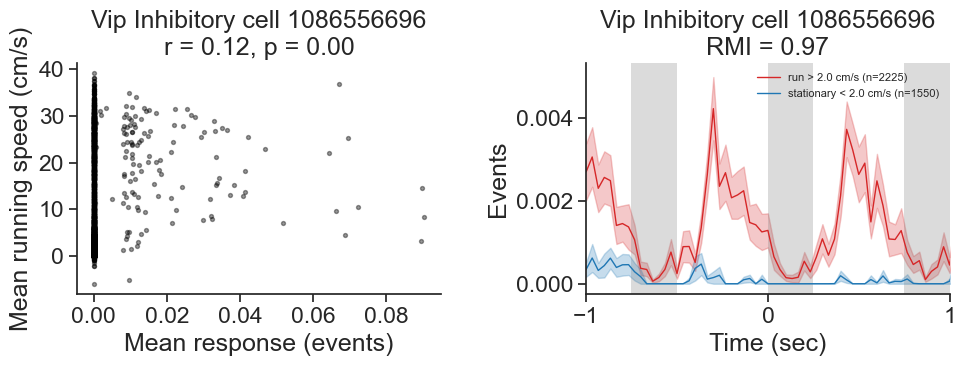

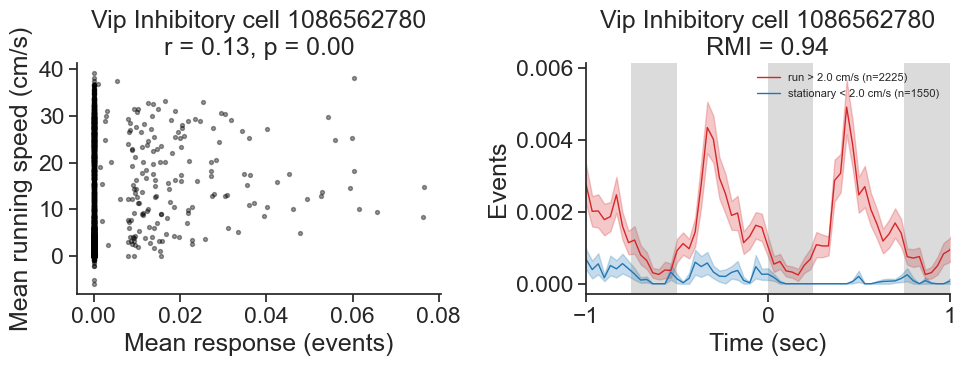

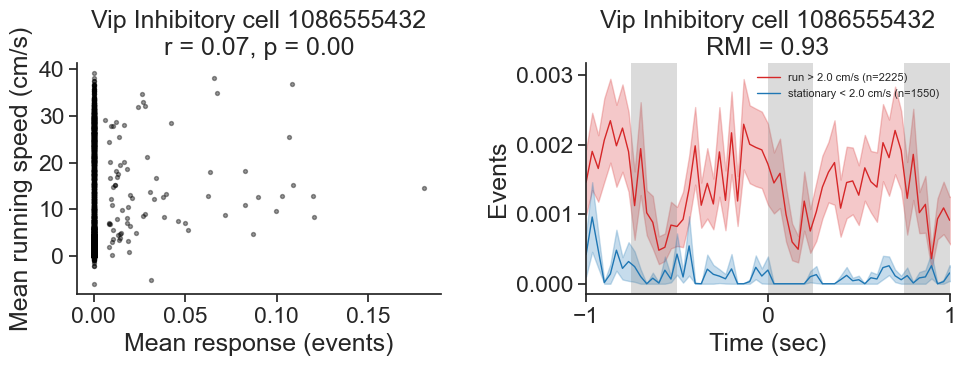

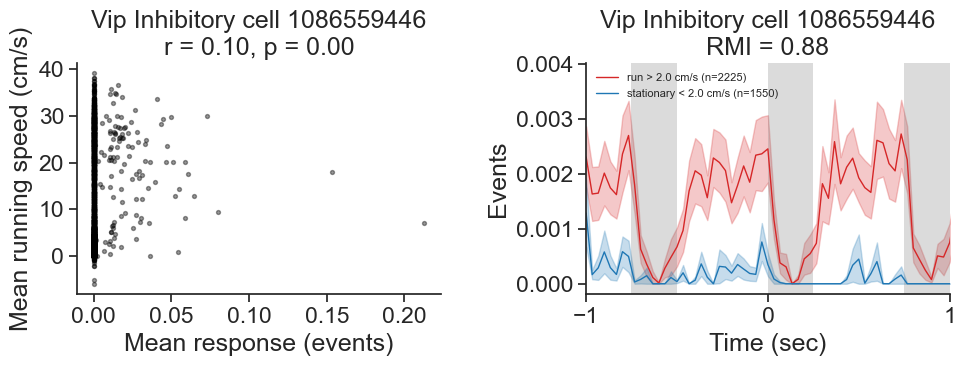

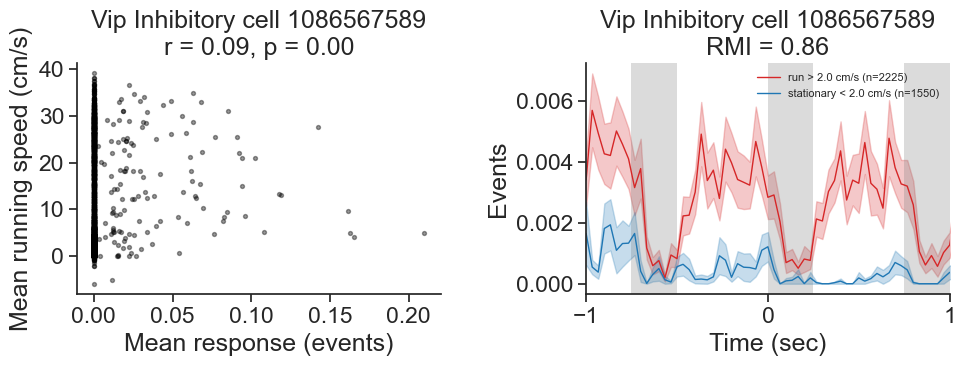

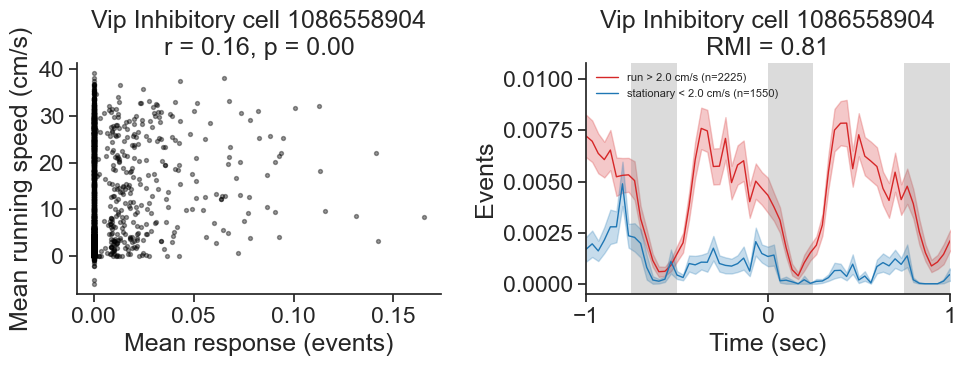

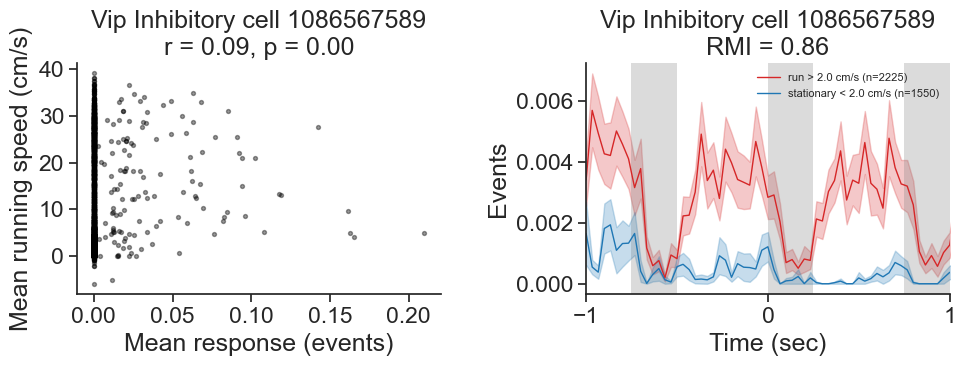

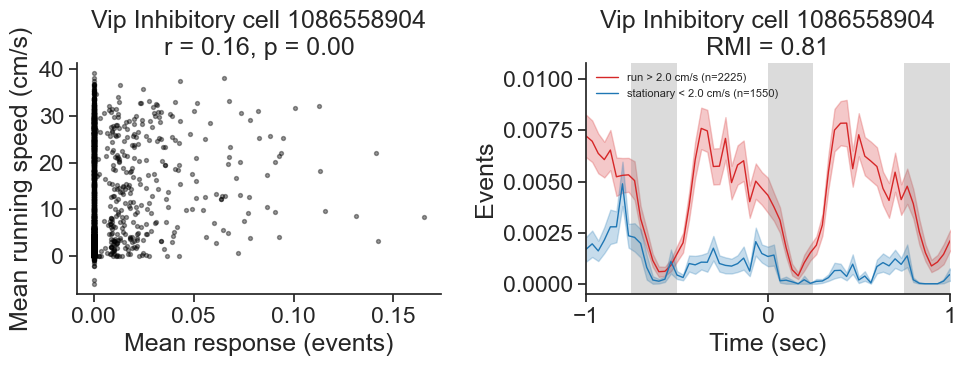

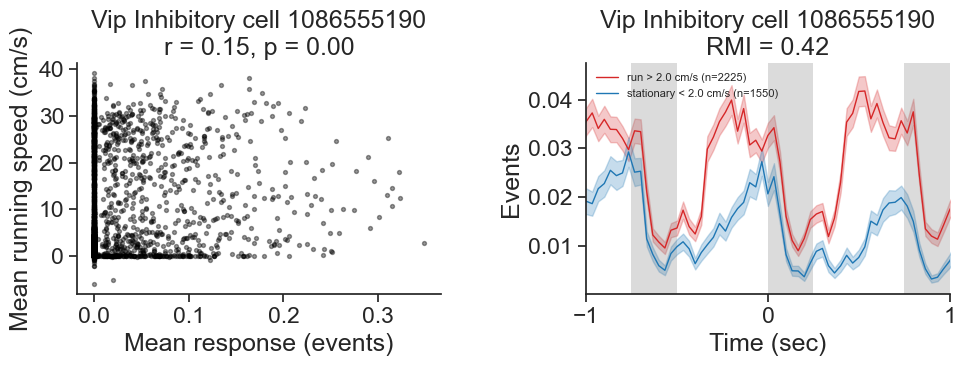

In [87]:
# Top 6 high RMI + bottom 3 low RMI Vip cells from the same session
session_vip = mt_vip[mt_vip.ophys_experiment_id == mt_example_oeid].copy()
session_vip = session_vip.sort_values('running_modulation_index', ascending=False)
print(len(session_vip), 'eligible Vip cells in experiment', mt_example_oeid)

top6 = session_vip.head(6)
bottom3 = session_vip.tail(3)
print('\nTop 6 high RMI:')
print(top6[['cell_specimen_id', 'running_modulation_index',
            'activity_running_corr', 'activity_running_pval']])
print('\nBottom 3 low RMI:')
print(bottom3[['cell_specimen_id', 'running_modulation_index',
               'activity_running_corr', 'activity_running_pval']])

for label, group in [('high', top6), ('low', bottom3)]:
    for _, row in group.iterrows():
        csid = int(row['cell_specimen_id'])
        rmi = float(row['running_modulation_index'])
        pse.plot_running_example_cell(
            mt_example_sdf, csid, 'Vip Inhibitory', rmi,
            save_dir=None, 
            save_name=f'metrics_table_rmi_{label}_vip_{csid}',
        )
        plt.show()


### Top 6 / bottom 3 activity-running correlation Vip cells from one session

Same idea as the RMI loop above but ranked by `activity_running_corr` (with significant p<0.05). Reuses `mt_example_sdf` if from the same experiment; otherwise loads a new sdf.


In [88]:
# Pick primary Vip example by correlation (sig p, with trial-count and boundary filters)
MT_CORR_PVAL_THRESH = 0.05
# Top correlation examples must have a Pearson r above this (correlation picks only).
MIN_CORR = 0.5

mt_vip_corr = metrics_table[
    (metrics_table.cell_type == 'Vip Inhibitory')
    & (metrics_table.n_run_trials >= MT_MIN_TRIALS)
    & (metrics_table.n_stationary_trials >= MT_MIN_TRIALS)
    # & (metrics_table.running_modulation_index.abs() < MT_RMI_BOUNDARY)
    & (metrics_table.activity_running_pval < MT_CORR_PVAL_THRESH)
    & (metrics_table.run_fraction.between(*BALANCE_RANGE))
    & ((metrics_table.mean_response_run > MIN_RESPONSE)
       | (metrics_table.mean_response_stationary > MIN_RESPONSE))
].copy()
mt_vip_corr = mt_vip_corr.sort_values('activity_running_corr', ascending=False)
print(len(mt_vip_corr), 'eligible Vip cells (sig p) across all sessions')

# Require the top correlation example to exceed MIN_CORR
mt_corr_example_row = mt_vip_corr[mt_vip_corr.activity_running_corr > MIN_CORR].iloc[0]
mt_corr_example_csid = int(mt_corr_example_row['cell_specimen_id'])
mt_corr_example_oeid = int(mt_corr_example_row['ophys_experiment_id'])
mt_corr_example_r = float(mt_corr_example_row['activity_running_corr'])
print(f'primary Vip example: csid={mt_corr_example_csid}, oeid={mt_corr_example_oeid}, r={mt_corr_example_r:.3f}')

# Reuse mt_example_sdf if it's the same experiment, otherwise load
if 'mt_example_sdf' in dir() and mt_corr_example_oeid == mt_example_oeid:
    mt_corr_example_sdf = mt_example_sdf
    print('reusing mt_example_sdf from RMI section')
else:
    _ds = loading.get_ophys_dataset(mt_corr_example_oeid)
    mt_corr_example_sdf = loading.get_stimulus_response_df(
        _ds, time_window=[-2, 2.1], interpolate=True, output_sampling_rate=30,
        data_type='events', event_type='all', load_from_file=True,
    )
    print('loaded sdf for experiment', mt_corr_example_oeid)


312 eligible Vip cells (sig p) across all sessions
primary Vip example: csid=1086573413, oeid=921024189, r=0.517


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

file exists:
loading response df from file for 921024189 events all
sdf loaded
loaded sdf for experiment 921024189


12 eligible Vip cells in experiment 921024189

Top 6 high corr:
       cell_specimen_id  activity_running_corr  activity_running_pval  \
15142        1086573413               0.517003          1.556834e-242   

       running_modulation_index  
15142                  0.882877  

Bottom 3 low corr:
       cell_specimen_id  activity_running_corr  activity_running_pval  \
15150        1086576860               0.162032           2.305148e-22   
15145        1086574420               0.149014           4.013981e-19   
15146        1086574952               0.080602           1.474765e-06   

       running_modulation_index  
15150                  0.825608  
15145                  0.729248  
15146                  0.670589  


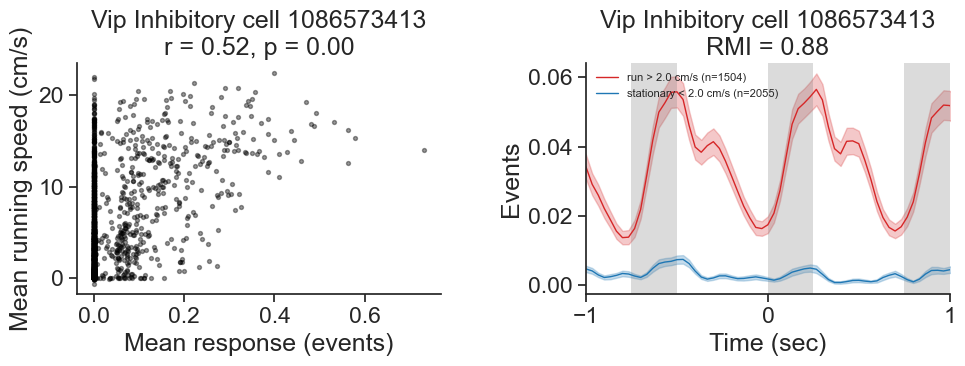

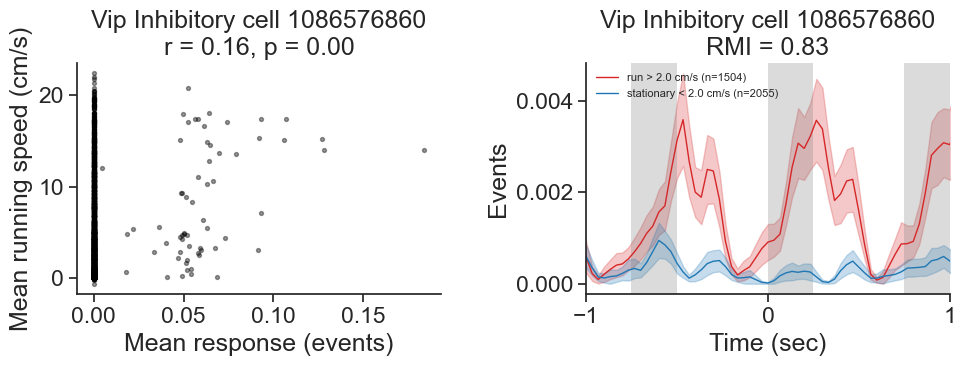

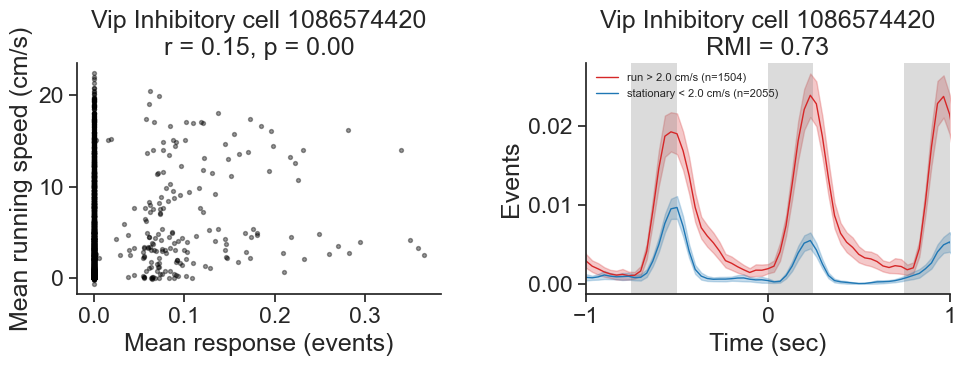

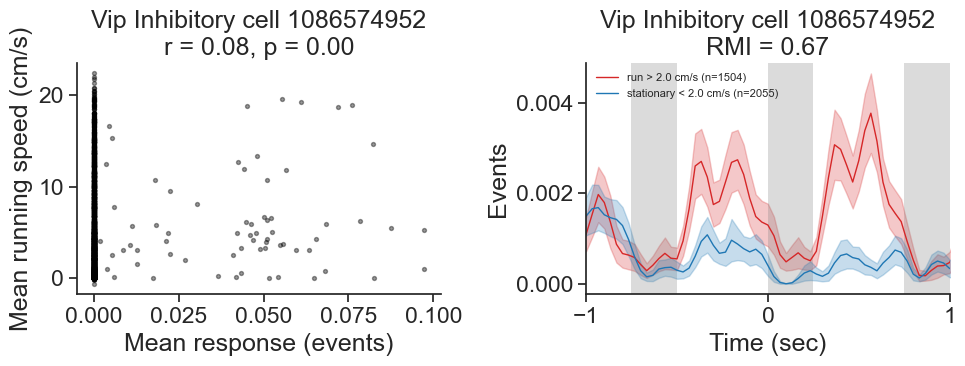

In [89]:
# Top 6 high corr + bottom 3 low corr Vip cells (sig p) from the same session
session_vip_corr = mt_vip_corr[mt_vip_corr.ophys_experiment_id == mt_corr_example_oeid].copy()
session_vip_corr = session_vip_corr.sort_values('activity_running_corr', ascending=False)
print(len(session_vip_corr), 'eligible Vip cells in experiment', mt_corr_example_oeid)

top6_corr = session_vip_corr[session_vip_corr.activity_running_corr > MIN_CORR].head(6)
bottom3_corr = session_vip_corr.tail(3)
print('\nTop 6 high corr:')
print(top6_corr[['cell_specimen_id', 'activity_running_corr',
                 'activity_running_pval', 'running_modulation_index']])
print('\nBottom 3 low corr:')
print(bottom3_corr[['cell_specimen_id', 'activity_running_corr',
                    'activity_running_pval', 'running_modulation_index']])

for label, group in [('high', top6_corr), ('low', bottom3_corr)]:
    for _, row in group.iterrows():
        csid = int(row['cell_specimen_id'])
        rmi = float(row['running_modulation_index'])
        pse.plot_running_example_cell(
            mt_corr_example_sdf, csid, 'Vip Inhibitory', rmi,
            save_dir=save_dir,
            save_name=f'metrics_table_corr_{label}_vip_{csid}',
        )
        plt.show()


## Change in Neural Activity vs. Change in Behavior

Scatter plots showing the relationship between the change in neural response metrics
(Familiar to Novel) vs. the change in behavioral metrics (running speed, pupil diameter,
d-prime) across mice. Each point is one mouse, split by cell type.

Source: `251202_compare_behavior_and_novelty_response.ipynb` cells 65-80

#### Load cell metrics

In [90]:
data_type = 'filtered_events'
session_subset = 'full_session'
inclusion_criteria = 'platform_experiment_table'

metrics_dir = loading.get_cell_metrics_dir()
filepath = os.path.join(metrics_dir, f'merged_model_free_metrics_table_{data_type}_{inclusion_criteria}.csv')
filtered_events_metrics_table = pd.read_csv(filepath, index_col=0)

metrics_table = filtered_events_metrics_table.copy()

# Merge with platform experiments
metrics_table = metrics_table.merge(platform_experiments.reset_index(),
                                   on=['ophys_experiment_id', 'experience_level'])


#### Load behavior metrics

In [91]:
# Drop metrics cols because we will get them elsewhere
from visual_behavior.data_access import utilities


cols_to_drop = ['engaged_trial_count',
       'false_alarm_trial_count', 'trial_count', 'go_trial_count',
       'correct_reject_trial_count', 'catch_trial_count', 'file_id',
       'hit_trial_count', 'miss_trial_count',]

# Only mice included in this study (i.e. excluding project code VisualBehaviorMultiscope4areasx2d)
# platform_behavior_sessions = pd.read_csv(os.path.join(loading.get_platform_analysis_cache_dir(), 'platform_behavior_sessions_table.csv'), index_col=0)
# platform_behavior_sessions = platform_behavior_sessions.drop(columns=cols_to_drop)
# platform_behavior_sessions = utilities.add_behavior_stage_to_behavior_sessions(platform_behavior_sessions)
# platform_behavior_sessions['mouse_id'] = [int(mouse_id) for mouse_id in platform_behavior_sessions.mouse_id.values]

# Limited to sessions with ophys data
platform_ophys_behavior_sessions = pd.read_csv(os.path.join(loading.get_platform_analysis_cache_dir(), 'platform_ophys_behavior_sessions_table.csv'), index_col=0)
platform_ophys_behavior_sessions = platform_ophys_behavior_sessions.drop(columns=cols_to_drop)
platform_ophys_behavior_sessions['mouse_id'] = [int(mouse_id) for mouse_id in platform_ophys_behavior_sessions.mouse_id.values]

# Save to more convenient name
behavior_sessions = platform_ophys_behavior_sessions.copy()

In [92]:
import visual_behavior.utilities as vbu


In [93]:
behavior_metrics_dir = loading.get_performance_metrics_dir()

# Behavior metrics computed by AllenSDK
behavior_stats_sdk = pd.read_hdf(os.path.join(behavior_metrics_dir, 'sdk_all_sessions.h5'), key='data')
behavior_stats_sdk.index.name = 'behavior_session_id'
behavior_stats_sdk = behavior_stats_sdk.reset_index()  # move behavior_session_id from index to column
behavior_stats_sdk = behavior_stats_sdk.merge(behavior_sessions, on='behavior_session_id', how='left')
# Limit to platform paper mice 
behavior_stats_sdk = behavior_stats_sdk[behavior_stats_sdk.mouse_id.isin(behavior_sessions.mouse_id.unique())]
behavior_stats_sdk['mouse_id'] = [int(mouse_id) for mouse_id in behavior_stats_sdk.mouse_id.values]

# Behavior metrics computed on a flash by flash basis, limited to engaged portions of session
engaged_behavior_stats_stim = pd.read_hdf(os.path.join(behavior_metrics_dir, 'stimulus_based_engaged_only_all_sessions.h5'), key='data')
engaged_behavior_stats_stim = engaged_behavior_stats_stim.merge(behavior_sessions, on='behavior_session_id', how='left')
# Limit to platform paper mice 
engaged_behavior_stats_stim = engaged_behavior_stats_stim[engaged_behavior_stats_stim.behavior_session_id.isin(behavior_sessions.index.unique())]


# Behavior metrics computed on a flash by flash basis, limited to engaged portions of session
behavior_stats_stim = pd.read_hdf(os.path.join(behavior_metrics_dir, 'stimulus_based_all_sessions.h5'), key='data')
behavior_stats_stim = behavior_stats_stim.merge(behavior_sessions, on='behavior_session_id', how='left')
# Limit to platform paper mice 
behavior_stats_stim = behavior_stats_stim[behavior_stats_stim.behavior_session_id.isin(behavior_sessions.index.unique())]


# Load platform behavior stats for stimulus-based metrics
platform_behavior_stats = pd.read_csv(os.path.join(behavior_metrics_dir,  'platform_behavior_stats_engaged.csv'), index_col=0)
platform_behavior_stats = platform_behavior_stats.merge(behavior_sessions, on='behavior_session_id', how='left')
# Limit to platform paper mice 
platform_behavior_stats = platform_behavior_stats[platform_behavior_stats.behavior_session_id.isin(behavior_sessions.index.unique())]


In [94]:
# Get running speed metrics for each session
running_speed_mdf_images = loading.get_behavior_multi_session_df('running_speed', 'images', platform_experiments, epoch_duration_mins=None)
running_speed_mdf_changes = loading.get_behavior_multi_session_df('running_speed', 'changes', platform_experiments, epoch_duration_mins=None)

running_speed_mdf_images['mouse_id'] = [int(mouse_id) for mouse_id in running_speed_mdf_images.mouse_id.values]
running_speed_mdf_changes['mouse_id'] = [int(mouse_id) for mouse_id in running_speed_mdf_changes.mouse_id.values]

# Average across mice for subsequent analysis
running_speed_mdf_changes['mean_run_speed_changes'] = running_speed_mdf_changes.mean_response
running_speed_mdf_images['mean_run_speed_images'] = running_speed_mdf_images.mean_response

condition_type = 'mean_run_speed_images'
running_metrics_images = running_speed_mdf_images.groupby(['mouse_id', 'cell_type', 'experience_level', 'behavior_session_id']).median()[[condition_type]].reset_index()

condition_type = 'mean_run_speed_changes'
running_metrics_changes = running_speed_mdf_changes.groupby(['mouse_id', 'cell_type', 'experience_level', 'behavior_session_id']).median()[[condition_type]].reset_index()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_running_speed_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_running_speed_all_is_change_platform_experiment_table.feather
there are 1880 experiments in the full multi_session_df
there are 402 experiments in the multi_session_df after limiting to platform experiments
there are 402 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)


1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_running_speed_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_running_speed_all_is_change_platform_experiment_table.feather
there are 1880 experiments in the full multi_session_df
there are 402 experiments in the multi_session_df after limiting to platform experiments
there are 402 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_block_name`.

The data that was available in previous releases are stored in the block name containing 'change_detection' and can be accessed in the pandas table by using: 
	`stimulus_presentations[stimulus_presentations.stimulus_block_name.str.contains('change_detection')]`
  warnings.warn(
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_19725/756690910.py:13: FutureWarning: The default value of numeric_only in DataFrameGroupBy.median is deprecated. In a fu

In [95]:
image_mdf = loading.get_behavior_multi_session_df('pupil_width', 'images', platform_experiments, epoch_duration_mins=None)
print(len(image_mdf.ophys_experiment_id.unique()), 'experiments')

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_pupil_width_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_pupil_width_all_is_change_platform_experiment_table.feather
there are 1876 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table
201 experiments


In [96]:
# Get pupil diameter metrics for each session
pupil_mdf_images = loading.get_behavior_multi_session_df('pupil_width', 'images', platform_experiments, epoch_duration_mins=None)
pupil_mdf_changes = loading.get_behavior_multi_session_df('pupil_width', 'changes', platform_experiments, epoch_duration_mins=None)

pupil_mdf_images['mouse_id'] = [int(mouse_id) for mouse_id in pupil_mdf_images.mouse_id.values]
pupil_mdf_changes['mouse_id'] = [int(mouse_id) for mouse_id in pupil_mdf_changes.mouse_id.values]

pupil_mdf_images['mean_pupil_width_images'] = pupil_mdf_images.mean_response
pupil_mdf_changes['mean_pupil_width_changes'] = pupil_mdf_changes.mean_response

condition_type = 'mean_pupil_width_images'
pupil_metrics_images = pupil_mdf_images.groupby(['mouse_id', 'cell_type' ,'experience_level', 'behavior_session_id']).median()[[condition_type]].reset_index()

condition_type = 'mean_pupil_width_changes'
pupil_metrics_changes = pupil_mdf_changes.groupby(['mouse_id', 'cell_type' ,'experience_level', 'behavior_session_id']).median()[[condition_type]].reset_index()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_pupil_width_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_pupil_width_all_is_change_platform_experiment_table.feather
there are 1876 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table
1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_pupil_width_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_block_name`.

The data that was available in previous releases are stored in the block name containing 'change_detection' and can be accessed in the pandas table by using: 
	`stimulus_presentations[stimulus_presentations.stimulus_block_name.str.contains('change_detection')]`
  warnings.warn(
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_19725/259245441.py:12: FutureWarning: The default value of numeric_only in DataFrameGroupBy.median is deprecated. In a fu

#### Change in behavior vs. change in physio

##### Running speed

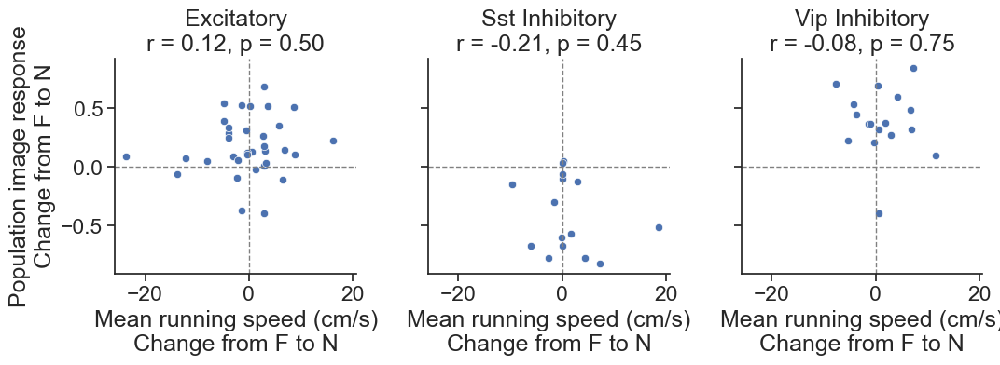

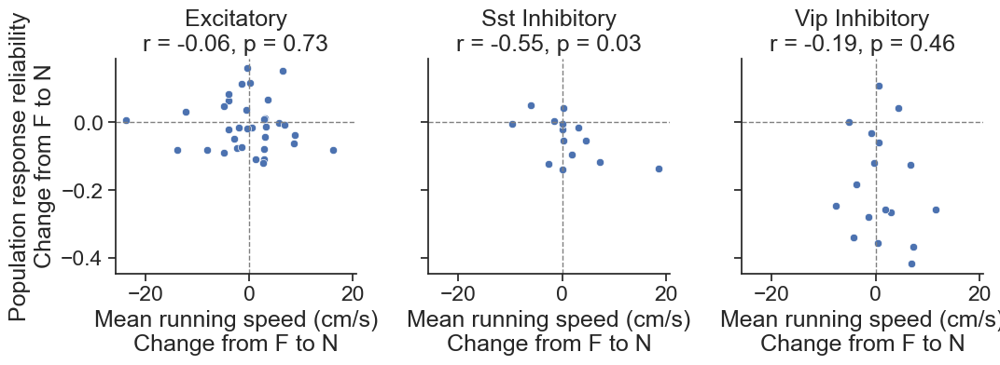

In [97]:
# Plot change in activity vs. change in running speed
behavior_metric = 'mean_run_speed_images'
behavior_label = 'Mean running speed (cm/s)'

suptitle = 'Change in neural activity vs change in running speed from familiar to novel sessions'


cell_metric = 'mean_response_pref_image'
metric_label = 'Population image response'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, running_metrics_images, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, show_fit=False, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)



cell_metric = 'reliability_pref_image'
metric_label = 'Population response reliability'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, running_metrics_images, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric,
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)

##### Pupil diameter

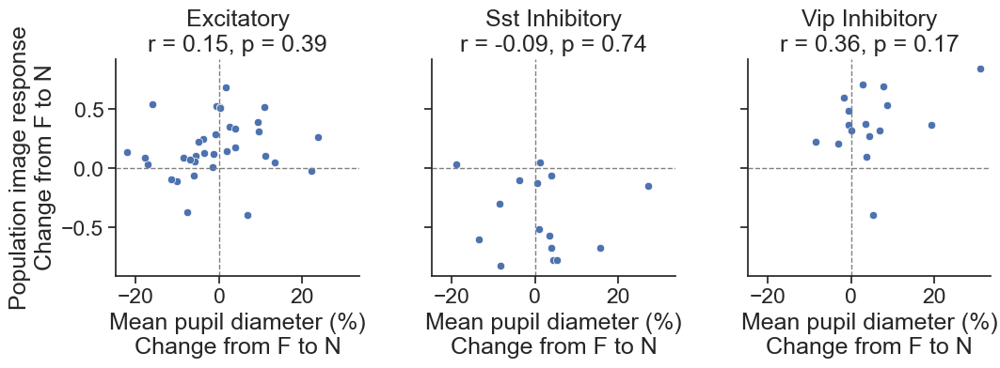

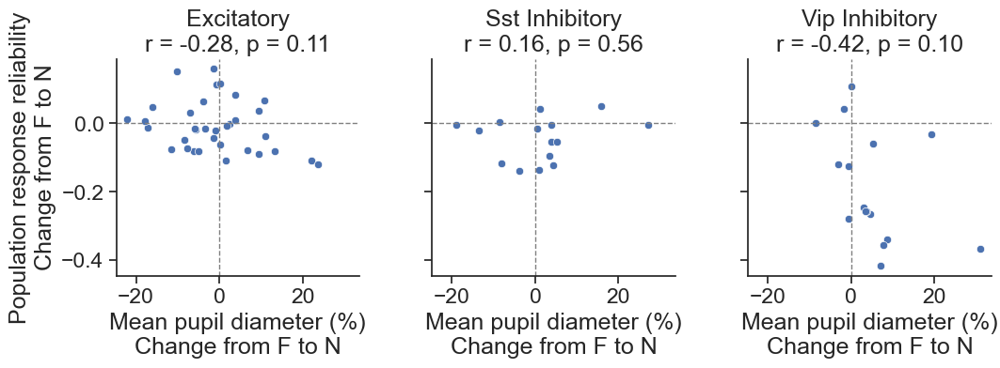

In [98]:
behavior_metric = 'mean_pupil_width_images'
behavior_label = 'Mean pupil diameter (%)'
suptitle = 'Change in neural activity vs change in pupil diameter from familiar to novel sessions'

cell_metric = 'mean_response_pref_image'
metric_label = 'Population image response'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, pupil_metrics_images, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)



cell_metric = 'reliability_pref_image'
metric_label = 'Population response reliability'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, pupil_metrics_images, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)

##### d-prime

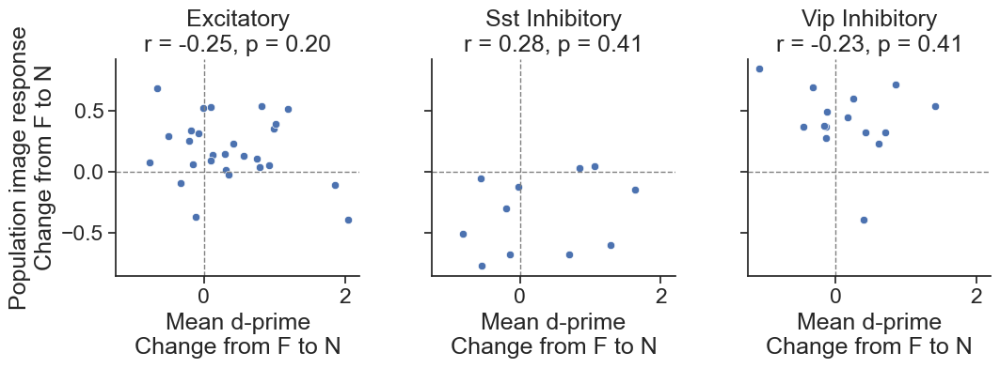

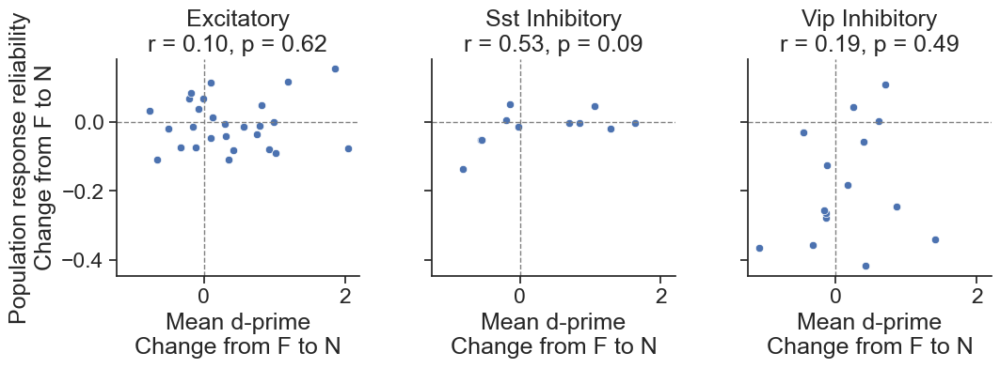

In [99]:
behavior_metric = 'mean_dprime_engaged'
behavior_label = 'Mean d-prime'
suptitle = 'Change in neural activity vs change in task performanced from familiar to novel sessions'

# metrics_table['mean_pupil_width_images'] = metrics_table['mean_pupil_width_images']*100


cell_metric = 'mean_response_pref_image'
metric_label = 'Population image response'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, behavior_stats_sdk, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)



cell_metric = 'reliability_pref_image'
metric_label = 'Population response reliability'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, behavior_stats_sdk, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)

In [100]:
#### For changes instead of images

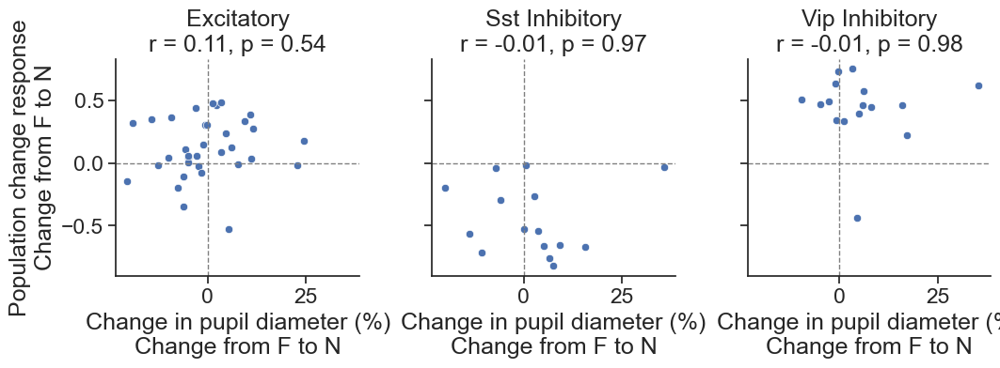

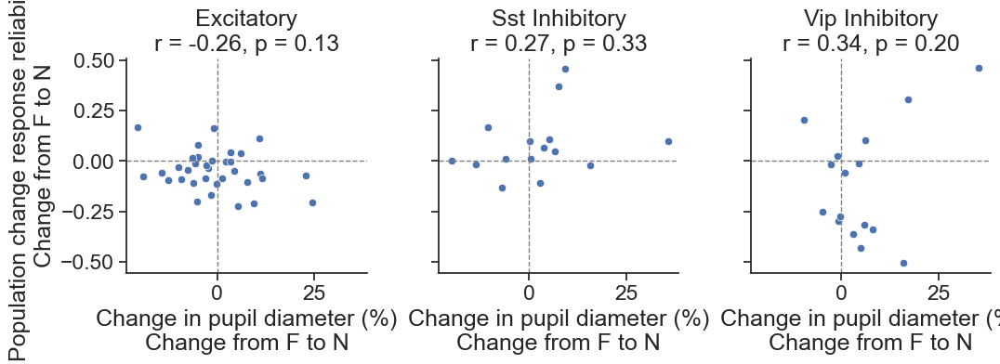

In [101]:

behavior_metric = 'mean_pupil_width_changes'
behavior_label = 'Change in pupil diameter (%)'

cell_metric = 'mean_response_changes'
metric_label = 'Population change response'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, pupil_metrics_changes, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)



cell_metric = 'reliability_changes'
metric_label = 'Population change response reliability'

metric_data = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
    metrics_table, pupil_metrics_changes, platform_experiments,
    behavior_metric, cell_metric, avg_diff_per_cell=False)

ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
    metric_data, behavior_metric, cell_metric, 
    metric_label=metric_label, behavior_label=behavior_label, suptitle=None,
    save_dir=save_dir)

## Figure S9 composite — Within-session and within-mouse comparison of physiology and behavior

Assemble the running-activity-correlation control panels into one multi-panel figure
matching the manuscript layout:

- **A / B** single Vip example cell: activity-vs-running scatter (Pearson r) | run-vs-stationary event trace (RMI). Both from the same cell.
- **C / D** population distributions across experience levels (cell type as hue): activity-running correlation | running modulation index.
- **E / F / G** change in population image response (Familiar to Novel) vs change in behavior, one column per cell type: d-prime | running speed | pupil diameter.

Built with the `panel_grid` composite-figure helpers. Inputs are recomputed here from
stable variables because `metrics_table` is reused for two different tables earlier in the
notebook (running metrics, then filtered-events cell metrics).

In [102]:
stats_capture_start()  # reset collector + (re)install hooks for this composite

OVERLAP: axes of panel "D" intrudes into panel "D" (top gutter)


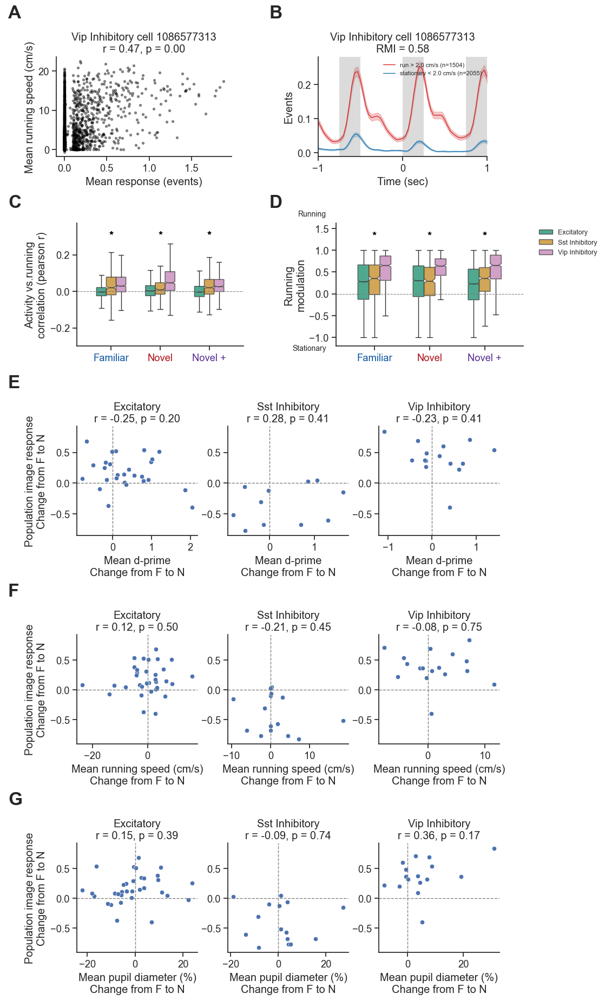

In [103]:
import os
# ============ Composite figure ============
import matplotlib.pyplot as plt
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, check_label_overlap, snug_left_to_gutter, snug_top_to_gutter)

sns.set_context('notebook', font_scale=1.2, rc={'lines.markeredgewidth': 2})

# --- Rebuild the running-metrics merged table (cell 12's `metrics_table` was later
#     overwritten by the filtered-events table) for panels C/D and the example lookup ---
running_mt = running_metrics_table.merge(
    platform_experiments[['cell_type', 'experience_level']].reset_index(),
    on='ophys_experiment_id', how='left')

# --- Example Vip cell for panels A (scatter) & B (run/stationary trace). Defaults to the
#     published example; set EXAMPLE_CSID to use a different cell. ---
EXAMPLE_CSID = 1086577313
_match = running_mt[running_mt.cell_specimen_id == EXAMPLE_CSID]
if len(_match) == 0:
    print(f'EXAMPLE_CSID {EXAMPLE_CSID} not in running metrics; using notebook RMI example')
    EXAMPLE_CSID, EXAMPLE_OEID, EXAMPLE_RMI = mt_example_csid, mt_example_oeid, mt_example_rmi
else:
    _ex = _match.iloc[0]
    EXAMPLE_OEID = int(_ex['ophys_experiment_id'])
    EXAMPLE_RMI = float(_ex['running_modulation_index'])

# reuse an sdf already loaded above if it contains the cell, else load it
example_sdf = None
for _cand in ('mt_corr_example_sdf', 'mt_example_sdf'):
    _s = globals().get(_cand)
    if _s is not None and EXAMPLE_CSID in _s['cell_specimen_id'].values:
        example_sdf = _s
        break
if example_sdf is None:
    _ds = loading.get_ophys_dataset(EXAMPLE_OEID)
    example_sdf = loading.get_stimulus_response_df(
        _ds, time_window=[-2, 2.1], interpolate=True, output_sampling_rate=30,
        data_type='events', event_type='all', load_from_file=True)

# --- Panels E/F/G: change in population image response vs change in behavior ---
#     `metrics_table` here is the filtered-events cell-metrics table built above.
cell_metric = 'mean_response_pref_image'
metric_label = 'Population image response'
efg = {
    'E': ('mean_dprime_engaged',   'Mean d-prime',              behavior_stats_sdk),
    'F': ('mean_run_speed_images', 'Mean running speed (cm/s)', running_metrics_images),
    'G': ('mean_pupil_width_images','Mean pupil diameter (%)',     pupil_metrics_images),
}

# --- Layout (portrait; derived to match the manuscript figure) ---
FIG_W, FIG_H = 11.0, 17.5
REGIONS = {
    'A': [0.025, 0.40,  0.005, 0.165],
    'B': [0.46,  0.835, 0.005, 0.165],   # same width as A; nudged left
    'C': [0.025, 0.42,  0.205, 0.365],   # right edge trimmed so 'Novel +' clears D's gutter
    'D': [0.46,  0.89,  0.205, 0.365],   # wide; nudged left; legend spills into right margin
    'E': [0.025, 0.85,  0.395, 0.560],   # moved up to tighten the C/D -> E gap
    'F': [0.025, 0.85,  0.615, 0.780],
    'G': [0.025, 0.85,  0.835, 1.000],
}

fig = plt.figure(figsize=(FIG_W, FIG_H))
fig_setup(fig)
stats_dir = os.path.join(save_dir, 'composite', 'figure_S9_stats') if save_dir else None
# Disable any active layout engine so it can't revert the manual snug positions on redraw.
try:
    fig.set_layout_engine('none')
except Exception:
    fig.set_constrained_layout(False); fig.set_tight_layout(False)

# A + B: single-cell example (scatter + trace), same cell
axA = panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', has_title=True, title_lines=2)
axB = panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', has_title=True, title_lines=2)
pse.plot_running_example_cell(example_sdf, EXAMPLE_CSID, 'Vip Inhibitory', EXAMPLE_RMI,
                              axes=[axA, axB])

# C: activity-running correlation (experience on x, cell type hue)
axC = panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C')
ppf.plot_correlation_distribution_single_axis(
    running_mt, metric='activity_running_corr',
    x_col='experience_level', hue_col='cell_type', ylims=(-0.3, 0.3), ax=axC, stats_dir=stats_dir)
if axC.get_legend() is not None:
    axC.get_legend().remove()                 # single legend lives next to D
                                              # C keeps the function's full, colored experience-level labels (matches D)

# D: running modulation index (experience on x, cell type hue) + legend
axD = panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D')
ppf.plot_rmi_distribution_single_axis(
    running_mt, metric='running_modulation_index', ylims=(-1.2, 1.3),
    x_col='experience_level', hue_col='cell_type', ax=axD, stats_dir=stats_dir)
# lift the 'Running' annotation above the top y-tick labels
for _t in axD.texts:
    if _t.get_text() == 'Running':
        _t.set_position((-0.05, 1.04)); _t.set_va('bottom')

# E/F/G: one column per cell type; y-label only on leftmost
for _lbl, (_bm, _blab, _btbl) in efg.items():
    _row = panel(fig, REGIONS[_lbl][:2], REGIONS[_lbl][2:], _lbl,
                 has_title=True, title_lines=2, dim=(1, 3),
                 sharex=True, sharey=True, wspace=0.25)
    _md = ppf.get_change_in_behavior_and_average_cell_metric_across_mice(
        metrics_table, _btbl, platform_experiments, _bm, cell_metric,
        avg_diff_per_cell=False)
    ppf.plot_correlation_of_behavior_and_cell_metrics_delta(
        _md, _bm, cell_metric, metric_label=metric_label, behavior_label=_blab, ax=_row)
    _row[1].set_ylabel(''); _row[2].set_ylabel('')

sns.despine(fig=fig)
# Fill each panel: pull plots' top-left snug against their letter gutter (skill rule).
snug_left_to_gutter(fig, REGIONS)                                # all panels -> left gutter
snug_top_to_gutter(fig, REGIONS, only=['A', 'B', 'E', 'F', 'G'])  # titled panels -> top gutter
check_label_overlap(fig, REGIONS)

# (Removed whole-axes rasterization: with bbox_inches='tight' it misplaced/shrank the raster
#  layer in the saved PDF and made all axis text non-editable. S9 data is light enough for vector.)
utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_S9_composite', formats=['.png', '.pdf'])
plt.show()


In [104]:
stats = stats_capture_save(save_dir, 'composite', 'figure_S9_composite_stats')


stats capture: wrote 36 rows from 8 panel stat-tables -> /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/figure_3_supplemental/composite/figure_S9_composite_stats.csv
